# g3 · Clasificación multiclase (Eucalyptus): notebook final

Predecimos la **clase de utilidad** de una parcela de eucalipto para conservar el suelo (`none` < `low` < `average` < `good` < `best`). Este notebook junta, en orden, todos los notebooks del proyecto: problema y split, EDA, los cuatro modelos y las conclusiones. Repo: [https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase](https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase).

**Cómo usarlo**
- Ya está ejecutado: se puede leer sin ejecutar nada.
- Para ejecutarlo en Colab: *Entorno de ejecución > Ejecutar todas*. La primera celda de código descarga el repo e instala los requisitos.
- Los enlaces del índice saltan a cada sección en Colab. En Jupyter o VS Code, usa el panel de esquema (*Outline*) o el índice lateral.

**Atajos**
- [Conclusión del EDA](#scrollTo=nb01-18)
- [Tabla comparativa de los modelos](#scrollTo=nb06-3)
- [Elección del modelo ganador](#scrollTo=nb06-5)
- [Evaluación final en test](#scrollTo=nb06-6)
- [Requisitos del Nivel Esencial](#scrollTo=nb06-10)
- [Conclusiones para negocio](#scrollTo=nb06-11)

## Índice
1. **[Proyecto de clasificación multiclase: definición del problema](#scrollTo=nb00)** · `00_general.ipynb`
    - [0. Definir el problema](#scrollTo=nb00-1)
2. **[EDA: conjunto de datos Eucalyptus](#scrollTo=nb01)** · `01_eda.ipynb`
    - [Datos y split](#scrollTo=nb01-1)
    - [📥 Carga de datos (conjunto de entrenamiento)](#scrollTo=nb01-2)
    - [1. Forma y tipos](#scrollTo=nb01-3)
    - [2. Resumen de variables numéricas](#scrollTo=nb01-4)
    - [3. Resumen de variables categóricas](#scrollTo=nb01-5)
    - [4. Nombres de columnas](#scrollTo=nb01-6)
    - [🔍 Exploración (conjunto de entrenamiento)](#scrollTo=nb01-7)
    - [1. Valores ausentes](#scrollTo=nb01-8)
    - [2. Duplicados](#scrollTo=nb01-9)
    - [3. Valores extremos](#scrollTo=nb01-10)
    - [4. Variable objetivo: balance de clases](#scrollTo=nb01-11)
    - [5. Distribuciones de las variables numéricas](#scrollTo=nb01-12)
    - [6. Variables categóricas: cardinalidad](#scrollTo=nb01-13)
    - [7. Relación de cada variable con la clase](#scrollTo=nb01-14)
    - [8. Correlaciones](#scrollTo=nb01-15)
    - [9. Efecto de las parcelas sin medidas en el reparto de clases](#scrollTo=nb01-16)
    - [10. Limpieza común y exportación de los datos](#scrollTo=nb01-17)
    - [📝 Conclusión del EDA y traspaso al equipo](#scrollTo=nb01-18)
3. **[02 · Regresión logística: clase de utilidad de una parcela](#scrollTo=nb02)** · `02_regresion_logistica.ipynb`
    - [1. Entorno y funciones comunes](#scrollTo=nb02-1)
    - [2. Datos compartidos](#scrollTo=nb02-2)
    - [3. Preprocesado y decisiones](#scrollTo=nb02-3)
    - [4. Baseline común](#scrollTo=nb02-4)
    - [5. Selección de hiperparámetros, solo con entrenamiento](#scrollTo=nb02-5)
    - [6. Validación cruzada común y por sitio — #52](#scrollTo=nb02-6)
    - [7. Evaluación en validación y overfitting — #53](#scrollTo=nb02-7)
    - [8. Interpretación por coeficientes — #54](#scrollTo=nb02-8)
    - [9. Análisis de errores — #54](#scrollTo=nb02-9)
    - [10. Exportación y recarga en una sesión nueva — #54](#scrollTo=nb02-10)
    - [11. Conclusión y entrega común](#scrollTo=nb02-11)
4. **[Modelo 2: árbol de decisión](#scrollTo=nb03)** · `03_arbol_decision.ipynb`
    - [Pasos 0, 1 y 2: problema, split y EDA (ya hechos)](#scrollTo=nb03-1)
    - [Paso 3: preprocesado](#scrollTo=nb03-2)
    - [Paso 4: feature engineering y selección](#scrollTo=nb03-3)
    - [Paso 5: baseline (el mínimo a superar)](#scrollTo=nb03-4)
    - [Paso 6: entrenamiento y validación](#scrollTo=nb03-5)
    - [Paso 7: ajuste de hiperparámetros (tuning)](#scrollTo=nb03-6)
    - [Paso 8: evaluación con `val.csv`](#scrollTo=nb03-7)
    - [Paso 9: análisis de errores e interpretación](#scrollTo=nb03-8)
    - [Paso 10: guardar el modelo (despliegue)](#scrollTo=nb03-9)
    - [Conclusión](#scrollTo=nb03-10)
5. **[Modelo SVM: utilidad de las parcelas de eucalipto](#scrollTo=nb04)** · `04_svm.ipynb`
    - [Apunte Elena: el cuento del modelo](#scrollTo=nb04-1)
    - [Pasos 0, 1 y 2: problema, split y EDA (ya hechos)](#scrollTo=nb04-2)
    - [Paso 1 (bis): cargar los datos con `comun.py`](#scrollTo=nb04-3)
    - [Paso 3: preprocesado](#scrollTo=nb04-4)
    - [Paso 4: baseline (el mínimo a superar)](#scrollTo=nb04-5)
    - [Paso 5: entrenamiento y validación cruzada](#scrollTo=nb04-6)
    - [Paso 6: ajuste de hiperparámetros](#scrollTo=nb04-7)
    - [Paso 7: evaluación con `val.csv`](#scrollTo=nb04-8)
    - [Paso 8: interpretación](#scrollTo=nb04-9)
    - [Paso 9: guardar el modelo](#scrollTo=nb04-10)
    - [Conclusión](#scrollTo=nb04-11)
6. **[Modelo KNN: utilidad de las parcelas de eucalipto](#scrollTo=nb05)** · `05_knn.ipynb`
    - [1. Carga de datos y preparación del pipeline](#scrollTo=nb05-1)
    - [2. Baseline: el mínimo a superar](#scrollTo=nb05-2)
    - [3. Validación cruzada y elección de hiperparámetros](#scrollTo=nb05-3)
    - [4. Métricas en validación](#scrollTo=nb05-4)
    - [5. Control de overfitting](#scrollTo=nb05-5)
    - [6. Interpretación: importancia de variables y errores](#scrollTo=nb05-6)
    - [7. Guardar el pipeline y comprobar que se puede cargar](#scrollTo=nb05-7)
    - [8. Conclusión](#scrollTo=nb05-8)
7. **[Conclusiones: comparación de modelos, ganador y evaluación en test](#scrollTo=nb06)** · `06_conclusiones.ipynb`
    - [Paso 1: cargar los resultados de los cuatro modelos](#scrollTo=nb06-1)
    - [Paso 2: el Dummy, la referencia común](#scrollTo=nb06-2)
    - [Paso 3: tabla comparativa (subtarea #64)](#scrollTo=nb06-3)
    - [Paso 4: la comparación en gráficos](#scrollTo=nb06-4)
    - [Paso 5: elegir el modelo ganador](#scrollTo=nb06-5)
    - [Paso 6: evaluación final en test (subtarea #65)](#scrollTo=nb06-6)
    - [Paso 7: ¿se parece el test a la validación?](#scrollTo=nb06-7)
    - [Paso 8: ¿rinde igual en todos los sitios?](#scrollTo=nb06-8)
    - [Paso 9: análisis de errores e interpretación del ganador](#scrollTo=nb06-9)
    - [Paso 10: requisitos del Nivel Esencial](#scrollTo=nb06-10)
    - [Conclusiones](#scrollTo=nb06-11)

In [1]:
# Preparación para Google Colab (en local no hace nada)
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.exists("comun.py"):
    carpeta = "/content/g3-Clasificacion-Multiclase"
    if not os.path.exists(carpeta):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase", carpeta], check=True)
    os.chdir(carpeta)
    sys.path.insert(0, carpeta)
    instalado = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"]
    )
    if instalado.returncode != 0:
        print("⚠️ No se han podido instalar todas las versiones fijadas; "
              "se usan las de Colab.")
    # Si Colab ya tenía cargada otra versión de una librería, hay que reiniciar
    from importlib.metadata import version
    librerias = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
                  "scipy": "scipy", "matplotlib": "matplotlib"}
    if any(modulo in sys.modules and sys.modules[modulo].__version__ != version(paquete)
           for modulo, paquete in librerias.items()):
        print("🔄 Versiones nuevas instaladas: se reinicia la sesión. "
              "Vuelve a ejecutar todo (Entorno de ejecución > Ejecutar todas).")
        os.kill(os.getpid(), 9)

# Proyecto de clasificación multiclase: definición del problema

Paso 0 de la *Guía de un proyecto de clasificación en ML*: qué problema resolvemos y cómo sabremos si lo hemos resuelto. El resto de pasos vive en los demás notebooks: los datos y el split están en `comun.py` y se usan en `01_eda.ipynb`; cada modelo, en el suyo (`02` a `05`); la comparación y el test, en `06_conclusiones.ipynb`.

## 0. Definir el problema

- **Contexto:** conjunto *Eucalyptus Soil Conservation* (Bruce Bulloch, colección WEKA, OpenML id=188): 736 filas y 19 variables de ensayos de semillas de eucalipto en la Isla Norte de Nueva Zelanda. El objetivo original era determinar qué lotes de semillas son mejores para la conservación del suelo en colinas de clima estacionalmente seco.
- **Tarea:** clasificación multiclase, 5 clases.
- **Variable objetivo:** `Utility` (utilidad del lote): `good` 214 (29,1 %), `none` 180 (24,5 %), `average` 130 (17,7 %), `low` 107 (14,5 %), `best` 105 (14,3 %). Es una escala ordenada: `none` < `low` < `average` < `good` < `best`.
- **Métrica de éxito:** F1 macro (trata las 5 clases por igual) más accuracy global; además precision, recall y F1 por clase.
- **Baseline a superar:** `DummyClassifier` (predice siempre la clase mayoritaria, `good`). Un modelo solo vale si lo supera con claridad.
- **Error más costoso:** ninguna clase en particular; se tratan todas las confusiones por igual, pero en el análisis de errores se marcan las más alejadas en la escala (p. ej. `best` predicho como `none`).
- **Restricción del proyecto:** sobreajuste (gap = F1 de entrenamiento − F1 de validación, con medidas) menor de 5 puntos.
- **Límites de los datos:** los métodos de ensayo cambiaron con el tiempo, lo que puede reducir la comparabilidad entre sitios; faltan datos de supervivencia, vigor, resistencia a insectos y forma (tallo, copa, ramas), sobre todo en la estación de Morea, y no se sabe si es por muerte de las plantas o por falta de medición.
- **Uso y fuga de datos:** la predicción sirve para valorar un lote de semillas. Las medidas (supervivencia, vigor…) se toman tras plantar, así que las parcelas sin ninguna medida (todas `none`) quedan fuera del entrenamiento y se predicen `none` por regla ([ADR-0001](docs/adr/0001-excluir-parcelas-sin-medidas.md)).

# EDA: conjunto de datos Eucalyptus

> Análisis exploratorio del proyecto de clasificación multiclase. Sigue la *Guía de un proyecto de clasificación en ML* (pasos 1 y 2: split y EDA solo sobre entrenamiento). El problema, la métrica y el baseline están definidos en `00_general.ipynb`; aquí se resumen los datos y sus riesgos.

- **Datos:** *Eucalyptus Soil Conservation* (OpenML id=188, Bruce Bulloch, colección WEKA): 736 parcelas de ensayo de eucalipto en la Isla Norte de Nueva Zelanda.
- **Objetivo:** `Utility`, 5 clases ordenadas: `none` < `low` < `average` < `good` < `best`.
- **Convenciones:** idioma español; se muestra `n` junto a los porcentajes; todo el análisis usa solo el conjunto de entrenamiento.
- **Límites de los datos:** los métodos de ensayo cambiaron con el tiempo y faltan medidas en algunos sitios, sobre todo en `Mor`.

## Datos y split

In [5]:
import pandas as pd

# Librería común del equipo (comun.py, ver docs/acuerdos.md)
from comun import CLASES, MEDIDAS, cargar_openml, dividir

In [6]:
# Eucalyptus (OpenML id=188); se guarda en caché local tras la primera descarga
X, y = cargar_openml()

print(f"{X.shape[0]} filas, {X.shape[1]} variables")
print(y.value_counts())

736 filas, 19 variables
Utility
good       214
none       180
average    130
low        107
best       105
Name: count, dtype: int64


In [7]:
# Split estratificado 70/15/15. El test no se toca hasta la evaluación final (paso 8).
X_train, X_val, X_test, y_train, y_val, y_test = dividir(X, y)

print(f"train: {len(X_train)} | validación: {len(X_val)} | test: {len(X_test)}")

train: 515 | validación: 110 | test: 111


# 📥 Carga de datos (conjunto de entrenamiento)

> Entender qué contiene cada columna antes de cambiar nada.

---

### 🎯 Objetivo
Saber qué es una fila, cuántas hay, qué tipo tiene cada variable y qué parece sospechoso, trabajando solo con `X_train`.

### 📥 Entrada
`X_train` e `y_train` (70 % de los datos, estratificado), sin modificar. Una fila es una parcela de ensayo: un lote de semillas (`Sp`) en un sitio (`Abbrev`) y una réplica (`Rep`).

### 🛠️ Qué hacemos
1. Configurar importaciones y estilo de gráficos.
2. Revisar forma y tipos (`shape`, `info`).
3. Resumen estadístico de las variables numéricas y categóricas (`describe`).
4. Revisar los nombres de las columnas.

### 📝 Observaciones
- `X_train` tiene 515 filas y 19 variables: 14 numéricas y 5 categóricas (`Abbrev`, `Locality`, `Map_Ref`, `Latitude`, `Sp`). Los nombres de columna no tienen espacios sobrantes.
- Una fila es una parcela de ensayo (lote de semillas en un sitio y una réplica).
- Valores sospechosos para investigar primero en la exploración:
  - `DBH`: mediana 14, pero máximo 42085 (imposible para el diámetro de un árbol).
  - Valores ausentes: `Surv` 68 de 515 (13 %); `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm` y `Brnch_Fm` 46 de 515 cada una (9 %). Hay que comprobar si son las mismas filas.
- Otros valores a vigilar: `Rep` (máximo 22, mediana 2) y `PMCno` (mínimo 1, mediana 2088).

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Forma y tipos

In [9]:
print(f"X_train: {X_train.shape[0]} filas, {X_train.shape[1]} variables")
X_train.info()

X_train: 515 filas, 19 variables
<class 'pandas.DataFrame'>
Index: 515 entries, 522 to 352
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Abbrev    515 non-null    category
 1   Rep       515 non-null    int64   
 2   Locality  515 non-null    category
 3   Map_Ref   515 non-null    category
 4   Latitude  515 non-null    category
 5   Altitude  515 non-null    int64   
 6   Rainfall  515 non-null    int64   
 7   Frosts    515 non-null    int64   
 8   Year      515 non-null    int64   
 9   Sp        515 non-null    category
 10  PMCno     510 non-null    float64 
 11  DBH       515 non-null    float64 
 12  Ht        515 non-null    float64 
 13  Surv      447 non-null    float64 
 14  Vig       469 non-null    float64 
 15  Ins_res   469 non-null    float64 
 16  Stem_Fm   469 non-null    float64 
 17  Crown_Fm  469 non-null    float64 
 18  Brnch_Fm  469 non-null    float64 
dtypes: category(5), float64(9), int

## 2. Resumen de variables numéricas

In [10]:
display(Markdown("**Variables numéricas: estadísticos**"))
X_train.describe().T

**Variables numéricas: estadísticos**

,count,mean,std,min,25%,50%,75%,max
Rep,515.0,2.048544,1.204552,1.00,1.000,2.0,3.00,22.00
Altitude,515.0,170.893204,58.071959,70.00,150.000,160.0,180.00,300.00
Rainfall,515.0,1097.650485,147.830334,850.00,1000.000,1080.0,1200.00,1750.00
Frosts,515.0,-2.592233,0.491897,-3.00,-3.000,-3.0,-2.00,-2.00
Year,515.0,1982.073786,1.588625,1980.00,1981.000,1982.0,1983.00,1986.00
PMCno,510.0,2049.325490,622.010742,1.00,1523.000,2088.0,2568.00,3275.00
DBH,515.0,97.061965,1853.833615,0.58,7.890,14.0,20.43,42085.00
Ht,515.0,9.184350,4.059242,1.12,5.945,9.0,11.98,21.79
Surv,447.0,59.825503,29.859889,1.50,38.000,63.0,88.00,100.00
Vig,469.0,3.036461,1.011796,0.50,2.500,3.0,4.00,5.00


## 3. Resumen de variables categóricas

In [11]:
display(Markdown("**Variables categóricas: número de valores distintos y más frecuente**"))
X_train.select_dtypes("category").describe().T

**Variables categóricas: número de valores distintos y más frecuente**

,count,unique,top,freq
Abbrev,515,16,Wak,56
Locality,515,8,South_Wairarapa,146
Map_Ref,515,14,N158_344/626,102
Latitude,515,12,40__57,133
Sp,515,27,re,61


## 4. Nombres de columnas

In [12]:
espacios = [c for c in X_train.columns if c != c.strip()]
print("Columnas con espacios sobrantes:", espacios or "ninguna")

Columnas con espacios sobrantes: ninguna


# 🔍 Exploración (conjunto de entrenamiento)

> Detectar problemas con evidencia. Las decisiones se toman en el preprocesado, no aquí.

---

### 🎯 Objetivo
Encontrar valores ausentes, duplicados, valores extremos y posibles fugas de información (*data leakage*) en `X_train`.

### 📥 Entrada
`X_train` e `y_train`, sin modificar.

### 🛠️ Qué hacemos
1. Valores ausentes: cuántos hay, en qué filas y qué relación tienen con el sitio y con la clase.
2. Duplicados.
3. Valores extremos (regla del IQR y revisión de `DBH`).

### 📊 Lista de comprobación de gráficos
Cada gráfico lleva título, ejes con nombre y leyenda si hay más de una serie.

### 📝 Observaciones
- **Ausentes:** 46 filas (sitios `Mor` 41 y `Wen` 5, completos) no tienen ninguna de las seis medidas (`Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm`). Las 46 tienen `Utility = none` (46 de 46), frente al 17 % de `none` en las filas con datos. Se interpreta como parcelas fallidas o no medidas: la ausencia señala la clase, y por eso es un riesgo de *data leakage*.
- **Ausentes en `Surv`:** otras 22 filas, todas del sitio `Cly`, solo carecen de `Surv` (clases: good 11, best 5, low 5, average 1, none 0). Se interpreta como supervivencia no registrada en ese sitio, sin relación con la clase.
- **Ausentes en `PMCno`:** 5 filas (1 %), sin revisar todavía.
- **Duplicados:** 0 filas duplicadas.
- **Extremos:** `DBH` tiene un valor de 42085 (fila 603, sitio `Paw`) frente a un máximo de 53,86 en las otras 514 filas; se considera un error de registro. Fuera de 1,5 × IQR hay 13 filas en `DBH`, 126 en `Altitude` (IQR muy estrecho, valores casi categóricos), 26 en `Brnch_Fm`, 8 en `Crown_Fm` y pocas en el resto.
- **Balance de clases:** `good` 29,1 %, `none` 24,5 %, `average` 17,7 %, `low` 14,6 %, `best` 14,2 % (desbalance moderado, sin clase dominante).
- **Asimetría:** `DBH` (22,7, por el valor 42085) y `Rep` (8,8) muy asimétricas; el resto, moderadas (|skew| < 1,1).
- **Fuga de información (*leakage*):** `Vig` es la variable más ligada a la clase (Spearman 0,79 con la escala ordenada; con `Vig` ≥ 3,5, 152 de 176 filas son `good` o `best`; con `Vig` ≤ 2, ninguna de 104). Se considera un predictor legítimo (medición de campo), a confirmar que estará disponible al predecir. Le siguen `Ins_res` y `Stem_Fm` (0,46) y `Ht` (0,45).
- **Efecto del sitio:** `Locality`, `Map_Ref`, `Latitude`, `Altitude`, `Rainfall`, `Frosts` y `Year` toman un único valor por sitio (`Abbrev`), por lo que describen el mismo sitio de varias formas. La clase depende mucho del sitio (`Mor` 41 de 41 `none`; `Wen` y `WSh` tienen solo 5 y 2 filas). Hay que tenerlo presente al validar, para que filas del mismo sitio no queden repartidas de forma engañosa entre entrenamiento y validación.
- **Redundancia entre variables:** `DBH`–`Ht` 0,82 (ambas miden tamaño) y `Stem_Fm`, `Crown_Fm`, `Brnch_Fm` entre 0,56 y 0,70.
- **Parcelas sin medidas:** al quitar las 46 filas sin medidas, `none` pasa de 126 (24,5 %) a 80 de 469 (17,1 %) y el reparto de clases queda más parejo (de 32,0 % `good` a 15,6 % `best`).
- **Para el preprocesado:** decidir cómo tratar el bloque de ausentes de `Mor`/`Wen` y `Cly`, corregir o eliminar `DBH = 42085`, reducir las variables de sitio y las redundantes (`DBH`/`Ht`, las tres de forma) y confirmar la disponibilidad de `Surv`, `Vig`, etc. al predecir.

## 1. Valores ausentes

In [13]:
ausentes = X_train.isna().sum()
ausentes = ausentes[ausentes > 0]
tabla = pd.DataFrame({
    "ausentes": ausentes,
    "% de las filas": (ausentes / len(X_train) * 100).round(1),
})
display(Markdown(f"**Columnas con valores ausentes (n = {len(X_train)})**"))
tabla

**Columnas con valores ausentes (n = 515)**

,ausentes,% de las filas
PMCno,5,1.0
Surv,68,13.2
Vig,46,8.9
Ins_res,46,8.9
Stem_Fm,46,8.9
Crown_Fm,46,8.9
Brnch_Fm,46,8.9


In [14]:
# ¿Faltan las mismas filas en todas las variables de medición?
display(Markdown("**Patrones de ausencia (True = falta) y número de filas**"))
X_train[MEDIDAS].isna().value_counts()

**Patrones de ausencia (True = falta) y número de filas**

Surv   Vig    Ins_res  Stem_Fm  Crown_Fm  Brnch_Fm
False  False  False    False    False     False       447
True   True   True     True     True      True         46
       False  False    False    False     False        22
Name: count, dtype: int64

In [15]:
# ¿Dónde faltan? Filas con ausencias por sitio (solo sitios afectados)
por_sitio = X_train[MEDIDAS].isna().groupby(X_train["Abbrev"], observed=True).sum()
por_sitio["n_filas"] = X_train["Abbrev"].value_counts()
display(Markdown("**Ausencias por sitio (`Abbrev`)**"))
por_sitio[por_sitio[MEDIDAS].sum(axis=1) > 0]

**Ausencias por sitio (`Abbrev`)**

,Surv,Vig,Ins_res,Stem_Fm,Crown_Fm,Brnch_Fm,n_filas
Abbrev,,,,,,,
Cly,22,0,0,0,0,0,22
Mor,41,41,41,41,41,41,41
Wen,5,5,5,5,5,5,5


In [16]:
# ¿Qué clase tienen las filas con ausencias?
falta_vig = X_train["Vig"].isna()
display(Markdown("**Clase (`Utility`) de las filas SIN `Vig` (n = {})**".format(falta_vig.sum())))
display(y_train[falta_vig].value_counts())
display(Markdown("**Clase de las filas CON `Vig` (n = {}), en %**".format((~falta_vig).sum())))
(y_train[~falta_vig].value_counts(normalize=True) * 100).round(1)

**Clase (`Utility`) de las filas SIN `Vig` (n = 46)**

Utility
none       46
average     0
best        0
good        0
low         0
Name: count, dtype: int64

**Clase de las filas CON `Vig` (n = 469), en %**

Utility
good       32.0
average    19.4
none       17.1
low        16.0
best       15.6
Name: proportion, dtype: float64

## 2. Duplicados

In [17]:
print("Filas duplicadas en X_train:", X_train.duplicated().sum())

Filas duplicadas en X_train: 0


## 3. Valores extremos

In [18]:
numericas = X_train.select_dtypes("number").columns
q1, q3 = X_train[numericas].quantile(0.25), X_train[numericas].quantile(0.75)
iqr = q3 - q1
fuera = ((X_train[numericas] < q1 - 1.5 * iqr) | (X_train[numericas] > q3 + 1.5 * iqr)).sum()
display(Markdown("**Filas fuera de 1,5 × IQR por variable numérica (n = {})**".format(len(X_train))))
pd.DataFrame({"fuera de IQR": fuera, "IQR": iqr}).query("`fuera de IQR` > 0")

**Filas fuera de 1,5 × IQR por variable numérica (n = 515)**

,fuera de IQR,IQR
Rep,1,2.000
Altitude,126,30.000
Rainfall,5,200.000
DBH,13,12.540
Ht,2,6.035
Ins_res,1,1.200
Stem_Fm,2,1.000
Crown_Fm,8,1.000
Brnch_Fm,26,0.800


In [19]:
display(Markdown("**Los 5 valores más altos de `DBH`**"))
X_train.nlargest(5, "DBH")[["Abbrev", "Sp", "DBH", "Ht"]]

**Los 5 valores más altos de `DBH`**

,Abbrev,Sp,DBH,Ht
603,Paw,nd,42085.00,17.05
287,K82,fa,53.86,5.01
606,Paw,ob,49.88,14.05
599,Paw,fa,49.34,16.85
375,WSp,ni,47.73,18.55


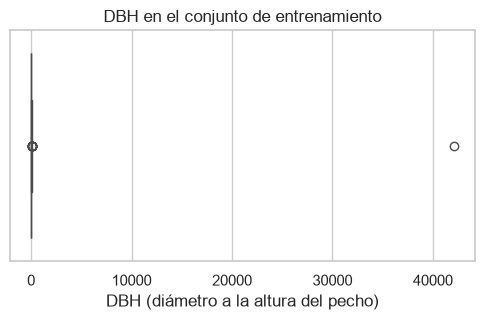

In [20]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(x=X_train["DBH"], ax=ax)
ax.set(title="DBH en el conjunto de entrenamiento", xlabel="DBH (diámetro a la altura del pecho)")
plt.show()

## 4. Variable objetivo: balance de clases

**Clases de `Utility` en entrenamiento (n = 515)**

,filas,%
Utility,,
none,126,24.5
low,75,14.6
average,91,17.7
good,150,29.1
best,73,14.2


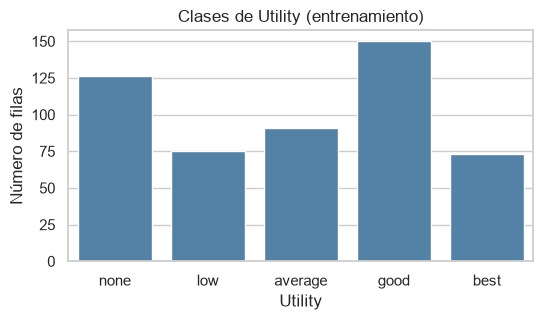

In [21]:
conteo = y_train.value_counts().reindex(CLASES)
display(Markdown(f"**Clases de `Utility` en entrenamiento (n = {len(y_train)})**"))
display(pd.DataFrame({"filas": conteo, "%": (conteo / len(y_train) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=conteo.index, y=conteo.values, ax=ax, color="steelblue")
ax.set(title="Clases de Utility (entrenamiento)", xlabel="Utility", ylabel="Número de filas")
plt.show()

## 5. Distribuciones de las variables numéricas

**Asimetría (skew) por variable numérica**

,skew
Brnch_Fm,-0.78
Crown_Fm,-0.70
Stem_Fm,-0.46
Ins_res,-0.40
Surv,-0.29
Vig,-0.25
PMCno,-0.13
Frosts,0.38
Ht,0.40
Altitude,0.59


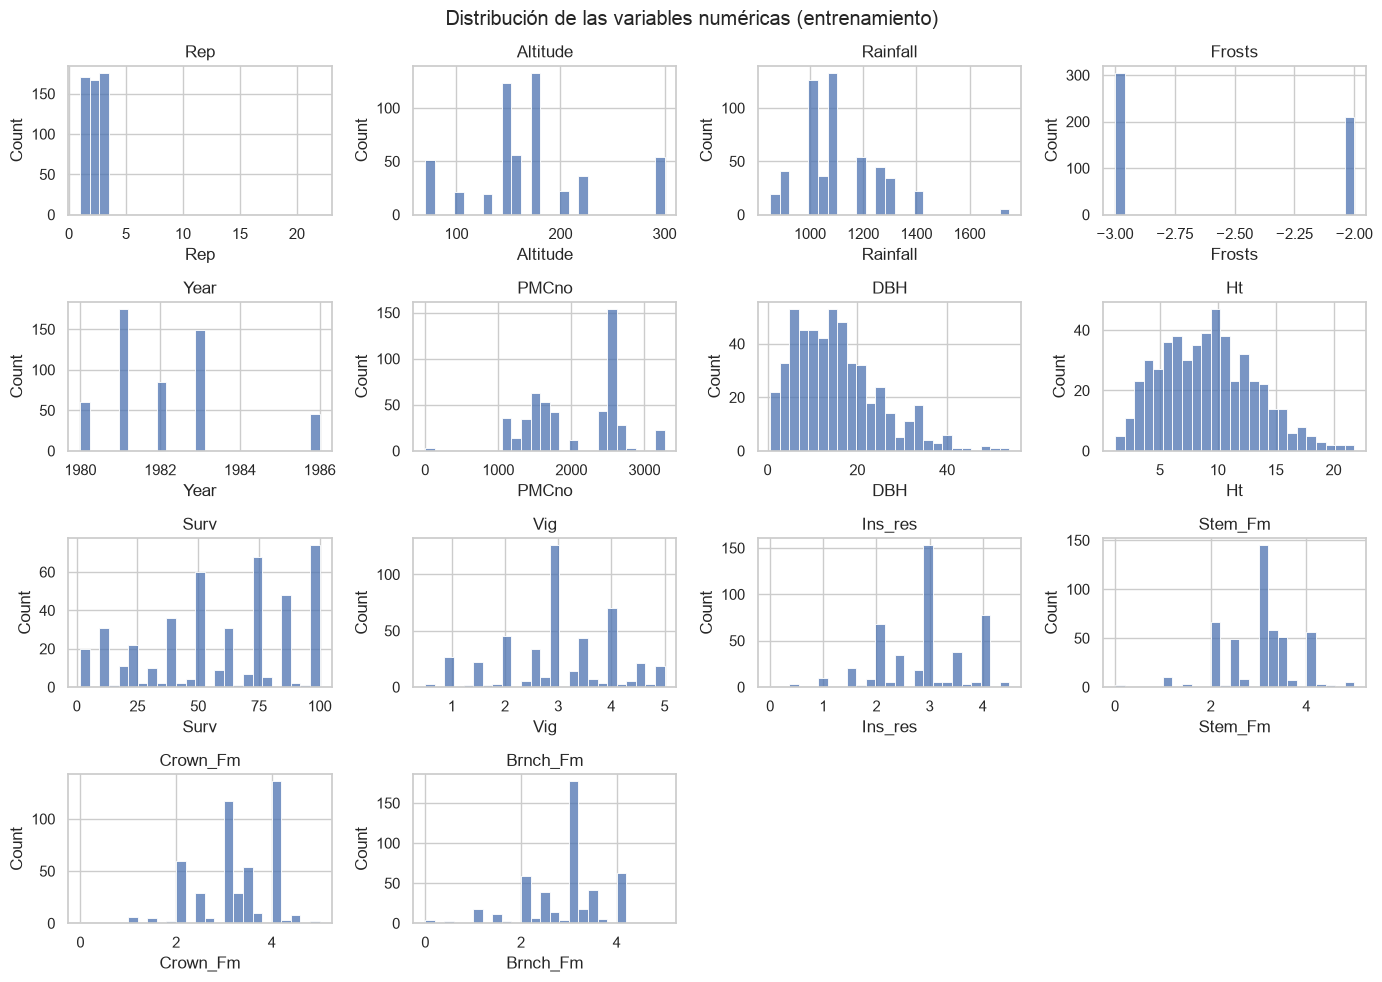

In [22]:
numericas = X_train.select_dtypes("number").columns
display(Markdown("**Asimetría (skew) por variable numérica**"))
display(X_train[numericas].skew().round(2).sort_values().to_frame("skew"))

fig, ejes = plt.subplots(4, 4, figsize=(14, 10))
for ax, col in zip(ejes.flat, numericas):
    # DBH sin el valor 42085 para que la escala sea legible (solo visualización)
    datos = X_train.loc[X_train["DBH"] < 1000, col] if col == "DBH" else X_train[col]
    sns.histplot(datos, ax=ax, bins=25)
    ax.set_title(col)
for ax in ejes.flat[len(numericas):]:
    ax.axis("off")
fig.suptitle("Distribución de las variables numéricas (entrenamiento)")
fig.tight_layout()
plt.show()

## 6. Variables categóricas: cardinalidad

In [23]:
categoricas = X_train.select_dtypes("category").columns
resumen = pd.DataFrame({
    "valores distintos": [X_train[c].nunique() for c in categoricas],
    "filas del valor más raro": [X_train[c].value_counts().min() for c in categoricas],
    "valores con menos de 5 filas": [(X_train[c].value_counts() < 5).sum() for c in categoricas],
}, index=categoricas)
display(Markdown("**Cardinalidad de las categóricas**"))
display(resumen)

# ¿Cada sitio (Abbrev) fija las demás variables de ubicación y clima?
fijadas = ["Locality", "Map_Ref", "Latitude", "Altitude", "Rainfall", "Frosts", "Year"]
display(Markdown("**Valores distintos de cada variable dentro de un mismo sitio (máximo)**"))
X_train.groupby("Abbrev", observed=True)[fijadas].nunique().max().to_frame("máx. valores por sitio")

**Cardinalidad de las categóricas**

,valores distintos,filas del valor más raro,valores con menos de 5 filas
Abbrev,16,2,1
Locality,8,5,0
Map_Ref,14,2,1
Latitude,12,5,0
Sp,27,2,4


**Valores distintos de cada variable dentro de un mismo sitio (máximo)**

,máx. valores por sitio
Locality,1
Map_Ref,1
Latitude,1
Altitude,1
Rainfall,1
Frosts,1
Year,1


## 7. Relación de cada variable con la clase

In [24]:
# Tabla de clases por sitio (el sitio condiciona mucho la clase)
tabla_sitio = pd.crosstab(X_train["Abbrev"], y_train)[CLASES]
tabla_sitio["n"] = tabla_sitio.sum(axis=1)
display(Markdown("**Filas por sitio y clase**"))
display(tabla_sitio.sort_values("n"))

**Filas por sitio y clase**

Utility,none,low,average,good,best,n
Abbrev,,,,,,
WSh,0,0,1,1,0,2
Wen,5,0,0,0,0,5
Cra,0,4,5,8,2,19
Nga,4,0,3,12,0,19
Cly,0,5,1,11,5,22
K81a,2,3,9,3,5,22
K82,8,9,9,2,3,31
K83,4,9,10,8,3,34
Paw,3,2,4,15,10,34


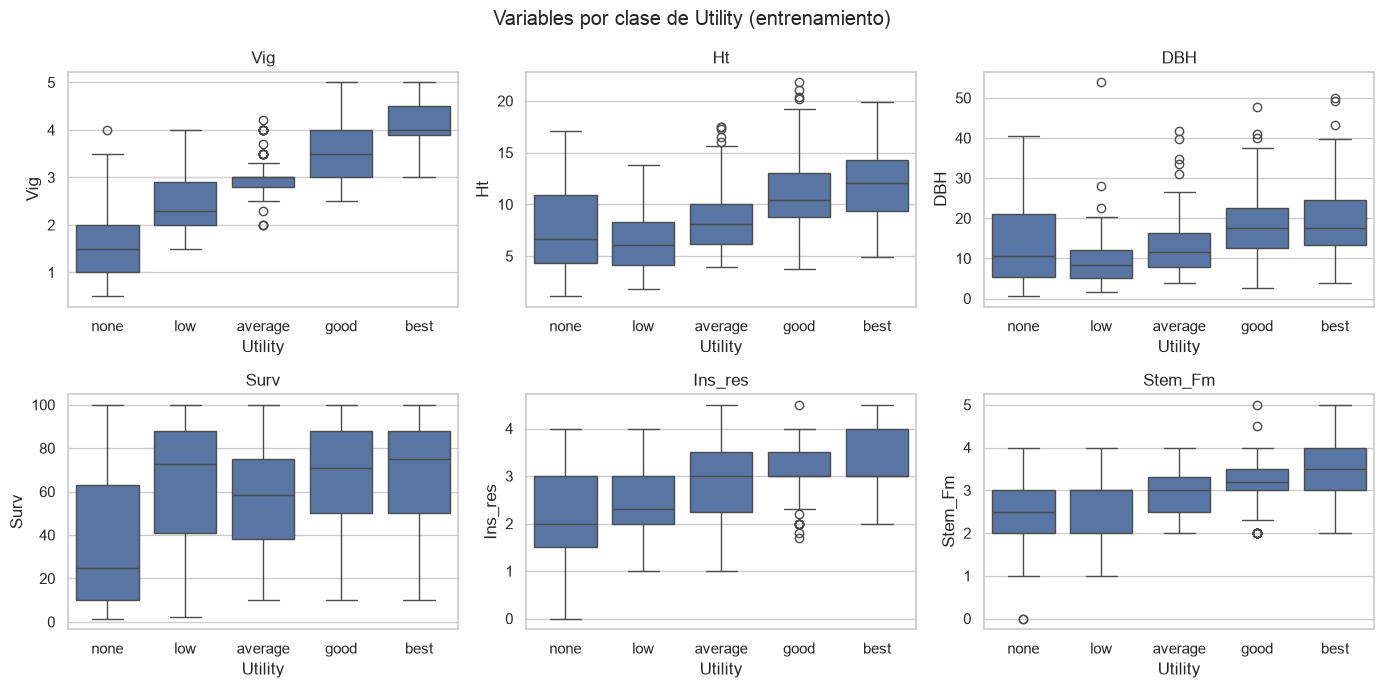

**n con dato por clase**

,Vig,Ht,DBH,Surv,Ins_res,Stem_Fm
Utility,,,,,,
none,80,126,126,80,80,80
low,75,75,75,70,75,75
average,91,91,91,90,91,91
good,150,150,150,139,150,150
best,73,73,73,68,73,73


In [25]:
# Medidas por clase (cada caja usa solo las filas con dato; se indica n por clase)
medidas_clase = ["Vig", "Ht", "DBH", "Surv", "Ins_res", "Stem_Fm"]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(ejes.flat, medidas_clase):
    datos = X_train.assign(Utility=y_train)
    if col == "DBH":
        datos = datos[datos["DBH"] < 1000]  # solo visualización, sin el valor 42085
    sns.boxplot(data=datos, x="Utility", y=col, order=CLASES, ax=ax)
    ax.set_title(col)
fig.suptitle("Variables por clase de Utility (entrenamiento)")
fig.tight_layout()
plt.show()

display(Markdown("**n con dato por clase**"))
X_train[medidas_clase].notna().groupby(y_train).sum().loc[CLASES]

## 8. Correlaciones

**Spearman con la clase ordenada (por pares con dato)**

,rho
Year,-0.21
PMCno,-0.04
Altitude,-0.03
Frosts,-0.01
Rep,0.06
Brnch_Fm,0.12
Rainfall,0.23
Surv,0.27
DBH,0.34
Crown_Fm,0.40


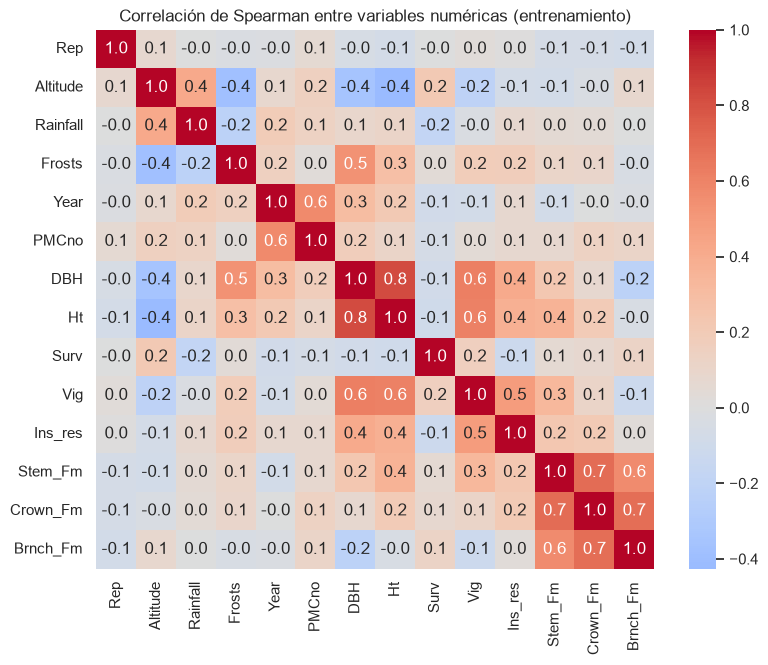

In [26]:
# Correlación de Spearman de cada variable numérica con la clase ordenada (none=0 ... best=4)
y_ordinal = y_train.astype(str).map({c: i for i, c in enumerate(CLASES)})
corr_objetivo = X_train[numericas].corrwith(y_ordinal, method="spearman").round(2).sort_values()
display(Markdown("**Spearman con la clase ordenada (por pares con dato)**"))
display(corr_objetivo.to_frame("rho"))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(X_train[numericas].corr(method="spearman"), annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación de Spearman entre variables numéricas (entrenamiento)")
plt.show()

## 9. Efecto de las parcelas sin medidas en el reparto de clases

In [27]:
sin_medidas = X_train["Vig"].isna()  # son las mismas 46 filas que no tienen ninguna de las seis medidas
conteo_todas = y_train.value_counts().reindex(CLASES)
conteo_con = y_train[~sin_medidas].value_counts().reindex(CLASES)
comparacion = pd.DataFrame({
    f"con todas (n = {len(y_train)})": conteo_todas,
    "%": (conteo_todas / len(y_train) * 100).round(1),
    f"sin las parcelas sin MEDIDAS (n = {(~sin_medidas).sum()})": conteo_con,
    "% ": (conteo_con / (~sin_medidas).sum() * 100).round(1),
})
display(Markdown("**Reparto de clases con y sin las parcelas sin MEDIDAS (entrenamiento)**"))
comparacion

**Reparto de clases con y sin las parcelas sin MEDIDAS (entrenamiento)**

,con todas (n = 515),%,sin las parcelas sin MEDIDAS (n = 469),%
Utility,,,,
none,126,24.5,80,17.1
low,75,14.6,75,16.0
average,91,17.7,91,19.4
good,150,29.1,150,32.0
best,73,14.2,73,15.6


## 10. Limpieza común y exportación de los datos

⚖️ **Decisiones del equipo** (ADR-0001 y `docs/acuerdos.md`), aplicadas aquí una sola vez para todos:
- Se quitan las parcelas sin medidas **solo de entrenamiento** (validación y test las conservan).
- `DBH = 42085` pasa a `NaN` en los tres conjuntos.
- Se deja `Abbrev` y se quitan las siete columnas que solo repiten el sitio.
- No se imputa, ni se escala, ni se codifica: eso lo hace cada integrante dentro de su `Pipeline`.

Se guardan `data/train.csv`, `data/val.csv` y `data/test.csv` (con la columna objetivo `Utility`) y una copia en `.joblib` de cada uno, que conserva los tipos de las columnas. El test no se toca más.

In [28]:
from comun import guardar_conjuntos, limpiar, sin_medidas

# Comprobación: las parcelas sin medidas de train son 46 y todas `none` (ADR-0001)
faltan = sin_medidas(X_train)
assert faltan.sum() == 46 and (y_train[faltan] == "none").all()

# La limpieza común vive en comun.py (limpiar); aquí solo se aplica y se guarda
guardar_conjuntos({
    "train": limpiar(X_train, y_train, quitar_sin_medidas=True),
    "val": limpiar(X_val, y_val, quitar_sin_medidas=False),
    "test": limpiar(X_test, y_test, quitar_sin_medidas=False),
})

train: 469 filas, 13 columnas
val: 110 filas, 13 columnas
test: 111 filas, 13 columnas


# 📝 Conclusión del EDA y traspaso al equipo

> Aquí termina el EDA común. El preprocesado lo hace cada integrante en su propio trabajo, antes de entrenar su modelo; después el equipo compara los modelos y elige uno.

---

### ✅ Qué hemos comprobado (conjunto de entrenamiento, n = 515)
- **Tarea:** clasificación de `Utility` en 5 clases ordenadas (`none` < `low` < `average` < `good` < `best`), con desbalance moderado (de 29,1 % a 14,2 %).
- **Calidad:** sin duplicados; un error evidente en `DBH` (42085); ausentes concentrados en dos bloques (`Mor`/`Wen` sin ninguna medida, `Cly` sin `Surv`) y 5 en `PMCno`.
- **Señal:** `Vig` es la variable más ligada a la clase (Spearman 0,79), seguida de `Ins_res`, `Stem_Fm` y `Ht` (≈ 0,45).

### ⚠️ Riesgos a tener presentes
- **Las 46 filas sin medidas son todas `none`** (46 de 46): la ausencia delata la clase. Un modelo que use los ausentes (o un imputador que los rellene) puede parecer mejor de lo que es y fallar con datos nuevos que sí traigan medidas.
- **El sitio condiciona la clase** y siete columnas describen lo mismo (el sitio). Repartir filas del mismo sitio entre entrenamiento y validación puede inflar las métricas.
- **`Vig` y otras medidas** deben estar disponibles al predecir; hay que confirmarlo.
- **Límites:** 736 filas en total, grupos pequeños (p. ej. `WSh` 2 filas, `Wen` 5), y los métodos de ensayo cambiaron con el tiempo.

### ✅ Decisiones del equipo (se aplican en el punto 10 de este notebook)
1. **Parcelas sin medidas** (46 en entrenamiento, todas `none`): se quitan **solo del entrenamiento**, después del split. Validación y test las conservan y se predicen `none` por regla fija, sin pasar por el modelo; las métricas se informan con y sin ellas (`docs/adr/0001-excluir-parcelas-sin-medidas.md`).
2. **`DBH = 42085`:** se pasa a `NaN`; cada pipeline lo imputa, ajustando solo con entrenamiento.
3. **Variables de sitio redundantes:** se deja `Abbrev` y se quitan las otras siete.
4. **Validación cruzada:** `StratifiedKFold` de 5 folds, con `StratifiedGroupKFold` por sitio como comprobación aparte (ADR-0002).

### 🚧 Dónde acaba el EDA y qué queda para el preprocesado de cada integrante
**El EDA acaba aquí:** detecta los problemas y, con las decisiones del equipo, hace solo la limpieza común (quitar las parcelas sin medidas de entrenamiento, `DBH` a `NaN`, quitar las siete columnas de sitio redundantes) y guarda `data/train.csv`, `data/val.csv` y `data/test.csv`. No imputa, no escala, no codifica ni crea variables.

**Cada integrante, dentro de su `Pipeline` + `ColumnTransformer` ajustados solo con entrenamiento (cada decisión escrita como `⚖️ Decisión / Por qué`):**
1. Imputar los ausentes de `Cly` (`Surv`, 22), de `PMCno` (5) y el `DBH` corregido.
2. Tratar las parejas muy correlacionadas (`DBH`–`Ht`; `Stem_Fm`/`Crown_Fm`/`Brnch_Fm`).
3. Codificar las categóricas (`Sp` con 27 valores y `Abbrev` con 16, con valores raros) y escalar solo si el modelo lo necesita.
4. Selección y creación de variables, desbalance (`class_weight` primero) y el resto de pasos de la guía (baseline, modelos, ajuste de hiperparámetros).
5. Aplicar la regla de las parcelas sin medidas a validación y test antes de calcular las métricas.

### 🤝 Para poder comparar los modelos con justicia
Mismo reparto train/validación/test (`SEMILLA = 42`), misma validación cruzada (`StratifiedKFold`, 5 folds), mismas métricas (F1 macro, accuracy y F1 por clase) y la misma regla para las parcelas sin medidas. El test no se toca hasta elegir el modelo final.


# 02 · Regresión logística: clase de utilidad de una parcela

**Responsable:** Fabiana Leonardo (@fabileoruf). **Historia:** [#38](https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase/issues/38); subtareas #52, #53 y #54.

Predecimos `Utility` en las cinco clases `none`, `low`, `average`, `good` y `best`.
El objetivo es superar el Dummy con un pipeline reproducible y un gap de F1 macro inferior a 5 puntos.
La regresión logística calcula probabilidades multiclase; no interpreta la distancia entre clases como una regresión numérica.

Se usan los CSV compartidos y la biblioteca obligatoria `comun.py`, según [los acuerdos](docs/acuerdos.md).
No se vuelve a hacer el split ni la limpieza del EDA. El conjunto reservado para la evaluación final se mantiene sin leer.

**Ejecución:** abrir este notebook desde la raíz del repositorio, seleccionar el entorno `.venv` con las dependencias de `requirements.txt` y ejecutar todas las celdas, en orden.


## 1. Entorno y funciones comunes

Las decisiones específicas del algoritmo están aquí; carga, baseline, CV, regla `none`, evaluación y exportación se importan de `comun.py`.


In [29]:
import json
import subprocess
import sys
from functools import partial
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from comun import (
    CLASES, GAP_MAXIMO, NUMERICAS, RAIZ, SEMILLA,
    baseline_dummy, cargar_datos, conclusion_modelo, cv_comun,
    elegir_sin_sobreajuste, errores_frecuentes, evaluar_val,
    f1_por_fold, guardar_modelo, mostrar_evaluacion,
    separar_xy, sin_medidas,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

NOMBRE_RL = "02_regresion_logistica"
print("Python:", sys.version.split()[0])
print({paquete: version(paquete) for paquete in ["numpy", "pandas", "scikit-learn", "joblib"]})


Python: 3.14.7
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


## 2. Datos compartidos

La limpieza de `01_eda` ya excluye las parcelas sin medidas de train. Validación las conserva.
`Abbrev` se conserva también para la comprobación de generalización a sitios nuevos.
Las distribuciones que se muestran aquí corresponden únicamente a entrenamiento.


In [30]:
train_rl, val_rl = cargar_datos()
X_train_rl, y_train_rl = separar_xy(train_rl)
X_val_rl, y_val_rl = separar_xy(val_rl)

assert set(y_train_rl.unique()) == set(CLASES)
assert not sin_medidas(X_train_rl).any(), "Revisar los CSV comunes: train contiene parcelas sin medidas."
print(f"Train: {len(train_rl)} parcelas. Validación: {len(val_rl)} parcelas.")
print(f"Validación sin medidas: {sin_medidas(X_val_rl).sum()} (se aplica la regla none).")
display(y_train_rl.value_counts().reindex(CLASES).rename_axis("clase de utilidad").to_frame("parcelas de entrenamiento"))


Train: 469 parcelas. Validación: 110 parcelas.
Validación sin medidas: 15 (se aplica la regla none).


,parcelas de entrenamiento
clase de utilidad,
none,80
low,75
average,91
good,150
best,73


## 3. Preprocesado y decisiones

| Decisión | Por qué |
|---|---|
| Usar las 8 medidas numéricas de `NUMERICAS` | Son mediciones de campo; deben estar disponibles cuando se prediga. |
| Imputar con la mediana y aplicar `StandardScaler` | Resolver los ausentes de supervivencia y diámetro; evitar que las unidades dominen la regularización. |
| Codificar `Abbrev` y `Sp` con one-hot | Son categorías sin orden numérico. Las categorías desconocidas se toleran; los valores raros se agrupan si aparecen menos de 3 veces en el fold. |
| Excluir `Rep` y `PMCno` mediante `remainder="drop"` | Son identificadores del diseño del ensayo y de procedencia; no se supone una relación ordinal entre sus números y la utilidad. |
| Conservar `DBH`/`Ht` y las tres medidas de forma, con regularización L2 | El EDA detectó correlaciones. L2 limita los coeficientes sin eliminar arbitrariamente una medida; dificulta atribuir importancia individual a variables correlacionadas. |
| Comparar `class_weight=None` y `"balanced"` | Atender al desbalance moderado sin crear parcelas sintéticas. La elección se hace solo con CV sobre train. |

Todo el preprocesado está dentro del `Pipeline`: cada fold ajusta sus propias medianas, escalas y categorías.
Las columnas descartadas siguen en el DataFrame de entrada para que la biblioteca común pueda comprobar los sitios y las medidas.

Referencias de la API: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) y [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).


In [31]:
numericas_rl = list(NUMERICAS)
categoricas_rl = ["Abbrev", "Sp"]

preprocesado_rl = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), numericas_rl),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", min_frequency=3)),
        ]), categoricas_rl),
    ],
    remainder="drop",
)

pipeline_rl = Pipeline([
    ("preprocesado", preprocesado_rl),
    ("logistica", LogisticRegression(
        solver="lbfgs", l1_ratio=0.0, max_iter=5000, random_state=SEMILLA,
    )),
])


## 4. Baseline común

El Dummy predice la clase más frecuente de entrenamiento. La regla `none` se aplica también al baseline, para comparar en las mismas condiciones.


In [32]:
dummy_rl = baseline_dummy(X_train_rl, y_train_rl, X_val_rl, y_val_rl)


El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


## 5. Selección de hiperparámetros, solo con entrenamiento

La rejilla se fija antes de evaluar el modelo en validación. Un `C` pequeño implica mayor regularización.
Se usa `elegir_sin_sobreajuste`: mayor F1 macro en CV entre candidatos con gap train–CV inferior a 5 puntos; en empate se favorece menor `C`.
Si ninguno cumple, la biblioteca elige el menor gap y lo avisa. No se reajusta la rejilla mirando validación.


In [33]:
rejilla_rl = {
    "logistica__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0],
    "logistica__class_weight": [None, "balanced"],
}
busqueda_rl = GridSearchCV(
    pipeline_rl,
    param_grid=rejilla_rl,
    scoring="f1_macro",
    cv=cv_comun(),
    return_train_score=True,
    refit=partial(elegir_sin_sobreajuste, desempate=[("param_logistica__C", True)]),
    n_jobs=-1,
    error_score="raise",
)
busqueda_rl.fit(X_train_rl, y_train_rl)
modelo_rl = busqueda_rl.best_estimator_

tabla_busqueda_rl = pd.DataFrame(busqueda_rl.cv_results_)
tabla_busqueda_rl["gap_cv_puntos"] = 100 * (tabla_busqueda_rl["mean_train_score"] - tabla_busqueda_rl["mean_test_score"])
tabla_busqueda_rl["elegido"] = tabla_busqueda_rl.index == busqueda_rl.best_index_
display(tabla_busqueda_rl[[
    "param_logistica__C", "param_logistica__class_weight",
    "mean_train_score", "mean_test_score", "std_test_score", "gap_cv_puntos", "elegido",
]].sort_values("mean_test_score", ascending=False).round(4))
print("Hiperparámetros elegidos solo con train:", busqueda_rl.best_params_)
print("Iteraciones hasta converger:", modelo_rl.named_steps["logistica"].n_iter_)


,param_logistica__C,param_logistica__class_weight,mean_train_score,mean_test_score,std_test_score,gap_cv_puntos,elegido
17,10.000,balanced,0.7948,0.5835,0.0515,21.1302,False
16,10.000,NaN,0.8061,0.5835,0.0766,22.2551,False
14,3.000,NaN,0.7771,0.5799,0.0792,19.7183,False
18,30.000,NaN,0.8131,0.5770,0.0731,23.6036,False
12,1.000,NaN,0.7454,0.5766,0.0605,16.8741,False
13,1.000,balanced,0.7421,0.5735,0.0402,16.8595,False
11,0.300,balanced,0.7089,0.5692,0.0449,13.9666,False
19,30.000,balanced,0.8085,0.5683,0.0605,24.0191,False
10,0.300,NaN,0.7016,0.5674,0.0823,13.4181,False
15,3.000,balanced,0.7687,0.5632,0.0590,20.5492,False


Hiperparámetros elegidos solo con train: {'logistica__C': 0.003, 'logistica__class_weight': 'balanced'}
Iteraciones hasta converger: [10]


## 6. Validación cruzada común y por sitio — #52

Se presentan los cinco folds, la media y la desviación con ambos esquemas comunes.
La comprobación por sitio utiliza `Abbrev` como grupo y no se utiliza para retocar el modelo.
La CV común comparte los folds usados para elegir hiperparámetros: su resultado es descriptivo tras selección, no una estimación independiente de ella.


In [34]:
cv_rl = f1_por_fold(modelo_rl, X_train_rl, y_train_rl)
print(f"Diferencia CV común − CV por sitio: {100 * (cv_rl['f1'] - cv_rl['f1_sitio']):.2f} puntos.")


,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.408,0.376
2,0.439,0.407
3,0.470,0.369
4,0.419,0.381
5,0.436,0.450


StratifiedKFold: F1 macro = 0.434 ± 0.021 | gap 3.4 puntos ✅ correcto
Por sitio:       F1 macro = 0.397 ± 0.030 | gap 7.6 puntos
Diferencia CV común − CV por sitio: 3.75 puntos.


## 7. Evaluación en validación y overfitting — #53

`evaluar_val` usa `predecir_con_regla`: las parcelas sin medidas reciben `none` **sin entrar al modelo**.
Se muestran accuracy, precision/recall/F1 por clase y matrices de confusión, tanto sobre toda la validación como solo sobre parcelas con medidas.

El gap acordado es `(F1 train − F1 validación con medidas) × 100`, **con signo**.
El resultado sobre toda la validación incluye el acierto de la regla y se usa para comparar los modelos del equipo.


### Lectura de la ejecución entregada

El gap observado es **6,52 puntos**: F1 de train **0,4943** frente a **0,4291** en las 95 parcelas de validación con medidas. **No cumple el límite de 5 puntos**. El F1 de toda la validación es **0,4677**, con accuracy **0,5091**; las 15 parcelas sin medidas se resuelven por la regla.

La selección por CV había dado un gap de 3,41 puntos, pero esa condición no garantiza el mismo resultado en un conjunto diferente. La CV compara modelos ajustados en cuatro folds y el pipeline exportado se ajusta en las 469 parcelas de train; además, validación con medidas solo tiene 95 parcelas. Esas diferencias pueden contribuir al gap, pero esta ejecución no permite aislar una causa única.

El `C=0,003` elegido impone regularización fuerte y el rendimiento absoluto es limitado, especialmente en las clases intermedias. Un gap pequeño en CV no basta para afirmar que un modelo es bueno. Se conserva la elección hecha con train y se documenta el incumplimiento, tal como admite el criterio de #38, sin usar validación para seleccionar otra configuración.


1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.468,⚠️ flojo,22.406,⚠️ supera poco,0.509,0.517,0.511,0.517,0.474
solo con medidas,0.429,⚠️ flojo,32.831,✅ supera claramente,0.432,0.498,0.466,0.498,0.401


2. OVERFITTING: F1 train 0.494 - F1 validación con medidas 0.429 = 6.5 puntos → ❌ ligero sobreajuste
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas                     
                 precision recall    f1 soporte        precision recall    f1 soporte
none                  0.68   0.93  0.78    27.0             0.45   0.83  0.59    12.0
low                   0.53   0.56  0.55    16.0             0.53   0.56  0.55    16.0
average               0.50   0.16  0.24    19.0             0.50   0.16  0.24    19.0
good                  0.53   0.25  0.34    32.0             0.53   0.25  0.34    32.0
best                  0.31   0.69  0.43    16.0             0.31   0.69  0.43    16.0

4. MATRICES DE CONFUSIÓN


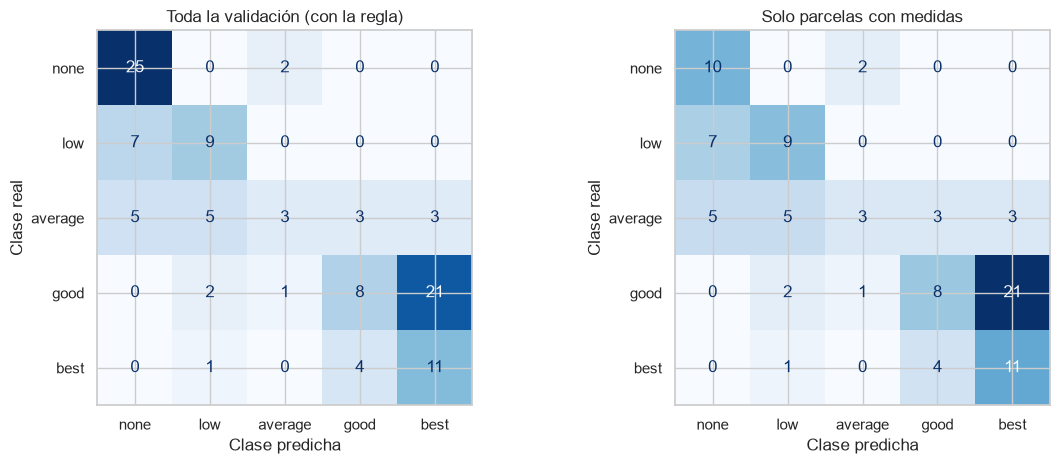

No cumple el límite de sobreajuste: se documenta el resultado y no se ajustan hiperparámetros usando esta validación. No es candidato al modelo ganador con la regla actual.


In [35]:
evaluacion_rl = evaluar_val(modelo_rl, X_train_rl, y_train_rl, X_val_rl, y_val_rl, dummy_rl)
mostrar_evaluacion(evaluacion_rl)

if evaluacion_rl["gap"] < -GAP_MAXIMO:
    print("La validación supera al entrenamiento por más de 5 puntos. Cumple la regla de sobreajuste, pero este split pequeño puede ser más favorable; no demuestra generalización perfecta.")
elif not evaluacion_rl["cumple_gap"]:
    print("No cumple el límite de sobreajuste: se documenta el resultado y no se ajustan hiperparámetros usando esta validación. No es candidato al modelo ganador con la regla actual.")
else:
    print("Cumple el límite de sobreajuste acordado. La comprobación por sitio y los errores siguen siendo necesarios para valorar sus límites.")


## 8. Interpretación por coeficientes — #54

La importancia nativa se resume como la media del valor absoluto de los coeficientes de las cinco clases, por variable transformada.
Las numéricas están estandarizadas; las indicadoras one-hot están en escala 0/1. Es una lectura del modelo, no una medida causal ni una comparación exacta entre tipos de variable.
Las variables correlacionadas pueden repartirse los coeficientes. La tabla por clase conserva el signo y permite ver qué asociaciones favorecen cada clase.


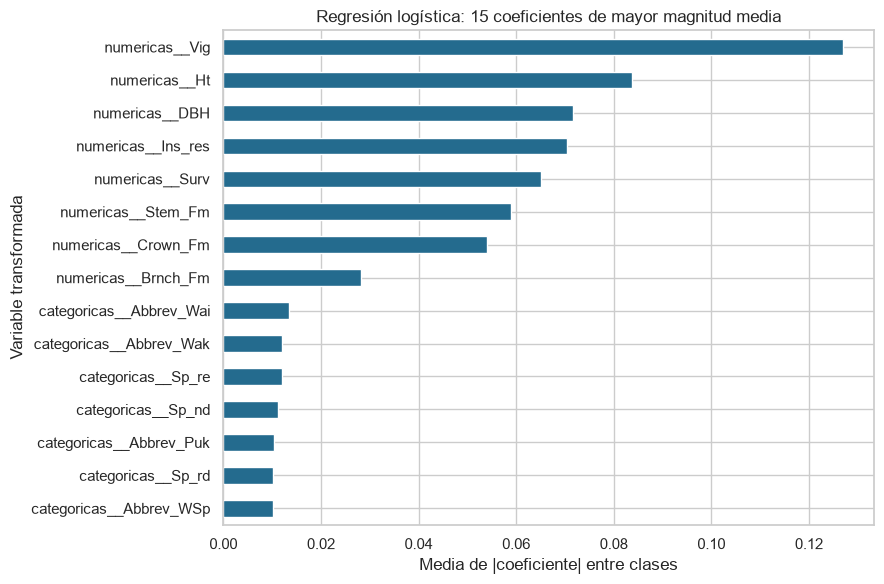

,none,low,average,good,best
numericas__Vig,-0.220,-0.097,0.017,0.109,0.191
numericas__Ht,-0.097,-0.099,-0.014,0.084,0.125
numericas__DBH,-0.104,-0.067,-0.008,0.080,0.099
numericas__Ins_res,-0.104,-0.072,0.015,0.060,0.100
numericas__Surv,-0.147,0.037,-0.016,0.054,0.072
numericas__Stem_Fm,-0.087,-0.055,-0.005,0.037,0.111
numericas__Crown_Fm,-0.099,-0.036,0.006,0.030,0.099
numericas__Brnch_Fm,-0.050,0.014,-0.001,-0.019,0.056
categoricas__Abbrev_Wai,0.006,0.007,-0.019,-0.015,0.021
categoricas__Abbrev_Wak,0.030,-0.007,-0.012,-0.011,-0.000


In [36]:
nombres_variables_rl = modelo_rl.named_steps["preprocesado"].get_feature_names_out()
coeficientes_rl = pd.DataFrame(
    modelo_rl.named_steps["logistica"].coef_.T,
    index=nombres_variables_rl,
    columns=modelo_rl.named_steps["logistica"].classes_,
).reindex(columns=CLASES)
importancia_rl = coeficientes_rl.abs().mean(axis=1).sort_values(ascending=False)
principales_rl = importancia_rl.head(15)

fig_rl, ax_rl = plt.subplots(figsize=(9, 6))
principales_rl.sort_values().plot.barh(ax=ax_rl, color="#246b8e")
ax_rl.set(title="Regresión logística: 15 coeficientes de mayor magnitud media", xlabel="Media de |coeficiente| entre clases", ylabel="Variable transformada")
fig_rl.tight_layout()
plt.show()
display(coeficientes_rl.loc[principales_rl.index].round(3))


## 9. Análisis de errores — #54

Se ordenan las confusiones reales y se inspeccionan parcelas mal clasificadas junto con su vigor y otras medidas.
La escala de utilidad es ordenada, aunque la regresión logística multinomial no impone ese orden.
Una confusión entre clases vecinas puede ser compatible con medidas de campo parecidas; una de dos o más niveles requiere especial atención.
Estas explicaciones son hipótesis, no causas demostradas por el modelo.


**Lectura de los errores observados:** 54 de 110 parcelas se clasifican mal: 41 errores son entre clases vecinas y 13 saltan dos o más niveles. La confusión principal es `good → best` (21 parcelas); el recall de `good` es 0,25 y el de `average` solo 0,158. El modelo separa mejor los extremos que las clases intermedias.

Los coeficientes muestran que un vigor alto favorece tanto `good` como `best`, con mayor coeficiente para `best`. Esto es compatible con la confusión principal, aunque también intervienen las demás medidas y los interceptos. El peso equilibrado de clases y la regularización fuerte son posibles factores; no se ha hecho una comparación causal que lo demuestre. También aparecen `low → none` (7 parcelas) y `average → none` (5), que requieren revisar las medidas y el contexto del sitio.

El F1 cae de 0,434 en CV común a 0,397 por sitio. La diferencia de 3,75 puntos confirma que ambas evaluaciones cuentan historias distintas; no se puede trasladar el resultado del split común sin más a sitios nuevos. `Vig` es el coeficiente de mayor magnitud media, seguido por altura y diámetro; la interpretación no demuestra causalidad.


In [37]:
errores_rl = errores_frecuentes(evaluacion_rl["y"], evaluacion_rl["pred"])
display(errores_rl)

parcelas_error_rl = X_val_rl.assign(real=y_val_rl, predicha=evaluacion_rl["pred"])
parcelas_error_rl = parcelas_error_rl.loc[parcelas_error_rl["real"] != parcelas_error_rl["predicha"]]
display(parcelas_error_rl[["Abbrev", "Sp", "Vig", "Surv", "Ins_res", "real", "predicha"]].head(12))

for error_rl in errores_rl.head(3).itertuples(index=False):
    print(f"{error_rl.real} → {error_rl.predicha}: {error_rl.parcelas} parcelas; distancia de {error_rl.distancia} niveles.")
if cv_rl["f1_sitio"] < cv_rl["f1"]:
    print("La caída al separar sitios es compatible con dependencia del contexto del sitio. El rendimiento en sitios nuevos debe comunicarse con esta limitación (ADR-0002).")
print("Vig y el resto de medidas deben estar disponibles en la parcela al predecir. Si faltan todas, responde la regla; no se interpreta como éxito de la regresión logística.")


Errores: 54 de 110. Entre clases vecinas: 41; a 2 o más clases de distancia: 13.


,real,predicha,parcelas,distancia
0,good,best,21,1
1,low,none,7,1
2,average,none,5,2
3,average,low,5,1
4,best,good,4,1
5,average,best,3,2
6,average,good,3,1
7,good,low,2,2
8,none,average,2,2
9,best,low,1,3


,Abbrev,Sp,Vig,Surv,Ins_res,real,predicha
3,K81,si,3.0,25.0,3.0,average,none
4,K81,re,4.0,63.0,3.5,good,best
5,K81,br,3.0,88.0,2.0,best,low
7,Cra,ov,3.0,100.0,1.8,average,low
9,Puk,nd,2.5,75.0,2.0,average,low
13,Puk,ov,3.0,75.0,2.0,average,low
16,Paw,co,3.6,30.0,3.8,good,best
21,K81a,re,2.5,7.0,3.0,low,none
22,Lon,co,3.5,100.0,3.0,good,best
23,Paw,nd,3.0,20.0,4.0,average,best


good → best: 21 parcelas; distancia de 1 niveles.
low → none: 7 parcelas; distancia de 1 niveles.
average → none: 5 parcelas; distancia de 2 niveles.
La caída al separar sitios es compatible con dependencia del contexto del sitio. El rendimiento en sitios nuevos debe comunicarse con esta limitación (ADR-0002).
Vig y el resto de medidas deben estar disponibles en la parcela al predecir. Si faltan todas, responde la regla; no se interpreta como éxito de la regresión logística.


## 10. Exportación y recarga en una sesión nueva — #54

Se guarda el pipeline completo con la función común. Además de su comprobación de recarga, se abre un proceso Python independiente y se verifica que produce exactamente las mismas predicciones en validación.
La regla de parcelas sin medidas vive en `comun.py`: la app debe llamar a `predecir_con_regla`, no al pipeline directamente sobre esas parcelas.


In [38]:
ruta_modelo_rl = guardar_modelo(modelo_rl, NOMBRE_RL, X_val_rl)

codigo_recarga_rl = """
import json
import joblib
import pandas as pd
from comun import DATOS, MODELOS, predecir_con_regla, separar_xy

modelo = joblib.load(MODELOS / "02_regresion_logistica.joblib")
validacion = pd.read_csv(DATOS / "val.csv", encoding="utf-8")
X, _ = separar_xy(validacion)
predicciones = predecir_con_regla(modelo, X)
print(json.dumps(predicciones.tolist()))
"""
sesion_nueva_rl = subprocess.run(
    [sys.executable, "-c", codigo_recarga_rl],
    cwd=RAIZ, check=True, capture_output=True, text=True, encoding="utf-8",
)
predicciones_recargadas_rl = json.loads(sesion_nueva_rl.stdout)
assert predicciones_recargadas_rl == evaluacion_rl["pred"].tolist()
print(f"Sesión Python nueva: {len(predicciones_recargadas_rl)} predicciones idénticas.")


Guardado: models/02_regresion_logistica.joblib (7.3 KB). ¿Al recargarlo predice igual? ✅


Sesión Python nueva: 110 predicciones idénticas.


## 11. Conclusión y entrega común

La tabla de requisitos y el JSON se generan con `conclusion_modelo`. Se entregan este notebook ejecutado, el pipeline y `resultados/02_regresion_logistica.json` para la comparación de `06_conclusiones`.

**Requisitos cualitativos:** preprocesado dentro del pipeline (§3); importancia nativa con gráfico y coeficientes por clase (§8); confusiones y parcelas mal clasificadas (§9); recarga en proceso independiente (§10).
El equipo elegirá el modelo ganador entre sus cuatro algoritmos. Este notebook no realiza la evaluación final del equipo.


**Resultado:** el modelo supera al Dummy (F1 global 0,468 frente a 0,244) y se entrega para comparación, pero **no es candidato al modelo ganador**, porque su gap de 6,52 puntos incumple el umbral. El JSON deja `cumple_gap=false`; no se presenta el requisito R2 como conseguido.

El pipeline convergió sin avisos y su recarga en otro proceso reprodujo las 110 predicciones. Una siguiente iteración metodológica debería estudiar la selección en CV y la separación de clases intermedias, manteniendo el conjunto final reservado y dejando constancia de que esta validación ya se ha observado.


In [39]:
ruta_resultados_rl = conclusion_modelo(
    NOMBRE_RL, cv_rl, evaluacion_rl, dummy_rl, busqueda_rl.best_params_,
)
print(f"F1 macro en toda la validación: {evaluacion_rl['filas']['toda la validación']['F1 macro']:.3f}")
print(f"F1 macro solo con medidas: {evaluacion_rl['filas']['solo con medidas']['F1 macro']:.3f}")
print(f"Gap de sobreajuste: {evaluacion_rl['gap']:.2f} puntos; cumple: {evaluacion_rl['cumple_gap']}.")


,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,6.5 puntos,❌
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+33 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.434 / 0.397,✅
R6,Pipeline guardado,Acuerdos,models/02_regresion_logistica.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.434,0.468,0.429
gap (puntos),3.409,NaN,6.523
supera Dummy (puntos),33.734,22.406,32.831


Resultados guardados en resultados/02_regresion_logistica.json
F1 macro en toda la validación: 0.468
F1 macro solo con medidas: 0.429
Gap de sobreajuste: 6.52 puntos; cumple: False.


# Modelo 2: árbol de decisión

**Proyecto:** clasificación multiclase de la *utilidad para la conservación del suelo* de parcelas de eucalipto (dataset Eucalyptus).
**Historia:** #39 · **Notebook:** `03_arbol_decision.ipynb`

Este notebook sigue, paso a paso, la *Guía de un proyecto de clasificación en ML* (`docs/machine_learning/guia_proyecto_ml.md`). Cada paso tiene:

- **Qué hacemos**: la acción concreta.
- **Por qué**: la razón, para que se entienda y no sea una receta.
- **Cómo leer el resultado**: qué mirar en la salida de la celda.
- **Preguntas de la guía**: las preguntas que la guía plantea en ese paso, respondidas con nuestros datos.

Las reglas comunes del equipo (mismo split, misma validación, mismas métricas) están en `docs/acuerdos.md`. Gracias a ellas, este modelo se puede comparar de forma justa con los otros tres (regresión logística, SVM y KNN).

## Pasos 0, 1 y 2: problema, split y EDA (ya hechos)

Estos tres pasos son comunes a todo el equipo y no se repiten aquí:

| Paso | Dónde está | Resumen |
|---|---|---|
| 0. Definir el problema | `00_general.ipynb` | Predecir la **clase de utilidad** (`Utility`) de una parcela: `none` < `low` < `average` < `good` < `best`. Métrica principal: **F1 macro** (trata las 5 clases por igual). Restricción: **sobreajuste < 5 puntos**. |
| 1. Datos y split | `01_eda.ipynb`, sección 10 | Split estratificado 70/15/15 con semilla 42, guardado en `data/train.csv`, `data/val.csv` y `data/test.csv`. |
| 2. EDA | `01_eda.ipynb` e informe `docs/informe-eda.md` | Hallazgos clave: las parcelas **sin medidas** son siempre `none`; el **sitio** marca mucho la clase; el **vigor** es la medida más relacionada con la clase. |

**Regla importante (ADR-0001):** las parcelas sin medidas se quitaron **solo de train**. En validación y test siguen ahí y **no pasan por el modelo**: se predicen `none` con una regla fija.

> **¿Y el test?** `data/test.csv` **no se abre en este notebook**. Solo se usa una vez, al final del proyecto (`06_conclusiones`), con el modelo ganador. Si lo miráramos ahora, estaríamos haciendo trampa sin querer (paso 1 de la guía: *"Guarda el test y no lo toques hasta el final"*).

### Paso 1 (bis): cargar los datos

**Qué hacemos:** importamos la librería común del equipo (`comun.py`) y leemos `train.csv` y `val.csv` con ella.

**Por qué:** cada integrante parte de los mismos ficheros. Así todos los modelos ven exactamente los mismos datos y se pueden comparar. `comun.py` también guarda las reglas comunes (semilla, orden de las clases, regla `none`, cómo se mide el gap…), para que nadie las copie a mano (`docs/acuerdos.md`).

**Cómo leer el resultado:** comprobamos el número de filas de cada conjunto y cuántas parcelas de cada clase hay.

In [40]:
import pandas as pd

# Librería común del equipo: mismos datos, reglas y evaluación para los 4 modelos
from comun import CLASES, OBJETIVO, SEMILLA, cargar_datos, separar_xy  # noqa: F401

train, val = cargar_datos()  # data/train.csv y data/val.csv (el test no se lee aquí)

print(f"train: {train.shape[0]} filas x {train.shape[1]} columnas")
print(f"val:   {val.shape[0]} filas x {val.shape[1]} columnas")

pd.DataFrame({
    "train": train[OBJETIVO].value_counts(),
    "val": val[OBJETIVO].value_counts(),
}).reindex(CLASES)

train: 469 filas x 13 columnas
val:   110 filas x 13 columnas


,train,val
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


**Qué vemos:** las 5 clases están en los dos conjuntos. Ninguna clase es aplastante, pero `good` tiene el doble de parcelas que `best` o `low`: hay un **desbalance moderado**, que tendremos en cuenta en el paso 6.

### ¿Qué es una "parcela sin medidas"?

**Qué hacemos:** marcamos las parcelas a las que les faltan **todas** las medidas del árbol (supervivencia, vigor, resistencia a insectos y las tres formas).

**Por qué:** según el ADR-0001, esas parcelas no pasan por el modelo y se predicen `none` por regla. Necesitamos identificarlas para aplicar la regla en validación.

**Cómo leer el resultado:** en train debe salir **0** (ya se quitaron) y en validación algunas, todas de clase `none`.

In [41]:
# sin_medidas(X) es True si a la parcela le faltan TODAS las MEDIDAS (ADR-0001)
from comun import MEDIDAS, sin_medidas  # noqa: F401

print("Parcelas sin medidas en train:", sin_medidas(train).sum())
print("Parcelas sin medidas en val:  ", sin_medidas(val).sum())
clases_sin_medidas = val.loc[sin_medidas(val), OBJETIVO].value_counts()
print("Clase de las de val:", clases_sin_medidas.to_dict())

Parcelas sin medidas en train: 0
Parcelas sin medidas en val:   15
Clase de las de val: {'none': 15}


**Qué vemos:** 15 de las 27 parcelas `none` de validación no tienen medidas. La regla las acertará todas "gratis", y lo mismo pasará con cualquier modelo. Por eso, en el paso 8 daremos las métricas dos veces: con toda la validación y **solo con las parcelas con medidas**, que es donde de verdad trabaja el árbol.

## Paso 3: preprocesado

**Qué hacemos:** preparamos las columnas para que el árbol pueda usarlas:

| Tipo de columna | Columnas | Tratamiento |
|---|---|---|
| Numéricas | `DBH`, `Ht`, `Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm` | Rellenar los huecos con la **mediana** (`SimpleImputer`) |
| Categóricas | `Abbrev` (sitio), `Sp` (especie) | Convertir cada categoría en un número (`OrdinalEncoder`) |

**Por qué:**
- scikit-learn necesita números y sin huecos. Faltan valores en `Surv` (parcelas del sitio Cly) y en un `DBH` (el diámetro erróneo de 42 085 cm que se convirtió en hueco).
- Usamos la **mediana** y no la media porque no la arrastran los valores extremos.
- **OrdinalEncoder** da un número a cada categoría, por orden alfabético (el primer sitio = 0, el segundo = 1…). A un árbol no le importa que esos números no tengan un orden real, porque solo hace preguntas del tipo "¿sitio ≤ 3?". Además, la importancia de cada variable se sigue leyendo por la variable original. Con One-hot tendríamos 39 columnas y la importancia quedaría repartida entre ellas.
- `handle_unknown` sirve por si en validación aparece una especie que no estaba en train: en vez de fallar, le da el valor −1.

**Sin escalar:** el árbol compara cada variable consigo misma ("¿vigor ≤ 3,2?"), así que le da igual que una variable vaya de 0 a 5 y otra de 0 a 2000. La regresión logística, el SVM y el KNN sí necesitan escalar.

**Todo dentro de un `Pipeline`:** la mediana y los códigos se calculan **solo con train** y luego se aplican a validación. Si se calculasen con todos los datos, el modelo "vería" validación antes de tiempo (fuga de datos, el error nº 1 de la guía).

### Preguntas de la guía (paso 3)
- **¿Mi modelo necesita este paso o lo maneja solo?** Necesita la imputación y la codificación; no necesita escalado.
- **¿Estoy ajustando algo con datos que no debería ver?** No: el `Pipeline` ajusta solo con train, también dentro de cada fold de la validación cruzada.
- **¿Imputar con la media distorsiona esta variable?** Por eso usamos la mediana. Además faltan pocos valores (22 de `Surv` y 1 de `DBH` en 469 filas).

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

from comun import NUMERICAS  # DBH, Ht y las 6 MEDIDAS

CATEGORICAS = ["Abbrev", "Sp"]

print("Valores que faltan en train:")
print(train[NUMERICAS + CATEGORICAS].isna().sum()[lambda s: s > 0])

preprocesado = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), NUMERICAS),
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            CATEGORICAS,
        ),
    ],
    remainder="drop",  # las columnas no listadas (PMCno, Rep) se descartan
    verbose_feature_names_out=False,
)
preprocesado

Valores que faltan en train:
DBH      1
Surv    22
dtype: int64


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

## Paso 4: feature engineering y selección

**Qué hacemos:** dejamos fuera del modelo `PMCno` y `Rep` (con el `remainder="drop"` de la celda anterior).

**Por qué:**
- `PMCno` es el **número del lote de semillas** y `Rep` el **número de réplica** del ensayo. Son **identificadores**, como un DNI, no propiedades de la parcela.
- Un árbol puede aprender reglas como "si el lote es el 2426, entonces `best`". En train acertaría, pero con un lote nuevo esa regla no sirve de nada: es memorizar, no aprender.
- La guía lo pregunta en el paso 2: *"¿Hay columnas inútiles (ID, constantes)?"*.

Las columnas que solo repetían el sitio (`Locality`, `Latitude`, `Rainfall`, etc.) ya se quitaron en `01_eda`.

**Cómo leer el resultado:** la tabla muestra las 10 variables que entran en el modelo y un ejemplo de cómo quedan tras el preprocesado.

### Preguntas de la guía (paso 4)
- **¿Qué sabe un experto que el modelo no puede adivinar?** El EDA no encontró una combinación clara. Altura y diámetro están muy correlacionadas, pero a un árbol no le molesta: elige una de las dos en cada pregunta. No creamos variables nuevas.
- **¿Sobran variables?** Sí, los dos identificadores, que quitamos. Al final (paso 9) veremos cuáles usa de verdad el árbol.
- **¿Cada variable estará disponible al predecir?** Sí, si la parcela se ha medido. Si no, se aplica la regla `none`.

In [43]:
X_train, y_train = separar_xy(train)  # X = todas las columnas menos Utility

ejemplo = pd.DataFrame(
    preprocesado.fit_transform(X_train),
    columns=preprocesado.get_feature_names_out(),
)
print("Variables que entran en el modelo:", list(ejemplo.columns))
print("Huecos tras imputar:", int(ejemplo.isna().sum().sum()))
ejemplo.head()

Variables que entran en el modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev', 'Sp']
Huecos tras imputar: 0


,DBH,Ht,Surv,Vig,Ins_res,Stem_Fm,Crown_Fm,Brnch_Fm,Abbrev,Sp
0,16.69,9.48,50.0,4.0,3.0,4.0,4.0,3.0,9.0,7.0
1,21.72,14.75,38.0,3.0,3.0,3.0,4.0,2.3,11.0,14.0
2,2.56,2.91,75.0,1.0,1.0,2.0,2.0,3.0,9.0,17.0
3,7.03,5.99,88.0,3.5,2.7,3.5,4.0,4.0,2.0,14.0
4,22.20,14.60,63.0,5.0,3.0,4.0,4.0,3.2,12.0,16.0


### Vocabulario: ¿de qué datos hablamos?

A partir de aquí aparecen varias palabras para referirse a los datos. Todas salen de tres ficheros:

| Palabra | Qué datos son | Cuándo se usan |
|---|---|---|
| **train** | `data/train.csv` (469 parcelas). Son las parcelas con las que el modelo **aprende**. | Pasos 5 a 7 |
| **F1 train** (en las tablas) | En la validación cruzada, el árbol se entrena con 4/5 de `train.csv` (~375 parcelas) y se mide **sobre esas mismas parcelas**. Es la media de los 5 repartos. Mide cuánto acierta en lo que **ya ha visto**. | Pasos 5 a 7 |
| **F1 CV** (validación cruzada) | En cada reparto, la nota sobre el 1/5 de `train.csv` que se le **escondió** (~94 parcelas). Es la media de los 5 repartos. Mide cuánto acierta en lo que **no ha visto**. | Pasos 5 a 7 |
| **validación** | `data/val.csv` (110 parcelas). El modelo no las ha visto nunca: sirven para comprobar el modelo ya elegido. | Paso 8 |
| **test** | `data/test.csv`. **No se usa en este notebook**: es para `06_conclusiones`. | — |

**Gap** = F1 train − F1 CV. Si es grande, el modelo acierta lo que ha visto pero no lo nuevo: ha **memorizado** en vez de aprender.

### Cómo leer las columnas de requisitos

Cada modelo que probamos sale en **dos tablas**:

**Tabla de requisitos**: ¿cumple lo que pide el proyecto? Cada requisito va con un nivel:

| Columna | Qué mide | Niveles | Fuente |
|---|---|---|---|
| **nivel F1** | Calidad del F1 macro en CV | ❌ malo (< 0.30) · ⚠️ flojo (0.30–0.50) · ✅ aceptable (0.50–0.70) · 🌟 bueno (≥ 0.70) | Escala del equipo; con 5 clases, adivinar al azar da ~0.20 |
| **nivel gap** | Sobreajuste: F1 train − F1 CV, con signo (positivo = train por encima) | ✅ correcto (< 5 puntos) · ❌ ligero sobreajuste (5–10) · ❌ sobreajuste grave (≥ 10). Por debajo de −5 también cumple, pero con aviso ⚠️ | Enunciado: *overfitting < 5 %*; `docs/acuerdos.md` |
| **supera baseline** | Puntos de F1 por encima del Dummy | ❌ no supera (< 10) · ⚠️ supera poco (10–25) · ✅ supera claramente (≥ 25) | Guía, paso 5 |
| **clases que predice (de 5)** | Cuántas clases distintas aparecen en las respuestas del modelo (se evalúa siempre con las 5 clases reales). **Solo se muestra en el paso 5.** | ✅ si son 3 o más, ❌ si no | Enunciado: *mínimo 3 clases* |

**Tabla de métricas**: el detalle de cómo acierta, todo medido en CV.

| Métrica | Qué cuenta |
|---|---|
| **accuracy** | % de parcelas acertadas. Engaña si una clase domina. |
| **accuracy balanceada** | Media del % de acierto de cada clase. No la engaña la clase mayoritaria. |
| **precision macro** | De lo que predice como clase X, cuánto lo es de verdad (media de las 5 clases). |
| **recall macro** | De lo que es clase X, cuánto encuentra (media de las 5 clases). |
| **F1 macro** | Equilibrio entre precision y recall, con las 5 clases pesando igual. **Es la métrica del equipo.** |
| **F1 ponderado** | Como el F1 macro, pero las clases grandes pesan más. Si es mucho mayor que el macro, el modelo falla en las clases pequeñas. |

## Paso 5: baseline (el mínimo a superar)

**Qué hacemos:** medimos un `DummyClassifier`, un "modelo" que no mira los datos y siempre responde la clase más frecuente (`good`).

**Por qué:** la guía pide una referencia antes de cualquier modelo de verdad. Si el árbol no supera claramente al Dummy, no está aprendiendo nada. La guía también menciona una regresión logística simple como baseline; esa es la historia #38 del equipo, y la compararemos en `06_conclusiones`.

**Cómo se mide: validación cruzada (`StratifiedKFold`, 5 folds).** Partimos train en 5 trozos con la misma proporción de clases. Entrenamos con 4 y medimos con el que queda, y repetimos 5 veces, de forma que cada trozo sirve una vez para medir. La nota final es la media de las 5. Así no dependemos de la suerte de un único reparto, y `data/val.csv` queda reservado para el paso 8.

**Cómo leer el resultado:** el F1 macro del Dummy es la nota "de no hacer nada". La accuracy es engañosa: acierta todas las `good` y ninguna de las demás.

In [44]:
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.model_selection import cross_validate

# Niveles de "Cómo leer las columnas de requisitos": los mismos para todo el equipo
from comun import GAP_MAXIMO, cv_comun, nivel_baseline, nivel_f1, nivel_gap

cv = cv_comun()  # StratifiedKFold de 5 trozos, el mismo para los 4 modelos
MIN_CLASES = 3   # enunciado: mínimo 3 clases

def clases_predichas(y_real, y_predicho):
    # cuántas clases distintas aparecen en las predicciones
    return len(set(y_predicho))

METRICAS = {
    "f1_macro": "f1_macro",
    "f1_ponderado": "f1_weighted",
    "accuracy": "accuracy",
    "accuracy_balanceada": "balanced_accuracy",
    # zero_division=0: si una clase no se predice nunca, su precision cuenta como 0
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "clases": make_scorer(clases_predichas),
}

# El Dummy fija el baseline: se mide primero
dummy = DummyClassifier(strategy="most_frequent")
F1_DUMMY = cross_validate(dummy, X_train, y_train, cv=cv,
                          scoring="f1_macro")["test_score"].mean()

def resumen_cv(nombre, modelo, cv_usado=cv, grupos=None):
    # Valida el modelo con validación cruzada y devuelve una fila con todo
    r = cross_validate(modelo, X_train, y_train, cv=cv_usado, groups=grupos,
                       scoring=METRICAS, return_train_score=True)
    f1_train = r["train_f1_macro"].mean()
    f1_cv = r["test_f1_macro"].mean()
    puntos_sobre_dummy = 100 * (f1_cv - F1_DUMMY)
    clases = int(r["test_clases"].min())
    return {
        "modelo": nombre,
        # requisitos
        "F1 train": f1_train,
        "F1 CV": f1_cv,
        "nivel F1": nivel_f1(f1_cv),
        "gap (puntos)": 100 * (f1_train - f1_cv),
        "nivel gap": nivel_gap(100 * (f1_train - f1_cv)),
        "supera baseline (puntos)": puntos_sobre_dummy,
        "nivel baseline": nivel_baseline(puntos_sobre_dummy),
        "clases que predice (de 5)": clases,
        f"¿≥ {MIN_CLASES} clases?": "✅ sí" if clases >= MIN_CLASES else "❌ no",
        # métricas (media de los 5 repartos)
        "accuracy": r["test_accuracy"].mean(),
        "accuracy balanceada": r["test_accuracy_balanceada"].mean(),
        "precision macro": r["test_precision_macro"].mean(),
        "recall macro": r["test_recall_macro"].mean(),
        "F1 macro": f1_cv,
        "F1 macro (desv.)": r["test_f1_macro"].std(),
        "F1 ponderado": r["test_f1_ponderado"].mean(),
    }

COLUMNAS_REQUISITOS = ["F1 train", "F1 CV", "nivel F1", "gap (puntos)", "nivel gap",
                       "supera baseline (puntos)", "nivel baseline"]
COLUMNAS_CLASES = ["clases que predice (de 5)", f"¿≥ {MIN_CLASES} clases?"]
COLUMNAS_METRICAS = ["accuracy", "accuracy balanceada", "precision macro",
                     "recall macro", "F1 macro", "F1 macro (desv.)", "F1 ponderado"]

def mostrar(filas, con_clases=False):
    # Enseña las dos tablas: requisitos y métricas.
    # Las columnas de clases solo se enseñan en el paso 5 (con_clases=True).
    df = pd.DataFrame(filas).set_index("modelo")
    requisitos = COLUMNAS_REQUISITOS + (COLUMNAS_CLASES if con_clases else [])
    print("REQUISITOS")
    display(df[requisitos].round(3))
    print("MÉTRICAS (validación cruzada)")
    display(df[COLUMNAS_METRICAS].round(3))

resultados = [resumen_cv("Dummy (siempre 'good')", dummy)]
mostrar(resultados, con_clases=True)

REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline,clases que predice (de 5),¿≥ 3 clases?
modelo,,,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.0,✅ correcto,0.0,❌ no supera,1,❌ no


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.32,0.2,0.064,0.2,0.097,0.0,0.155


**Qué vemos:** el Dummy saca un F1 macro de **0.10** y una accuracy de **0.32**. La accuracy parece decente solo porque `good` es la clase más numerosa. El F1 macro, que da el mismo peso a las 5 clases, deja claro que no sirve.

Mira la tabla de requisitos: el Dummy **cumple el gap** (✅), porque como no aprende nada acierta lo mismo en train que en CV. Pero **falla todo lo demás**: F1 ❌ malo, no supera el baseline (él *es* el baseline) y solo predice **1 clase**. Por eso cumplir el gap es necesario, pero no basta.

**Ojo con "clases que predice":** al Dummy se le evalúa con **las 5 clases reales**, pero en sus respuestas solo aparece **1** (`good`). Eso explica que su F1 macro sea tan bajo: el F1 de `good` es ~0.48 y el de las otras 4 clases es 0, porque nunca las dice; la media de las 5 da 0.48 / 5 ≈ **0.10**. El enunciado pide un problema de al menos 3 clases (el nuestro tiene 5); con esta columna comprobamos además que el modelo use de verdad más de una. A partir de aquí todos los árboles predicen las 5 clases, así que **no repetimos esta columna**.

En la tabla de métricas se ve el engaño de la accuracy: 0.32 de accuracy, pero 0.20 de accuracy balanceada (acierta el 100 % de `good` y el 0 % de las otras 4 clases) y 0.10 de F1 macro. Por eso la métrica del equipo es el F1 macro (error nº 2 de la guía: *usar accuracy con clases desbalanceadas*).

### Preguntas de la guía (paso 5)
- **¿Mi modelo complejo supera claramente a esto?** Lo vemos en el paso 6: el árbol tiene que quedar muy por encima de 0.10.
- **¿El problema está tan desbalanceado que accuracy no sirve?** No está muy desbalanceado (la clase mayor es el 32 %), pero aun así la accuracy del Dummy (0.32) da una imagen mejor de la real. El F1 macro no se deja engañar.

## Paso 6: entrenamiento y validación

### 6.1 Un árbol sin límites (para ver el problema)

**Qué hacemos:** entrenamos un `DecisionTreeClassifier` con los valores por defecto, es decir, **sin ningún límite** de crecimiento, dentro del `Pipeline` con el preprocesado.

**Por qué:** un árbol sigue haciendo preguntas ("¿vigor ≤ 3,2?", "¿sitio = Wak?"…) hasta que cada hoja tiene parcelas de una sola clase. Si no le ponemos límites, acaba **memorizando** las parcelas de `train.csv` con las que aprende. Vamos a verlo con números.

**Cómo leer el resultado:** compara **F1 train** con **F1 CV**. Si train es mucho mayor, el modelo ha memorizado (sobreajuste).

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

arbol_libre = Pipeline([
    ("preprocesado", preprocesado),
    ("arbol", DecisionTreeClassifier(random_state=SEMILLA)),
])
resultados.append(resumen_cv("Árbol sin límites", arbol_libre))

arbol_libre.fit(X_train, y_train)
print("Profundidad del árbol:", arbol_libre["arbol"].get_depth(), "niveles")
print("Número de hojas:      ", arbol_libre["arbol"].get_n_leaves())
mostrar(resultados)

Profundidad del árbol: 16 niveles
Número de hojas:       139
REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.000,✅ correcto,0.000,❌ no supera
Árbol sin límites,1.000,0.540,✅ aceptable,46.018,❌ sobreajuste grave,44.289,✅ supera claramente


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.320,0.200,0.064,0.200,0.097,0.00,0.155
Árbol sin límites,0.539,0.543,0.543,0.543,0.540,0.02,0.539


**Qué vemos:** el árbol sin límites acierta **el 100 % de train** (F1 = 1.00) pero solo **0.54** en la validación cruzada: un **gap de 46 puntos**, muy lejos del máximo de 5 del proyecto. Para lograrlo crece hasta 16 niveles y 139 hojas, unas 3 parcelas por hoja. Muchas de esas hojas son reglas hechas a la medida de una o dos parcelas concretas.

Aun así, 0.54 es cinco veces el Dummy: el árbol **sí aprende** algo útil. El problema es que también aprende el ruido.

### 6.2 Curva de complejidad: ¿cuánta profundidad hace falta?

**Qué hacemos:** entrenamos árboles de profundidad 1, 2, 3… hasta 16 y dibujamos su F1 en train y en validación cruzada.

**Por qué:** es la forma visual de encontrar el punto en el que el árbol deja de aprender y empieza a memorizar.

**Cómo leer el gráfico:**
- La línea de **train** sube siempre: cuanto más profundo, más memoriza.
- La línea de **CV** sube al principio (aprende) y luego se queda plana o baja (memoriza).
- La **zona sombreada** marca los gaps menores de 5 puntos, los que cumplen la regla del proyecto.

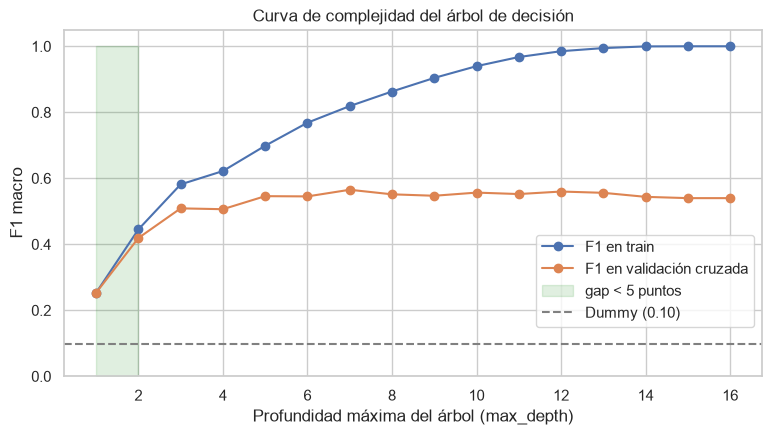

,profundidad,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap
0,1,0.253,0.253,❌ malo,-0.006,✅ correcto
1,2,0.445,0.419,⚠️ flojo,2.604,✅ correcto
2,3,0.581,0.509,✅ aceptable,7.263,❌ ligero sobreajuste
3,4,0.622,0.506,✅ aceptable,11.563,❌ sobreajuste grave
4,5,0.699,0.546,✅ aceptable,15.274,❌ sobreajuste grave
5,6,0.768,0.545,✅ aceptable,22.335,❌ sobreajuste grave
6,7,0.819,0.565,✅ aceptable,25.357,❌ sobreajuste grave
7,8,0.863,0.551,✅ aceptable,31.157,❌ sobreajuste grave


In [46]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import validation_curve

profundidades = np.arange(1, 17)
f1_train, f1_cv = validation_curve(
    arbol_libre, X_train, y_train,
    param_name="arbol__max_depth", param_range=profundidades,
    cv=cv, scoring="f1_macro",
)
media_train, media_cv = f1_train.mean(axis=1), f1_cv.mean(axis=1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(profundidades, media_train, marker="o", label="F1 en train")
ax.plot(profundidades, media_cv, marker="o", label="F1 en validación cruzada")
ax.fill_between(profundidades, 0, 1, where=100 * (media_train - media_cv) < GAP_MAXIMO,
                alpha=0.12, color="green", label="gap < 5 puntos")
ax.axhline(F1_DUMMY, linestyle="--", color="grey", label=f"Dummy ({F1_DUMMY:.2f})")
ax.set(xlabel="Profundidad máxima del árbol (max_depth)", ylabel="F1 macro",
       title="Curva de complejidad del árbol de decisión", ylim=(0, 1.05))
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.12))
plt.show()

curva = pd.DataFrame({
    "profundidad": profundidades,
    "F1 train": media_train,
    "F1 CV": media_cv,
    "nivel F1": [nivel_f1(f) for f in media_cv],
    "gap (puntos)": 100 * (media_train - media_cv),
    "nivel gap": [nivel_gap(100 * g) for g in media_train - media_cv],
})
curva.round(3).head(8)

**Qué vemos:** la línea de CV sube hasta la profundidad 5–7 (alrededor de 0.55) y después se queda plana, entre 0.54 y 0.57. En cambio, la de train sigue subiendo hasta 1.00. A partir de ahí, **más profundidad no mejora la validación: solo añade memoria**. Limitando solo la profundidad, el gap baja de 5 puntos únicamente con árboles de 1 o 2 niveles, que se quedan cortos (F1 en CV de 0.25 y 0.42).

Limitar la profundidad es una forma de frenar el árbol, pero no la única. En el paso 7 probamos también un **mínimo de parcelas por hoja** (`min_samples_leaf`): una hoja no se crea si no la respaldan suficientes parcelas, lo que evita las reglas a medida de 2 o 3 casos.

### 6.3 ¿Y si el árbol tuviera que predecir un sitio nuevo?

**Qué hacemos:** repetimos la validación cruzada con `StratifiedGroupKFold`, que pone **todas las parcelas de un mismo sitio en el mismo trozo**. Así, cuando se mide un trozo, el árbol no ha visto nunca ese sitio.

**Por qué:** el EDA mostró que el sitio marca mucho la clase. Con la validación normal, parcelas del mismo sitio caen en train y en el trozo de medida, y el árbol puede apoyarse en el sitio. El ADR-0002 acordó medir los dos casos: la validación normal para comparar modelos y la agrupada como comprobación.

**Cómo leer el resultado:** cuanto más baje el F1 respecto a la validación normal, más depende el modelo de conocer el sitio.

In [47]:
from comun import cv_por_sitio

cv_sitio = cv_por_sitio()  # StratifiedGroupKFold: cada sitio cae entero en un trozo
sitios = X_train["Abbrev"]

resultados.append(resumen_cv("Árbol sin límites, por sitio", arbol_libre,
                             cv_usado=cv_sitio, grupos=sitios))
mostrar(resultados)

REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.000,✅ correcto,0.000,❌ no supera
Árbol sin límites,1.000,0.540,✅ aceptable,46.018,❌ sobreajuste grave,44.289,✅ supera claramente
"Árbol sin límites, por sitio",1.000,0.403,⚠️ flojo,59.675,❌ sobreajuste grave,30.632,✅ supera claramente


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.320,0.200,0.064,0.200,0.097,0.000,0.155
Árbol sin límites,0.539,0.543,0.543,0.543,0.540,0.020,0.539
"Árbol sin límites, por sitio",0.431,0.415,0.440,0.415,0.403,0.052,0.421


**Qué vemos:** con sitios nunca vistos, el F1 cae de **0.54 a 0.40**, y la variación entre trozos se dispara (de ±0.02 a ±0.05). El árbol se apoya bastante en "de qué sitio es la parcela". Si la app se usa con parcelas de sitios nuevos, hay que esperar un rendimiento más cercano a 0.40 que a 0.54. Lo dejaremos escrito en la conclusión.

### Desbalance de clases

La guía propone, de más simple a más complejo: `class_weight="balanced"`, cambiar el umbral o remuestrear. Probamos la opción más simple dentro del paso 7. `class_weight="balanced"` hace que un error en una clase pequeña (`best`, `low`) pese más que uno en `good`.

### Preguntas de la guía (paso 6)
- **¿La diferencia entre modelos es real o está dentro del ruido de la validación cruzada?** Usamos la desviación entre los 5 trozos: diferencias menores de unos 0.02–0.03 puntos de F1 no son concluyentes.
- **¿Hay sobreajuste?** Sí, mucho: el árbol sin límites tiene un gap de 46 puntos.
- **¿Hay subajuste?** Con profundidad 1–2, sí: train y CV son bajos a la vez.
- **¿Necesito un modelo explicable?** El árbol es el modelo más explicable de los cuatro del equipo: se puede dibujar y leer como reglas *si… entonces…* (paso 9).

## Paso 7: ajuste de hiperparámetros (tuning)

**Qué hacemos:** con `GridSearchCV` probamos **120 combinaciones** de 4 hiperparámetros y medimos cada una con la misma validación cruzada.

| Hiperparámetro | Qué controla | Valores |
|---|---|---|
| `criterion` | Cómo mide el árbol lo "mezcladas" que quedan las clases tras una pregunta | `gini`, `entropy` |
| `max_depth` | Número máximo de preguntas encadenadas | 2, 3, 4, 5, 7, sin límite |
| `min_samples_leaf` | Mínimo de parcelas en cada hoja | 1, 5, 10, 20, 30 |
| `class_weight` | Si las clases pequeñas pesan más | ninguno, `balanced` |

La rejilla parte de la del ejemplo del workshop (`Pokemon_Legendary.ipynb`) y la amplía con `min_samples_leaf` y más profundidades.

**Por qué no basta con "la mejor nota":** por defecto, `GridSearchCV` se queda con la combinación de mayor F1 en CV, sin mirar el sobreajuste. Por eso le damos nuestra propia **regla de elección** (`refit`):
1. Descartar las combinaciones con un **gap mayor de 5 puntos** entre train y CV.
2. De las que quedan, quedarse con la de **mayor F1 en CV**.
3. Si hay empate, la **más simple**: menos profundidad y hojas más grandes.

**Cómo leer el resultado:** primero vemos qué habría elegido `GridSearchCV` "a ciegas" y después lo que elige nuestra regla.

In [48]:
from sklearn.model_selection import GridSearchCV

from comun import elegir_sin_sobreajuste

rejilla = {
    "arbol__criterion": ["gini", "entropy"],
    "arbol__max_depth": [2, 3, 4, 5, 7, None],
    "arbol__min_samples_leaf": [1, 5, 10, 20, 30],
    "arbol__class_weight": [None, "balanced"],
}

def tabla_resultados(cv_results):
    r = pd.DataFrame(cv_results)
    r["gap"] = 100 * (r["mean_train_score"] - r["mean_test_score"])  # en puntos
    return r

# Regla de elección (comun.py): mayor F1 en CV entre las que tienen gap < 5 puntos.
# Desempate: el árbol más simple (menos profundo y con hojas más grandes).
DESEMPATE = [("param_arbol__max_depth", True), ("param_arbol__min_samples_leaf", False)]

busqueda = GridSearchCV(
    arbol_libre, rejilla, cv=cv, scoring="f1_macro", return_train_score=True,
    refit=lambda r: elegir_sin_sobreajuste(r, DESEMPATE), n_jobs=-1,
)
busqueda.fit(X_train, y_train)

tabla = tabla_resultados(busqueda.cv_results_)
# Columnas legibles: un hiperparámetro por columna y las notas con nombres claros
legible = pd.DataFrame({
    "criterion": tabla["param_arbol__criterion"],
    "max_depth": tabla["param_arbol__max_depth"].fillna("sin límite"),
    "min_samples_leaf": tabla["param_arbol__min_samples_leaf"],
    "class_weight": tabla["param_arbol__class_weight"].fillna("ninguno"),
    "F1 train": tabla["mean_train_score"].round(3),
    "F1 CV": tabla["mean_test_score"].round(3),
    "F1 CV (desv.)": tabla["std_test_score"].round(3),
    "nivel F1": tabla["mean_test_score"].map(nivel_f1),
    "gap (puntos)": tabla["gap"].round(1),
    "nivel gap": tabla["gap"].map(nivel_gap),
})
a_ciegas = legible.loc[tabla["rank_test_score"].idxmin()]
elegida = legible.loc[busqueda.best_index_]
pd.DataFrame({"a ciegas (mayor F1)": a_ciegas, "nuestra regla": elegida})

,a ciegas (mayor F1),nuestra regla
criterion,entropy,entropy
max_depth,sin límite,4
min_samples_leaf,1,30
class_weight,ninguno,ninguno
F1 train,1.0,0.595
F1 CV,0.566,0.565
F1 CV (desv.),0.026,0.025
nivel F1,✅ aceptable,✅ aceptable
gap (puntos),43.4,3.0
nivel gap,❌ sobreajuste grave,✅ correcto


**Qué vemos:**
- **A ciegas**, `GridSearchCV` elegiría un árbol **sin límites** (`entropy`, sin profundidad máxima, hojas de 1 parcela). Tiene el mayor F1 en CV (0.566), pero acierta el 100 % de train: **gap de 43 puntos**. Incumple la regla del proyecto.
- **Nuestra regla** elige `entropy`, profundidad 4 y **30 parcelas por hoja como mínimo**. Su F1 en CV es **prácticamente el mismo (0.565)**, pero con un gap de solo **3 puntos**.

Es la lección principal de este notebook: **la combinación con la nota más alta no tiene por qué ser la mejor**. Un árbol con hojas grandes aprende lo mismo que uno que memoriza, pero generaliza.

Veamos las 5 mejores combinaciones que cumplen la regla. Varias son el **mismo árbol**: con 30 parcelas por hoja, el árbol ya no puede pasar de profundidad 4, y poner `max_depth` = 5, 7 o sin límite no cambia nada. Por eso, en caso de empate, la regla elige la menor profundidad.

In [49]:
cumple = tabla["gap"] < GAP_MAXIMO
print(f"Combinaciones que cumplen gap < 5 puntos: {cumple.sum()} de {len(tabla)}")
legible[cumple].sort_values("F1 CV", ascending=False).head(5)

Combinaciones que cumplen gap < 5 puntos: 42 de 120


,criterion,max_depth,min_samples_leaf,class_weight,F1 train,F1 CV,F1 CV (desv.),nivel F1,gap (puntos),nivel gap
59,entropy,sin límite,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
44,entropy,4,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
54,entropy,7,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
49,entropy,5,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
114,entropy,7,30,balanced,0.601,0.561,0.049,✅ aceptable,3.9,✅ correcto


### El árbol elegido, frente a los anteriores

**Qué hacemos:** añadimos el árbol elegido a la tabla de resultados, con la validación normal y con la validación por sitio.

**Cómo leer el resultado:** el árbol elegido debe tener un F1 en CV parecido al del árbol sin límites, pero un gap menor de 5 puntos.

In [50]:
mejor_arbol = busqueda.best_estimator_
print("Hiperparámetros elegidos:", {k.replace("arbol__", ""): v
                                    for k, v in busqueda.best_params_.items()})
print("Profundidad:", mejor_arbol["arbol"].get_depth(),
      "| hojas:", mejor_arbol["arbol"].get_n_leaves())

resultados.append(resumen_cv("Árbol elegido", mejor_arbol))
resultados.append(resumen_cv("Árbol elegido, por sitio", mejor_arbol,
                             cv_usado=cv_sitio, grupos=sitios))
mostrar(resultados)

Hiperparámetros elegidos: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 30}
Profundidad: 4 | hojas: 10
REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.000,✅ correcto,0.000,❌ no supera
Árbol sin límites,1.000,0.540,✅ aceptable,46.018,❌ sobreajuste grave,44.289,✅ supera claramente
"Árbol sin límites, por sitio",1.000,0.403,⚠️ flojo,59.675,❌ sobreajuste grave,30.632,✅ supera claramente
Árbol elegido,0.595,0.565,✅ aceptable,3.001,✅ correcto,46.818,✅ supera claramente
"Árbol elegido, por sitio",0.584,0.519,✅ aceptable,6.570,❌ ligero sobreajuste,42.165,✅ supera claramente


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.320,0.200,0.064,0.200,0.097,0.000,0.155
Árbol sin límites,0.539,0.543,0.543,0.543,0.540,0.020,0.539
"Árbol sin límites, por sitio",0.431,0.415,0.440,0.415,0.403,0.052,0.421
Árbol elegido,0.582,0.559,0.633,0.559,0.565,0.025,0.576
"Árbol elegido, por sitio",0.537,0.535,0.547,0.535,0.519,0.110,0.530


**Qué vemos en la tabla de requisitos:**

| | F1 CV | nivel gap | supera baseline |
|---|---|---|---|
| Árbol sin límites | 0.540 ✅ aceptable | ❌ sobreajuste grave (46) | ✅ +44 puntos |
| **Árbol elegido** | **0.565 ✅ aceptable** | **✅ correcto (3.0)** | **✅ +47 puntos** |

- El árbol elegido tiene **4 niveles y 10 hojas**, frente a los 16 niveles y 139 hojas del árbol sin límites. Es el único modelo hasta ahora que **cumple todos los requisitos** en la validación normal.
- **Por sitio**, el árbol elegido mejora mucho al árbol sin límites (0.52 frente a 0.40), porque con hojas de 30 parcelas no puede hacer reglas para 2 o 3 parcelas de un sitio concreto. Aun así sale ❌ *ligero sobreajuste* (6.6 puntos) y varía mucho entre repartos (±0.11). La regla de los 5 puntos se aplica a la validación normal (`docs/acuerdos.md`), pero lo anotamos como límite del modelo para sitios nuevos.

**Qué vemos en la tabla de métricas:** la **precision macro (0.63)** es más alta que el **recall macro (0.56)**: cuando el árbol dice "esta parcela es X", suele acertar, pero se le escapan parcelas de algunas clases. En el paso 8 veremos en la matriz de confusión cuáles. El F1 ponderado (0.58) es parecido al macro (0.565), así que el árbol no está descuidando las clases pequeñas en general.

### Preguntas de la guía (paso 7)
- **¿Vale la pena el tiempo?** Aquí sí. El tuning no sube mucho el F1, pero **elimina el sobreajuste**, y sin eso el modelo no cumpliría el proyecto.
- **¿Estoy sobreajustando a la validación de tanto probar combinaciones?** Es un riesgo real con 120 combinaciones. Lo controlamos de tres formas: cada combinación se mide con validación cruzada (5 repartos, no uno), la regla prefiere el árbol más simple en los empates, y `data/val.csv` no se ha usado para elegir. En el paso 8 lo comprobaremos: si el F1 en `val.csv` sale parecido al de la CV, no hemos sobreajustado la elección.

## Paso 8: evaluación con `val.csv`

**Qué hacemos:** por primera vez usamos `data/val.csv`, 110 parcelas que el árbol no ha visto nunca. El árbol elegido en el paso 7 ya está entrenado con todo `train.csv` (lo hace `GridSearchCV` al terminar). Ahora:
1. Predecimos la clase de cada parcela de validación.
2. A las **parcelas sin medidas** les ponemos `none` por regla, sin hacer caso al árbol (ADR-0001).
3. Calculamos los requisitos y las métricas dos veces: con **toda la validación** y **solo con las parcelas con medidas**.

**Por qué en validación y no en test (desviación consciente de la guía):** la guía hace la evaluación final en el test. En nuestro proyecto hay 4 modelos y el test solo puede usarse **una vez**, con el ganador, en `06_conclusiones`. Por eso cada modelo se evalúa aquí con `val.csv`, y esa nota es la que sirve para elegir al ganador (`docs/acuerdos.md`).

**Por qué dos veces:** 15 de las 110 parcelas de validación no tienen medidas y la regla las acierta todas, con cualquier modelo. Con toda la validación vemos lo que vería la app; solo con las parcelas con medidas vemos lo que **aporta de verdad el árbol**.

**Cómo leer el resultado:** primero, el **Dummy con la misma regla**, que es el baseline justo. Después, la evaluación común del equipo (`mostrar_evaluacion` de `comun.py`), que sale igual en los 4 modelos y tiene 4 bloques:
1. **Métricas en validación**: F1 macro con su nivel, puntos sobre el Dummy, accuracy, accuracy balanceada, precision, recall y F1 ponderado. Una fila con toda la validación y otra solo con medidas.
2. **Overfitting**: F1 en train menos F1 en validación con medidas, en puntos y con signo.
3. **Métricas por clase**: para cada una de las 5 clases (lo pide el enunciado), la **precision** (de lo que dice que es esa clase, qué parte lo es), el **recall** (de lo que es esa clase, qué parte encuentra), el F1 y el **soporte** (cuántas parcelas hay).
4. **Matrices de confusión**: filas = clase real y columnas = la que dice el árbol. La **diagonal** son los aciertos. Como las clases van de peor a mejor (`none` → `best`), **un error lejos de la diagonal es más grave**.

In [51]:
from comun import baseline_dummy, evaluar_val, mostrar_evaluacion, predecir_con_regla

X_val, y_val = separar_xy(val)
con_medidas = ~sin_medidas(X_val)  # True en las 95 parcelas con medidas
print(f"Parcelas de validación: {len(y_val)} "
      f"({con_medidas.sum()} con medidas y {(~con_medidas).sum()} sin medidas)")

# Baseline justo: el Dummy entrenado con train y con la misma regla "none"
f1_dummy = baseline_dummy(X_train, y_train, X_val, y_val)

Parcelas de validación: 110 (95 con medidas y 15 sin medidas)
El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.562,✅ aceptable,31.804,✅ supera claramente,0.636,0.565,0.661,0.565,0.608
solo con medidas,0.520,✅ aceptable,41.969,✅ supera claramente,0.579,0.528,0.617,0.528,0.548


2. OVERFITTING: F1 train 0.557 - F1 validación con medidas 0.520 = 3.6 puntos → ✅ correcto
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas                     
                 precision recall    f1 soporte        precision recall    f1 soporte
none                  0.79   0.85  0.82    27.0             0.57   0.67  0.62    12.0
low                   0.83   0.31  0.45    16.0             0.83   0.31  0.45    16.0
average               0.48   0.63  0.55    19.0             0.48   0.63  0.55    19.0
good                  0.60   0.84  0.70    32.0             0.60   0.84  0.70    32.0
best                  0.60   0.19  0.29    16.0             0.60   0.19  0.29    16.0

4. MATRICES DE CONFUSIÓN


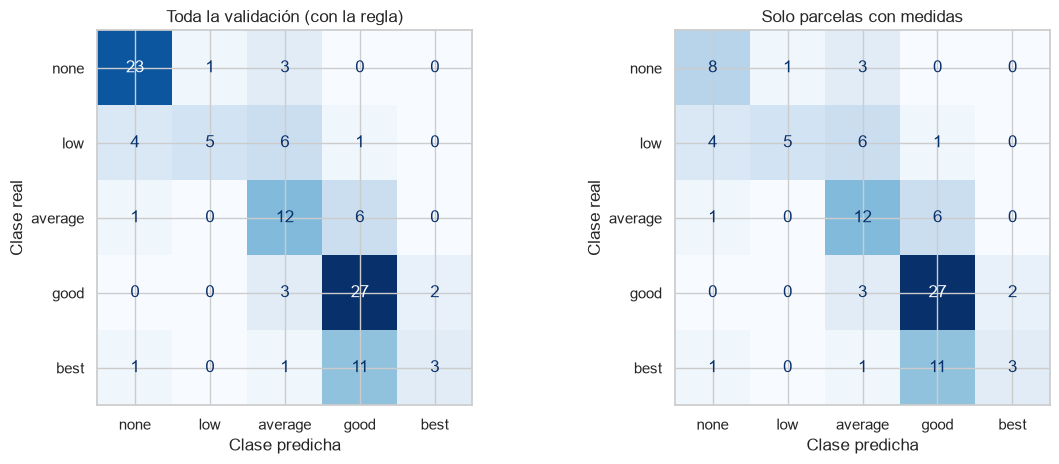

In [52]:
# Predice con la regla, calcula todas las métricas y el gap (train vs val con medidas)
ev = evaluar_val(mejor_arbol, X_train, y_train, X_val, y_val, f1_dummy)
mostrar_evaluacion(ev)

pred_arbol, F1_TRAIN_ARBOL = ev["pred"], ev["f1_train"]
ym, am = y_val[con_medidas], pred_arbol[con_medidas]  # solo parcelas con medidas

**Qué vemos en el Dummy y en los bloques 1 y 2:**

| | F1 val | gap | supera baseline |
|---|---|---|---|
| Toda la validación: árbol + regla | 0.562 ✅ aceptable | — | ✅ +32 puntos sobre el Dummy + regla |
| **Con medidas: árbol** | **0.520 ✅ aceptable** | **✅ correcto (3.6)** | **✅ +42 puntos** |

- **El gap se mide donde trabaja el árbol** (decisión del equipo): F1 en train 0.557 frente a 0.520 en las parcelas de validación con medidas, **3.6 puntos**. ✅ Cumple el requisito de overfitting.
- **La regla ayuda a todos por igual:** el Dummy pasa de 0.10 a 0.24 de F1 solo por acertar las 15 parcelas sin medidas. Por eso el baseline justo es el Dummy *con* la regla.
- **Con medidas, el árbol baja de 0.56 a 0.52:** las 15 parcelas sin medidas eran aciertos "gratis". 0.52 es la nota real del árbol.

**Qué vemos en el resto de métricas:** como en la validación cruzada, la **precision macro (0.62) es mayor que el recall macro (0.53)**. El árbol es "prudente": acierta cuando se decide por una clase, pero no encuentra muchas parcelas de algunas clases. Lo vemos clase a clase a continuación.

**Qué vemos en las métricas por clase (bloque 3):**
- **`good` (F1 0.70) y `none` (0.82 con la regla, 0.62 solo con medidas)** son las clases que mejor reconoce. `good` es la más numerosa en train y `none` tiene la ayuda de la regla.
- **`best` es el gran problema: recall de 0.19.** De 16 parcelas `best`, solo encuentra 3. Cuando dice `best` acierta (precision 0.60), pero casi nunca se atreve a decirlo.
- **`low` tiene un patrón parecido:** precision alta (0.83), recall bajo (0.31).
- **`average`** queda en medio (F1 0.55).

Fuera de `none`, las filas de las dos columnas son iguales: la regla solo cambia las parcelas `none` sin medidas.

**Qué vemos en las matrices de confusión (bloque 4):**
- **El error más frecuente: `best` predicho como `good` (11 de 16 parcelas `best`).** El árbol no consigue separar "muy buena" de "buena". Es un error entre clases **vecinas**, el menos grave.
- **`low` se reparte entre `average` (6) y `none` (4):** tampoco lo separa bien de sus vecinas.
- **Errores lejos de la diagonal** (a 2 o más clases de distancia) hay 7: 3 `none` predichas como `average`, 1 `low` como `good`, 1 `average` como `none`, 1 `best` como `average` y 1 `best` como `none` (el más grave). **33 de los 40 errores son entre clases vecinas** en la escala.
- La única diferencia entre las dos matrices es la casilla `none`/`none`: 23 con la regla y 8 sin ella. Las 15 de la regla son siempre aciertos.

En el paso 9 miraremos esas parcelas mal clasificadas para entender **por qué** se equivoca.

### ¿Rinde igual en todos los sitios? (subgrupos)

**Qué hacemos:** calculamos el % de aciertos de la validación en cada sitio.

**Por qué:** la guía pregunta *"¿Rinde igual en todos los subgrupos?"*. Nuestro subgrupo natural es el sitio.

**Cómo leer el resultado:** con pocas parcelas por sitio (algunos solo tienen 1 o 2 en validación), las diferencias pequeñas no significan nada. Fíjate solo en los extremos.

In [53]:
aciertos = pd.DataFrame({"sitio": X_val["Abbrev"], "acierto": y_val == pred_arbol,
                         "sin medidas": ~con_medidas})
por_sitio = aciertos.groupby("sitio").agg(
    parcelas=("acierto", "size"), aciertos=("acierto", "sum"),
    sin_medidas=("sin medidas", "sum"), pct_acierto=("acierto", "mean"),
).sort_values("pct_acierto")
print("Sitios de validación que no están en train:",
      sorted(set(X_val["Abbrev"]) - set(X_train["Abbrev"])))
print("Especies de validación que no están en train:",
      sorted(set(X_val["Sp"]) - set(X_train["Sp"])))
por_sitio.round(2)

Sitios de validación que no están en train: ['Mor', 'Wen']
Especies de validación que no están en train: ['ra', 'te']


,parcelas,aciertos,sin_medidas,pct_acierto
sitio,,,,
Cly,2,0,0,0.00
Nga,1,0,0,0.00
WSh,1,0,0,0.00
Cra,6,2,0,0.33
K82,5,2,0,0.40
K81,13,6,0,0.46
K83,8,4,0,0.50
Wak,8,4,0,0.50
K81a,6,4,0,0.67


**Qué vemos:**
- Los sitios **Mor** y **Wen** no aparecen en train: todas sus parcelas son sin medidas (se quitaron de train, ADR-0001), así que en validación las resuelve la regla.
- Hay **2 especies que el árbol no ha visto nunca** (`ra` y `te`). El `OrdinalEncoder` les da el valor −1 y el árbol no falla: esto es justo lo que preparamos con `handle_unknown` en el paso 3.
- El acierto varía mucho de un sitio a otro, pero la mayoría de sitios tienen menos de 10 parcelas en validación, demasiado pocas para sacar conclusiones por sitio. La comprobación seria por sitio es la del paso 6.3 (`StratifiedGroupKFold`).

### Preguntas de la guía (paso 8)
- **¿La métrica coincide con la definida en el paso 0?** Sí: F1 macro, con accuracy y métricas por clase al lado.
- **¿Rinde igual en todos los subgrupos?** No del todo: rinde peor con sitios nuevos (paso 6.3) y en las clases `best` y `low`. Por sitio, en validación hay demasiado pocas parcelas para concluir nada.
- **¿El resultado es parecido al de validación (aquí: al de la validación cruzada)?** Sí. F1 0.565 en CV y 0.562 en `val.csv` con la regla: **no hemos sobreajustado la elección de hiperparámetros** (la duda que dejamos abierta en el paso 7). El test se usará en `06_conclusiones`.
- **Calibración y umbral:** la guía sugiere no dejar el umbral por defecto. Con 5 clases y un modelo que no destaca por sus probabilidades (un árbol con 10 hojas solo da 10 valores de probabilidad distintos), no lo ajustamos. Lo dejamos como mejora posible para `best`.

## Paso 9: análisis de errores e interpretación

La gran ventaja del árbol es que **se puede abrir y leer**. En este paso vemos qué variables usa, qué reglas ha aprendido y por qué se equivoca.

### 9.1 Importancia de las variables (feature importance)

**Qué hacemos:** pedimos al árbol la importancia de cada variable (`feature_importances_`).

**Por qué:** el enunciado pide *feature importance*. En un árbol, la importancia de una variable es **cuánto ayudan sus preguntas a separar las clases**, sumado en todo el árbol. Las importancias suman 1 (el 100 %).

**Cómo leer el gráfico:** cuanto más larga la barra, más decide esa variable. Una barra de 0 quiere decir que el árbol no le hace ninguna pregunta a esa variable.

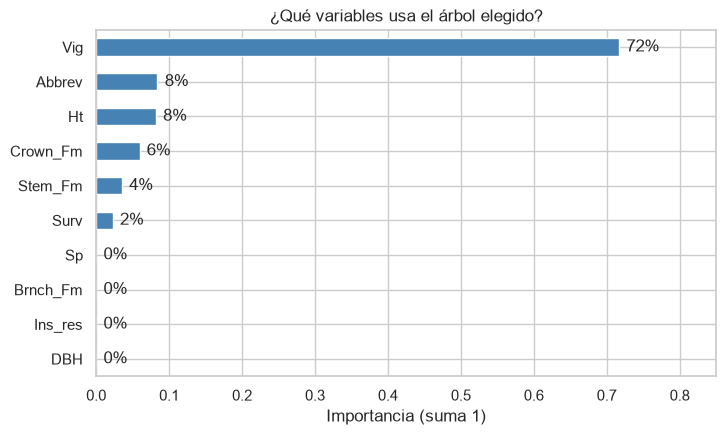

In [54]:
arbol = mejor_arbol["arbol"]
nombres = list(mejor_arbol["preprocesado"].get_feature_names_out())
importancia = pd.Series(arbol.feature_importances_, index=nombres).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
importancia.plot.barh(ax=ax, color="steelblue")
ax.set(xlabel="Importancia (suma 1)", title="¿Qué variables usa el árbol elegido?")
for y_pos, valor in enumerate(importancia):
    ax.text(valor + 0.01, y_pos, f"{valor:.0%}", va="center")
ax.set_xlim(0, 0.85)
plt.show()

**Qué vemos:**
- **El vigor (`Vig`) decide el 72 %.** Cuadra con el EDA, que ya señalaba el vigor como la medida más relacionada con la clase.
- Le siguen, muy por detrás, el **sitio** (`Abbrev`, 8 %), la **altura** (`Ht`, 8 %), la **forma de la copa** (`Crown_Fm`, 6 %), la **forma del tallo** (`Stem_Fm`, 4 %) y la **supervivencia** (`Surv`, 2 %).
- **La especie (`Sp`), el diámetro (`DBH`), la resistencia a insectos (`Ins_res`) y la forma de las ramas (`Brnch_Fm`) no se usan** (0 %). Con solo 10 hojas, el árbol se queda con las variables más útiles. Que `DBH` no aparezca es lógico: se parece mucho a la altura, y el árbol ya usa la altura.

### 9.2 El árbol dibujado

**Qué hacemos:** dibujamos el árbol completo con `plot_tree`, como en el ejemplo del workshop. Con 4 niveles y 10 hojas cabe entero.

**Cómo leer el dibujo:**
- Cada caja es una **pregunta** (arriba del todo, la primera). Si la respuesta es **sí**, se baja por la **izquierda**; si es **no**, por la **derecha**.
- `samples` = parcelas de train que llegan a esa caja; `class` = la clase que gana en esa caja.
- `value` = cuántas parcelas hay de cada clase, **en orden alfabético: `[average, best, good, low, none]`** (no en el orden de la escala). Por ejemplo, la hoja verde de abajo a la derecha tiene `value = [1, 25, 5, 0, 0]`: 1 `average`, 25 `best` y 5 `good`, así que dice `best`.
- El **color** indica la clase que gana, y la intensidad, lo segura que está esa caja.
- `Abbrev` está codificado como número (paso 3): debajo del dibujo está la tabla para traducirlo.

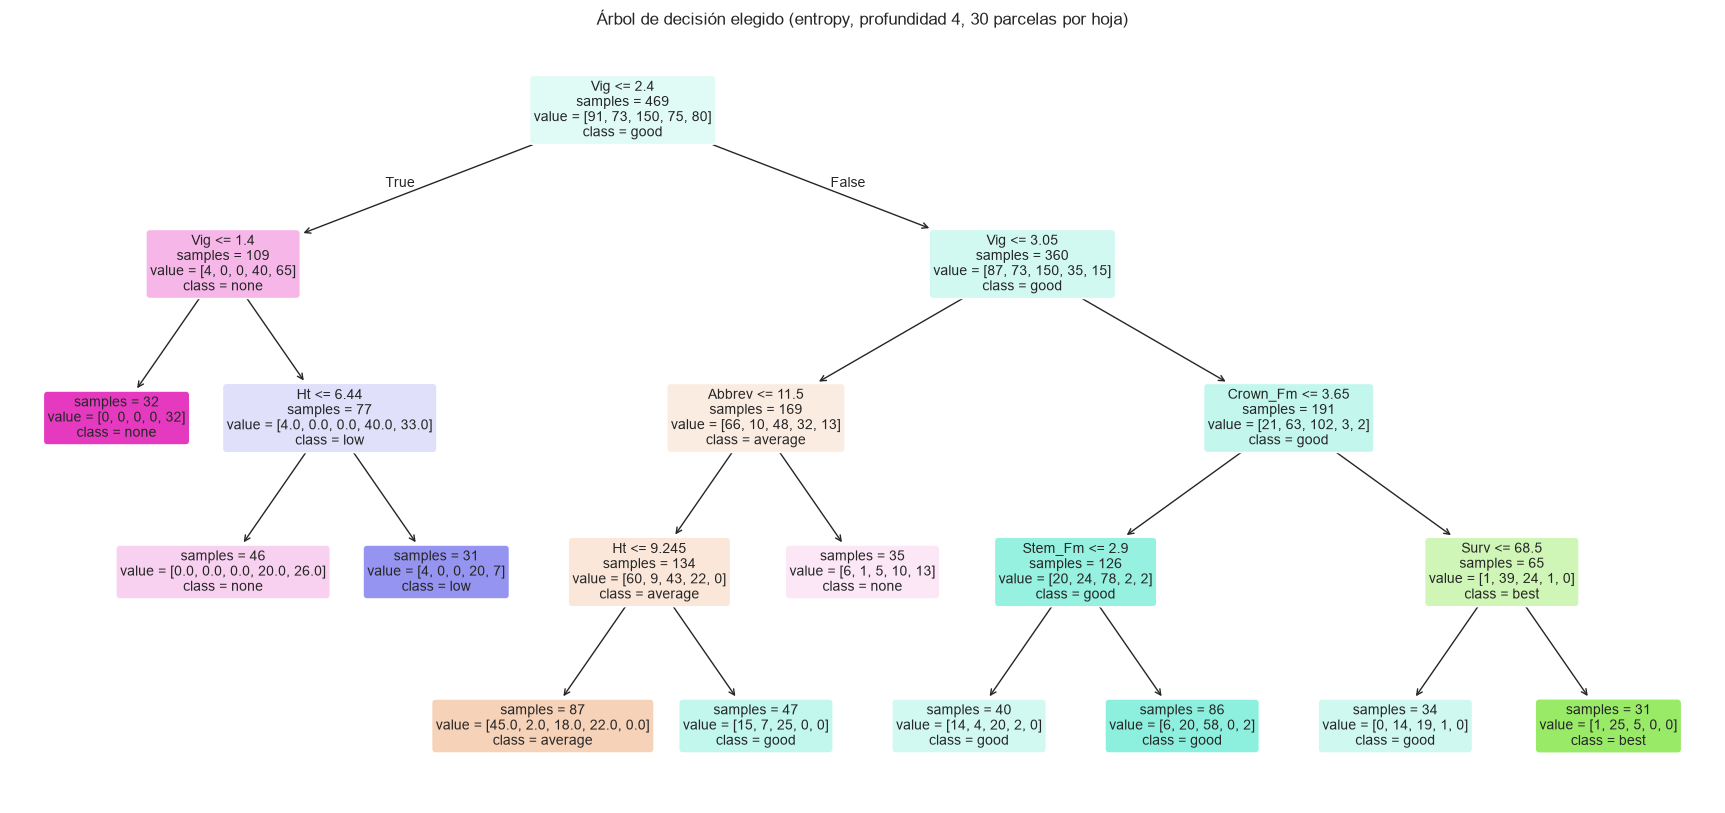

código Abbrev,0,1,2,3,4,5,6,7,8,9,10,11,12,13
sitio,Cly,Cra,K81,K81a,K82,K83,Lon,Nga,Paw,Puk,WSh,WSp,Wai,Wak


In [55]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(arbol, feature_names=nombres, class_names=list(arbol.classes_),
          filled=True, rounded=True, fontsize=10, impurity=False, ax=ax)
ax.set_title("Árbol de decisión elegido (entropy, profundidad 4, 30 parcelas por hoja)")
plt.show()

codificador = mejor_arbol["preprocesado"].named_transformers_["cat"]
codigos = pd.Series(codificador.categories_[0], name="sitio")
codigos.rename_axis("código Abbrev").to_frame().T

### 9.3 Las reglas en texto

**Qué hacemos:** sacamos las mismas reglas en texto con `export_text`, también como en el workshop.

**Cómo leer el resultado:** cada nivel de sangría es una pregunta más. Las líneas `class:` son las hojas, es decir, la respuesta final.

In [56]:
from sklearn.tree import export_text

print(export_text(arbol, feature_names=nombres))

|--- Vig <= 2.40
|   |--- Vig <= 1.40
|   |   |--- class: none
|   |--- Vig >  1.40
|   |   |--- Ht <= 6.44
|   |   |   |--- class: none
|   |   |--- Ht >  6.44
|   |   |   |--- class: low
|--- Vig >  2.40
|   |--- Vig <= 3.05
|   |   |--- Abbrev <= 11.50
|   |   |   |--- Ht <= 9.24
|   |   |   |   |--- class: average
|   |   |   |--- Ht >  9.24
|   |   |   |   |--- class: good
|   |   |--- Abbrev >  11.50
|   |   |   |--- class: none
|   |--- Vig >  3.05
|   |   |--- Crown_Fm <= 3.65
|   |   |   |--- Stem_Fm <= 2.90
|   |   |   |   |--- class: good
|   |   |   |--- Stem_Fm >  2.90
|   |   |   |   |--- class: good
|   |   |--- Crown_Fm >  3.65
|   |   |   |--- Surv <= 68.50
|   |   |   |   |--- class: good
|   |   |   |--- Surv >  68.50
|   |   |   |   |--- class: best



**Las reglas traducidas** (los números de vigor, forma y supervivencia son las puntuaciones del ensayo):

| Si… | entonces el árbol dice |
|---|---|
| vigor ≤ 1.4 | `none` |
| 1.4 < vigor ≤ 2.4 y altura ≤ 6.4 m | `none` |
| 1.4 < vigor ≤ 2.4 y altura > 6.4 m | `low` |
| 2.4 < vigor ≤ 3.05, sitio Wai o Wak (código > 11.5) | `none` |
| 2.4 < vigor ≤ 3.05, otro sitio, altura ≤ 9.2 m | `average` |
| 2.4 < vigor ≤ 3.05, otro sitio, altura > 9.2 m | `good` |
| vigor > 3.05 y copa ≤ 3.65 | `good` (2 hojas que dicen lo mismo) |
| vigor > 3.05, copa > 3.65 y supervivencia ≤ 68.5 % | `good` |
| **vigor > 3.05, copa > 3.65 y supervivencia > 68.5 %** | **`best`** (la única hoja `best`) |

**Qué vemos:**
- **Las reglas tienen sentido para un no experto:** poco vigor → poca utilidad; mucho vigor, buena copa y alta supervivencia → la mejor. El árbol ordena las clases casi igual que la escala `none` < `low` < `average` < `good` < `best`, sin que nadie se lo haya dicho.
- **Ojo con la regla del sitio:** "código > 11.5" significa "Wai o Wak", porque los códigos van por orden alfabético (paso 3). Es una regla sobre *qué sitio es*, no sobre una propiedad de la parcela, y por eso el árbol empeora con sitios nuevos (paso 6.3).
- **Hay 2 hojas `good` hermanas** (la pregunta sobre la forma del tallo no cambia la respuesta). El árbol las separa porque en una hay más mezcla de `best` que en la otra, aunque `good` gane en las dos.
- **Para llegar a `best` hacen falta tres condiciones a la vez.** Esto explica el recall tan bajo de `best` en el paso 8: muchas parcelas `best` cumplen el vigor, pero no la copa, y acaban en una hoja `good`. Lo comprobamos en el 9.4.

### 9.4 Mirar los errores uno a uno

**Qué hacemos:** listamos las parcelas de validación **con medidas** en las que el árbol se equivoca, con las variables que usa.

**Por qué:** la guía dice *"Mira los casos mal clasificados a mano. ¿Tienen algo en común?"*.

**Cómo leer el resultado:** primero, cuántos errores hay de cada tipo (clase real → clase predicha). Después, el detalle del error más frecuente.

In [57]:
from comun import errores_frecuentes

# Solo parcelas con medidas: las sin medidas las resuelve la regla y siempre acierta.
# "distancia" = cuántas clases hay entre la real y la predicha (2 o más = error grave)
errores_frecuentes(ym, am).head(8)

Errores: 40 de 95. Entre clases vecinas: 33; a 2 o más clases de distancia: 7.


,real,predicha,parcelas,distancia
0,best,good,11,1
1,average,good,6,1
2,low,average,6,1
3,low,none,4,1
4,none,average,3,2
5,good,average,3,1
6,good,best,2,1
7,best,average,1,2


In [58]:
# El error más frecuente: parcelas "best" que el árbol pone como "good".
# Las comparamos con las "best" que sí acierta.
best_val = X_val[con_medidas & (y_val == "best")].assign(predicha=pred_arbol)
best_val["resultado"] = np.where(best_val["predicha"] == "best", "acertada", "fallada")
print("¿Qué cumple cada parcela 'best' de las 3 condiciones de la hoja 'best'?")
best_val.assign(
    vigor_ok=best_val["Vig"] > 3.05,
    copa_ok=best_val["Crown_Fm"] > 3.65,
    superv_ok=best_val["Surv"] > 68.5,
)[["Abbrev", "Vig", "Crown_Fm", "Surv", "vigor_ok", "copa_ok", "superv_ok",
   "predicha", "resultado"]].sort_values("resultado")

¿Qué cumple cada parcela 'best' de las 3 condiciones de la hoja 'best'?


,Abbrev,Vig,Crown_Fm,Surv,vigor_ok,copa_ok,superv_ok,predicha,resultado
15,K81,4.5,4.0,88.0,True,True,True,best,acertada
63,Lon,3.5,4.0,88.0,True,True,True,best,acertada
75,Cra,5.0,4.0,90.0,True,True,True,best,acertada
1,Wai,5.0,3.0,100.0,True,False,True,good,fallada
5,K81,3.0,4.0,88.0,False,True,True,average,fallada
6,Cra,3.5,3.5,80.0,True,False,True,good,fallada
14,Wai,5.0,2.7,100.0,True,False,True,good,fallada
27,Wai,3.0,3.0,50.0,False,False,False,none,fallada
32,Nga,4.0,3.3,60.0,True,False,False,good,fallada
34,Cly,4.0,3.0,NaN,True,False,False,good,fallada


**Qué vemos:**
- **El error más frecuente es `best` → `good` (11 parcelas)**, y después `low` → `average` (6) y `average` → `good` (6).
- En las parcelas `best` se ve el motivo: las 3 acertadas cumplen las tres condiciones; de las 13 falladas, **a 12 les falla la copa** (forma de la copa ≤ 3.65). **La copa es el cuello de botella**, no el vigor: 11 de las 13 falladas tienen vigor alto.
  - Hay parcelas con **vigor 5 (el máximo) y supervivencia del 100 %** que se quedan en `good` solo porque su copa puntúa 2.5–3.0.
  - Una parcela `best` del sitio **Wai** con vigor 3.0 cae en la **regla del sitio** (vigor entre 2.4 y 3.05 en Wai o Wak → `none`) y sale `none`: el error más grave del árbol lo causa justo la regla frágil del sitio.
- Los errores `low` → `average` y `average` → `good` también son entre **clases vecinas**: el árbol acierta "la zona" de la escala, pero no el escalón exacto.

### Preguntas de la guía (paso 9)
- **¿El modelo se apoya en variables que tienen sentido?** Sí: vigor, altura, copa y supervivencia son medidas del árbol que un técnico forestal usaría. La única dudosa es el **sitio**, que funciona como un "atajo" y no sirve para sitios nuevos.
- **¿Aprendió algo absurdo?** Nada absurdo, pero sí una regla frágil: la del sitio con un código > 11.5. Si cambiaran los sitios o su orden alfabético, cambiaría su significado.
- **¿Qué datos adicionales ayudarían a corregir los errores?** Más parcelas `best` (solo hay 73 en train) y medidas que distingan `best` de `good` más allá del vigor y de la copa: en train, la frontera de la copa en 3.65 deja fuera a muchas `best` de validación. También se podría probar `class_weight="balanced"` u otro umbral para que el árbol se atreva más con `best`, a cambio de equivocarse más con `good`.

## Paso 10: guardar el modelo (despliegue)

**Qué hacemos:** guardamos el **pipeline completo** (preprocesado + árbol) en `models/03_arbol_decision.joblib` y comprobamos que se puede cargar y que predice igual.

**Por qué:**
- La guía insiste en guardar **el pipeline completo**, no solo el modelo. Si solo guardáramos el árbol, la app tendría que repetir a mano la imputación y la codificación, y cualquier diferencia daría predicciones distintas.
- El nombre del fichero sigue el contrato del equipo (`docs/acuerdos.md`): `06_conclusiones` y la app lo buscarán ahí.

**Importante:** la regla de las parcelas sin medidas **no está dentro del pipeline**. La aplica quien lo use: la app (#43) y `06_conclusiones`, con la misma función `predecir_con_regla` de `comun.py`.

In [59]:
import joblib
from sklearn.metrics import f1_score

from comun import guardar_modelo

# Guarda models/03_arbol_decision.joblib y comprueba que, recargado, predice igual
RUTA_MODELO = guardar_modelo(mejor_arbol, "03_arbol_decision", X_val)

# Lo cargamos de nuevo, como haría otra persona, y predecimos validación
modelo_cargado = joblib.load(RUTA_MODELO)
pred_cargado = predecir_con_regla(modelo_cargado, X_val)
print(f"F1 macro en validación del modelo cargado: "
      f"{f1_score(y_val, pred_cargado, average='macro'):.3f}")

Guardado: models/03_arbol_decision.joblib (6.1 KB). ¿Al recargarlo predice igual? ✅
F1 macro en validación del modelo cargado: 0.562


### Preguntas de la guía (paso 10)
- **¿Cómo sabré que el modelo empezó a fallar?** Vigilando si las nuevas parcelas se parecen a las de train: sobre todo **sitios o especies nuevos** y la distribución del vigor, la variable que más decide.
- **¿Cada cuánto hay que reentrenar?** Cuando haya ensayos de sitios nuevos, porque el árbol usa el sitio.
- **¿Qué pasa si el modelo se equivoca?** Casi todos los errores son entre clases vecinas. Para decisiones importantes (por ejemplo, descartar un lote), conviene que una persona revise las predicciones `good`, que esconden muchas `best`.

## Conclusión

### Comprobación de requisitos

**Qué hacemos:**
1. Con `conclusion_modelo` (de `comun.py`, igual para los 4 modelos) comprobamos los requisitos que se miden con código. Sale la tabla de requisitos R1–R6 y el resumen. Además, se guardan las cifras en `resultados/03_arbol_decision.json`, que es lo que lee `06_conclusiones` para elegir el modelo ganador.
2. Antes, repetimos las dos validaciones cruzadas del árbol elegido (`f1_por_fold`): son las cifras de CV que van al resumen.
3. Debajo, los requisitos que se comprueban leyendo el notebook (R7–R11).

In [60]:
from comun import conclusion_modelo, f1_por_fold

cv_elegido = f1_por_fold(mejor_arbol, X_train, y_train)
conclusion_modelo("03_arbol_decision", cv_elegido, ev, f1_dummy, busqueda.best_params_)

# Requisitos que se comprueban leyendo el notebook
pd.DataFrame([
    ("R7", "Accuracy, P/R/F1 por clase, matriz de confusión", "Enunciado",
     "Paso 8", "✅"),
    ("R8", "Feature importance", "Enunciado", "Paso 9.1", "✅"),
    ("R9", "Análisis de errores", "Enunciado", "Paso 9.4", "✅"),
    ("R10", "Preprocesado dentro del Pipeline", "Guía, paso 3", "Paso 3", "✅"),
    ("R11", "No usar data/test.csv", "Acuerdos", "No se lee", "✅"),
], columns=["id", "requisito", "fuente", "dónde", "cumple"]).set_index("id")

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.540,0.562
2,0.604,0.566
3,0.540,0.309
4,0.579,0.632
5,0.562,0.525


StratifiedKFold: F1 macro = 0.565 ± 0.025 | gap 3.0 puntos ✅ correcto
Por sitio:       F1 macro = 0.519 ± 0.110 | gap 6.6 puntos


,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,3.6 puntos,✅
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+42 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.565 / 0.519,✅
R6,Pipeline guardado,Acuerdos,models/03_arbol_decision.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.565,0.562,0.520
gap (puntos),3.001,NaN,3.611
supera Dummy (puntos),46.818,31.804,41.969


Resultados guardados en resultados/03_arbol_decision.json


,requisito,fuente,dónde,cumple
id,,,,
R7,"Accuracy, P/R/F1 por clase, matriz de confusión",Enunciado,Paso 8,✅
R8,Feature importance,Enunciado,Paso 9.1,✅
R9,Análisis de errores,Enunciado,Paso 9.4,✅
R10,Preprocesado dentro del Pipeline,"Guía, paso 3",Paso 3,✅
R11,No usar data/test.csv,Acuerdos,No se lee,✅


### Resumen

| | Validación cruzada | `val.csv` con regla | `val.csv` solo con medidas |
|---|---|---|---|
| F1 macro | 0.565 | 0.562 | 0.520 |
| Gap | 3.0 ✅ | — | 3.6 ✅ |
| Supera al Dummy | +47 puntos | +32 puntos | +42 puntos |

- **Modelo:** árbol de decisión `entropy`, profundidad 4, mínimo 30 parcelas por hoja (10 hojas), guardado en `models/03_arbol_decision.joblib`.
- **Lo que hace bien:** es muy interpretable (9 reglas que se leen en una tabla), no sobreajusta y reconoce bien `good`, `none` y, en menor medida, `average`.
- **Lo que hace mal:** casi nunca predice `best` (recall 0.19): lo confunde con `good`. También le cuesta `low`.
- **Límites:**
  1. Solo vale para parcelas con medidas; las demás van por la regla `none`.
  2. Con **sitios nuevos** rinde peor (F1 ~0.52 en la validación por sitio, muy variable), porque usa el sitio en una de sus reglas.
  3. Los resultados describen estos ensayos de Nueva Zelanda, no a todos los eucaliptos.
- **Lección principal:** la combinación con mejor nota en la validación cruzada era un árbol que memorizaba (gap de 43 puntos). Meter la regla del overfitting **dentro** de la elección de hiperparámetros dio un árbol igual de bueno y 14 veces más pequeño.

**Siguiente paso:** este modelo entra en la comparación de `06_conclusiones` (#42) con los otros tres. Allí se elige el modelo ganador y se evalúa, una sola vez, con `data/test.csv`.

# Modelo SVM: utilidad de las parcelas de eucalipto

**Proyecto:** clasificación multiclase de la utilidad para la conservación del suelo de parcelas de eucalipto (dataset Eucalyptus).
**Historia:** #40 · **Notebook:** `04_svm.ipynb`

Este notebook sigue la plantilla común de `docs/acuerdos.md`: carga los CSV con `comun.py`, entrena un SVM dentro de un `Pipeline`, mide con las dos validaciones cruzadas, evalúa en validación, interpreta el modelo y guarda el pipeline y las cifras.

- **Datos:** `data/train.csv` y `data/val.csv`. El conjunto de prueba no se lee: se reserva para `06_conclusiones`.
- **Regla de las parcelas sin medidas:** ADR-0001. Si faltan las seis medidas, se responde `none` sin llamar al modelo.
- **Validación:** `StratifiedKFold` de 5 folds y, aparte, `StratifiedGroupKFold` por sitio (ADR-0002).
- **Overfitting:** gap = F1 macro de train − F1 macro de validación con medidas, con signo; debe ser menor de 5 puntos.

## Apunte Elena: el cuento del modelo

Imagina que tenemos 736 árboles de eucalipto y queremos adivinar si son none, low, average, good o best. Hicimos una “máquina adivinadora” y la entrenamos.

- Separamos los árboles en tres grupos: unos para practicar (train), otros para probar lo aprendido (val) y otros guardados para el examen final (test), que no miramos.
- La máquina (SVM) mira pistas: lo vigoroso que está el árbol, si sobrevivió, su altura, su diámetro y el sitio donde se plantó.
- Regla especial: si a un árbol le faltan todas las medidas, no preguntamos a la máquina: respondemos none directamente.
- Practicamos 5 veces con trozos distintos de los datos (validación cruzada) y también por sitios, para ver si hacía trampas aprovechando que árboles del mismo sitio se parecen.
- Resultado: sacó una nota de 0,636 sobre 1 en la prueba (0,601 solo con parcelas medidas). Comprobamos que no se había “aprendido de memoria” las respuestas: no hay sobreajuste.
- Descubrimos las pistas más útiles: el vigor es la más importante, luego la supervivencia, la altura y el diámetro.
- Sus errores típicos: confunde best con good, como confundir “muy bueno” con “bueno”.
- Guardamos la máquina en una caja (`models/04_svm.joblib`) para que la app pueda usarla más tarde.

## Pasos 0, 1 y 2: problema, split y EDA (ya hechos)

| Paso | Dónde está | Resumen |
|---|---|---|
| 0. Definir el problema | `00_general.ipynb` | Predecir `Utility` en 5 clases ordenadas (`none` < `low` < `average` < `good` < `best`). Métrica principal: **F1 macro**; sobreajuste < 5 puntos. |
| 1. Datos y split | `01_eda.ipynb`, sección 10 | Split estratificado 70/15/15 con semilla 42 y CSV en `data/`. |
| 2. EDA | `01_eda.ipynb` y `docs/informe-eda.md` | El **sitio** marca mucho la clase; el **vigor** es la medida más relacionada; hay parcelas sin medidas que son todas `none`. |

Aquí empezamos en el preprocesado y el modelo.

## Paso 1 (bis): cargar los datos con `comun.py`

**Qué hacemos:** importamos la librería común y leemos `train.csv` y `val.csv`. `comun.py` concentra las reglas del equipo: semilla, orden de las clases, regla `none`, validaciones y evaluación.

**Cómo leer el resultado:** comprobamos el tamaño de cada conjunto y cuántas parcelas hay de cada clase.

In [61]:
import pandas as pd

from comun import CLASES, OBJETIVO, cargar_datos, separar_xy  # noqa: F401

train, val = cargar_datos()  # data/train.csv y data/val.csv; el test no se lee aquí

print(f"train: {train.shape[0]} filas x {train.shape[1]} columnas")
print(f"val:   {val.shape[0]} filas x {val.shape[1]} columnas")

pd.DataFrame({
    "train": train[OBJETIVO].value_counts(),
    "val": val[OBJETIVO].value_counts(),
}).reindex(CLASES)

train: 469 filas x 13 columnas
val:   110 filas x 13 columnas


,train,val
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


### Las parcelas sin medidas

**Qué hacemos:** contamos las parcelas a las que les faltan **todas** las medidas del árbol.

**Por qué:** según el ADR-0001, esas parcelas no pasan por el modelo: se predicen `none` por regla fija. En train deben ser 0 (ya se quitaron); en validación son 15, todas de clase `none`.

In [62]:
from comun import MEDIDAS, sin_medidas  # noqa: F401

print("Parcelas sin medidas en train:", sin_medidas(train).sum())
print("Parcelas sin medidas en val:  ", sin_medidas(val).sum())
print("Clase de las de val:", val.loc[sin_medidas(val), OBJETIVO].value_counts().to_dict())

Parcelas sin medidas en train: 0
Parcelas sin medidas en val:   15
Clase de las de val: {'none': 15}


## Paso 3: preprocesado

| Tipo de columna | Columnas | Tratamiento |
|---|---|---|
| Numéricas | `DBH`, `Ht`, `Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm` | Imputar la mediana y **estandarizar** |
| Categóricas | `Abbrev` (sitio) | One-hot con `handle_unknown="ignore"` |

**Por qué:**
- El SVM es sensible a la escala: una variable con valores grandes pesaría más solo por su tamaño. Por eso se estandariza.
- Faltan valores en `Surv` (parcelas del sitio Cly) y en un `DBH` (el diámetro erróneo de 42 085 cm, convertido en hueco). Se imputan con la mediana.
- Se excluyen `Rep` y `PMCno` por ser identificadores y `Sp` porque tiene 25 especies, muchas con 2 o 3 parcelas; en un SVM lineal, 25 columnas one-hot tan dispersas aumentan el sobreajuste sin mejorar el F1 de la validación cruzada. El **sitio** (`Abbrev`) sí entra.

Todo el preprocesado va dentro del `Pipeline`, así se ajusta **solo con train**.

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from comun import NUMERICAS

CATEGORICAS = ["Abbrev"]
VARIABLES = NUMERICAS + CATEGORICAS

X_train, y_train = separar_xy(train, VARIABLES)
X_val, y_val = separar_xy(val, VARIABLES)

print("Variables del modelo:", VARIABLES)
print("Excluidas:", [c for c in train.columns if c not in VARIABLES + [OBJETIVO]])

preprocesado = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputar", SimpleImputer(strategy="median")),
                ("escalar", StandardScaler()),
            ]),
            NUMERICAS,
        ),
        (
            "cat",
            Pipeline([
                ("imputar", SimpleImputer(strategy="most_frequent")),
                ("codificar", OneHotEncoder(handle_unknown="ignore")),
            ]),
            CATEGORICAS,
        ),
    ],
    remainder="drop",
)

Variables del modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev']
Excluidas: ['Rep', 'Sp', 'PMCno']


## Paso 4: baseline (el mínimo a superar)

**Qué hacemos:** medimos un `DummyClassifier`, que no mira los datos y siempre responde la clase más frecuente (`good`), con la misma regla `none` para las parcelas sin medidas.

**Por qué:** la guía pide una referencia. Si el SVM no supera claramente al Dummy, no está aprendiendo nada útil. `baseline_dummy` de `comun.py` devuelve el F1 en CV, en toda la validación y solo con las parcelas con medidas.

In [64]:
from comun import baseline_dummy

f1_dummy = baseline_dummy(X_train, y_train, X_val, y_val)

El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


## Paso 5: entrenamiento y validación cruzada

**Qué hacemos:** montamos el `Pipeline` con un SVM lineal y lo evaluamos con las dos validaciones cruzadas de `comun.py`:

- `StratifiedKFold` de 5 folds, el esquema común.
- `StratifiedGroupKFold` por `Abbrev`, para ver cuánto se infla la métrica cuando el modelo ve parcelas del mismo sitio en train y validación (ADR-0002).

**Cómo leer el resultado:** miramos el F1 macro medio y el **gap** (F1 train − F1 CV). Un gap grande significa que el modelo memoriza train.

Primero con un `C = 1` (poca regularización) para ver el problema.

In [65]:
from sklearn.svm import SVC

from comun import SEMILLA, f1_por_fold

modelo_base = Pipeline([
    ("preprocesado", preprocesado),
    ("svm", SVC(kernel="linear", C=1.0, random_state=SEMILLA)),
])

cv_base = f1_por_fold(modelo_base, X_train, y_train)

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.572,0.583
2,0.675,0.517
3,0.585,0.394
4,0.560,0.671
5,0.446,0.592


StratifiedKFold: F1 macro = 0.568 ± 0.073 | gap 15.0 puntos ❌ sobreajuste grave
Por sitio:       F1 macro = 0.551 ± 0.093 | gap 13.8 puntos


**Qué vemos:** con `C = 1` el F1 de train es mucho mayor que el de validación cruzada: el SVM lineal se está ajustando demasiado a train. El gap supera claramente los 5 puntos.

## Paso 6: ajuste de hiperparámetros

**Qué hacemos:** probamos varios valores de `C` (la regularización) con `GridSearchCV`. Un `C` pequeño obliga al modelo a ser más conservador; uno grande le deja ajustarse más a train.

**Regla común:** `elegir_sin_sobreajuste` elige, entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro. Si ninguna cumple, avisa y elige la de menor gap. Así no elegimos solo por la nota más alta.

**Cómo leer la tabla:** `F1 CV` es la nota en validación cruzada; `gap` es train − CV en puntos. La fila elegida debe tener buen F1 y gap controlado.

In [66]:
from sklearn.model_selection import GridSearchCV

from comun import cv_comun, elegir_sin_sobreajuste

modelo = Pipeline([
    ("preprocesado", preprocesado),
    ("svm", SVC(kernel="linear", random_state=SEMILLA)),
])

rejilla = {"svm__C": [0.02, 0.03, 0.045, 0.07, 0.1, 0.3, 0.7, 1.0]}

busqueda = GridSearchCV(
    modelo,
    rejilla,
    scoring="f1_macro",
    cv=cv_comun(),
    return_train_score=True,
    refit=lambda resultados: elegir_sin_sobreajuste(resultados),
)
busqueda.fit(X_train, y_train)

tabla_tuning = pd.DataFrame(busqueda.cv_results_)
tabla_tuning["gap"] = 100 * (
    tabla_tuning["mean_train_score"] - tabla_tuning["mean_test_score"]
)
tabla_tuning = tabla_tuning[[
    "param_svm__C", "mean_test_score", "std_test_score", "mean_train_score", "gap"
]]
tabla_tuning.columns = ["C", "F1 CV", "desviación", "F1 train (CV)", "gap (puntos)"]
display(tabla_tuning.sort_values("F1 CV", ascending=False).round(3))

i = busqueda.best_index_
print(f"C elegido: {busqueda.best_params_['svm__C']}")
print(f"F1 macro en CV: {busqueda.cv_results_['mean_test_score'][i]:.3f}")
print(f"Gap en CV: {tabla_tuning.loc[i, 'gap (puntos)']:.1f} puntos")

,C,F1 CV,desviación,F1 train (CV),gap (puntos)
3,0.070,0.584,0.096,0.647,6.301
2,0.045,0.582,0.085,0.627,4.533
6,0.700,0.574,0.077,0.707,13.238
4,0.100,0.574,0.083,0.655,8.117
7,1.000,0.568,0.073,0.718,15.029
5,0.300,0.568,0.089,0.689,12.188
1,0.030,0.551,0.067,0.602,5.090
0,0.020,0.477,0.046,0.537,5.971


C elegido: 0.045
F1 macro en CV: 0.582
Gap en CV: 4.5 puntos


**Qué vemos:** `C = 0.07` tiene el F1 de CV más alto, pero su gap supera los 5 puntos. La regla común elige **`C = 0.045`**, que pierde muy poco F1 y sí controla el gap. Es la lección del paso: la combinación con la nota más alta no siempre es la mejor si memoriza.

## Paso 7: evaluación con `val.csv`

**Qué hacemos:** usamos `evaluar_val` y `mostrar_evaluacion` de `comun.py` con el modelo elegido. El modelo se entrena con todo `train.csv` (lo hace `GridSearchCV` al terminar) y predice `val.csv`.

Antes de medir se aplica la regla del ADR-0001: las 15 parcelas sin medidas se predicen `none` sin pasar por el SVM. Las métricas se dan dos veces: con **toda la validación** y **solo con las parcelas con medidas**, que es donde trabaja el modelo.

1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.636,✅ aceptable,39.222,✅ supera claramente,0.709,0.631,0.755,0.631,0.679
solo con medidas,0.601,✅ aceptable,49.999,✅ supera claramente,0.663,0.603,0.715,0.603,0.631


2. OVERFITTING: F1 train 0.631 - F1 validación con medidas 0.601 = 3.0 puntos → ✅ correcto
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas                     
                 precision recall    f1 soporte        precision recall    f1 soporte
none                  0.80   0.89  0.84    27.0             0.60   0.75  0.67    12.0
low                   0.64   0.44  0.52    16.0             0.64   0.44  0.52    16.0
average               0.69   0.58  0.63    19.0             0.69   0.58  0.63    19.0
good                  0.65   1.00  0.79    32.0             0.65   1.00  0.79    32.0
best                  1.00   0.25  0.40    16.0             1.00   0.25  0.40    16.0

4. MATRICES DE CONFUSIÓN


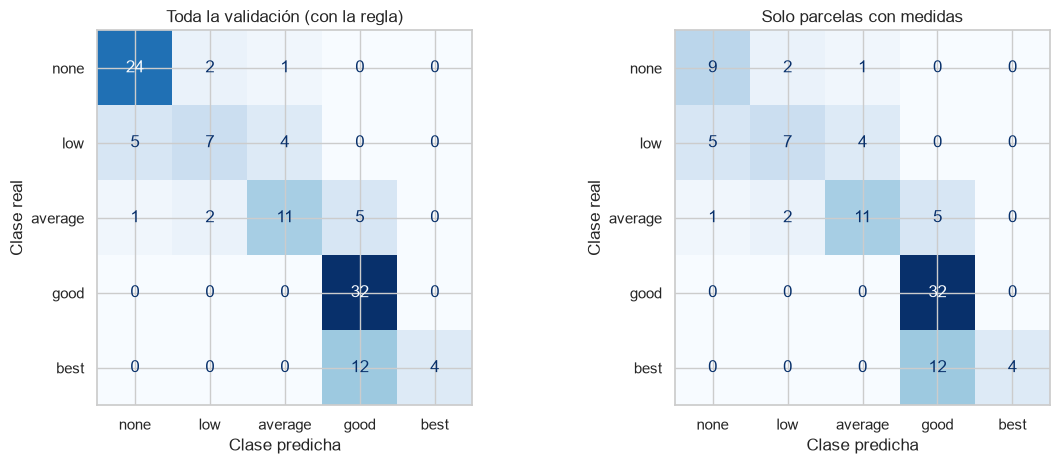

In [67]:
from comun import evaluar_val, mostrar_evaluacion

mejor_modelo = busqueda.best_estimator_
ev = evaluar_val(mejor_modelo, X_train, y_train, X_val, y_val, f1_dummy)
mostrar_evaluacion(ev)

### La regla `none` en validación

**Qué hacemos:** comprobamos que las 15 parcelas sin medidas no pasan por el modelo y se predicen `none` por regla fija (ADR-0001).

In [68]:
sin_medidas_val = ~ev["medidas"]
print(f"Parcelas sin medidas en validación: {sin_medidas_val.sum()}")
print("Predicciones para esas parcelas:", ev["pred"][sin_medidas_val].unique())
print("¿Todas son none?", (ev["pred"][sin_medidas_val] == "none").all())

Parcelas sin medidas en validación: 15
Predicciones para esas parcelas: ['none']
¿Todas son none? True


### Celda de overfitting

**Qué hacemos:** mostramos el gap de F1 macro (train − validación con medidas) y si cumple el máximo de 5 puntos.

In [69]:
from comun import GAP_MAXIMO, nivel_gap

print(
    f"Gap = F1 train ({ev['f1_train']:.3f}) - F1 validación con medidas "
    f"({ev['filas']['solo con medidas']['F1 macro']:.3f}) = {ev['gap']:.1f} puntos"
)
print(f"¿Menor de {GAP_MAXIMO} puntos? {ev['cumple_gap']} → {nivel_gap(ev['gap'])}")

Gap = F1 train (0.631) - F1 validación con medidas (0.601) = 3.0 puntos
¿Menor de 5 puntos? True → ✅ correcto


**Qué vemos:**
- **Gap 3.0 puntos**: F1 de train 0.631 frente a F1 de validación con medidas 0.601. Cumple el criterio de menos de 5 puntos.
- **F1 macro 0.636** en toda la validación (0.601 solo con medidas). El SVM supera claramente al Dummy, que se queda en 0.244 en toda la validación.
- **Clases:** `good` y `none` son las que mejor reconoce. `best` es la peor: casi no la predice (recall 0.25), aunque cuando la dice acierta (precision 1.00). `low` también se queda corta (recall 0.44).
- **Matriz de confusión:** el error más frecuente es `best` → `good` (12 casos), seguido de `average` → `good` (5) y `low` → `none` (5). Casi todos los errores son entre clases vecinas.

## Paso 8: interpretación

### 8.1 Importancia de las variables

**Qué hacemos:** `importancia_permutacion` mide cuánto cae el F1 macro al desordenar cada variable en la validación con medidas.

**Cómo leer el gráfico:** la barra más larga es la variable que más ayuda a acertar. Las barras cercanas a 0 son variables que el modelo puede desordenar sin empeorar.

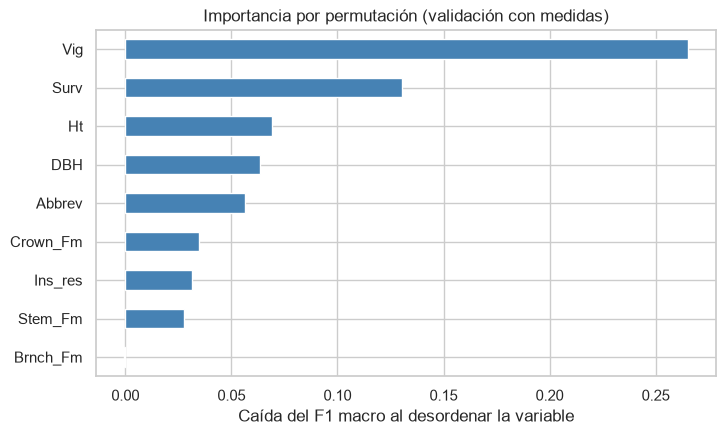

,importancia
Vig,0.265
Surv,0.130
Ht,0.069
DBH,0.064
Abbrev,0.056
Crown_Fm,0.035
Ins_res,0.031
Stem_Fm,0.028
Brnch_Fm,-0.000


In [70]:
from comun import importancia_permutacion

importancia = importancia_permutacion(mejor_modelo, X_val, y_val)
display(importancia.sort_values(ascending=False).to_frame("importancia").round(3))

**Qué vemos:** el **vigor** (`Vig`) es la variable más importante con diferencia (0.265), seguida de la **supervivencia** (`Surv`, 0.130), la **altura** (`Ht`, 0.069), el **diámetro** (`DBH`, 0.064) y el **sitio** (`Abbrev`, 0.056). Cuadra con el EDA: el vigor era la medida más relacionada con la clase. Las formas (`Crown_Fm`, `Ins_res`, `Stem_Fm`, `Brnch_Fm`) aportan poco.

### 8.2 Análisis de errores

**Qué hacemos:** `errores_frecuentes` cuenta los pares real → predicha y marca la distancia entre clases en la escala ordenada. Los errores a 2 o más clases de distancia son los graves.

In [71]:
from comun import errores_frecuentes

errores = errores_frecuentes(ev["y"][ev["medidas"]], ev["pred"][ev["medidas"]])
display(errores)

Errores: 32 de 95. Entre clases vecinas: 30; a 2 o más clases de distancia: 2.


,real,predicha,parcelas,distancia
0,best,good,12,1
1,average,good,5,1
2,low,none,5,1
3,low,average,4,1
4,none,low,2,1
5,average,low,2,1
6,average,none,1,2
7,none,average,1,2


**Qué vemos:**
- **32 errores de 95 parcelas con medidas.** 30 son entre clases vecinas y solo 2 saltan dos clases: el modelo se equivoca sobre todo en los límites.
- **El error dominante es `best` → `good` (12 parcelas).** El SVM prefiere `good` y casi nunca se atreve con `best`; cuando lo hace, acierta. Es el mismo patrón que en el árbol de decisión: `best` es la clase más difícil.
- Después aparecen `average` → `good` (5), `low` → `none` (5) y `low` → `average` (4). `good` tiene recall 1.00: el modelo lo predice mucho, a costa de "comerse" parte de `best` y `average`.
- **Idea para mejorar:** el SVM lineal no separa bien `best` de `good`; un kernel no lineal o más variables de forma podrían ayudar, pero habría que vigilar el sobreajuste.

## Paso 9: guardar el modelo

**Qué hacemos:** `guardar_modelo` guarda el **pipeline completo** (preprocesado + SVM) en `models/04_svm.joblib` y comprueba que, al recargarlo, predice igual.

**Por qué:** la app y `06_conclusiones` cargarán ese fichero. Si solo guardáramos el SVM, habría que repetir a mano la imputación, el escalado y el one-hot, y las predicciones podrían cambiar. La regla `none` no va dentro del pipeline: la aplica quien lo use con `predecir_con_regla`.

In [72]:
import joblib
from sklearn.metrics import f1_score

from comun import guardar_modelo, predecir_con_regla

RUTA_MODELO = guardar_modelo(mejor_modelo, "04_svm", X_val)

modelo_cargado = joblib.load(RUTA_MODELO)
pred_cargado = predecir_con_regla(modelo_cargado, X_val)
print(
    "F1 macro en validación del modelo cargado: "
    f"{f1_score(y_val, pred_cargado, average='macro'):.3f}"
)

Guardado: models/04_svm.joblib (106.9 KB). ¿Al recargarlo predice igual? ✅
F1 macro en validación del modelo cargado: 0.636


### Comprobación en una sesión nueva

Simulamos lo que hará otra persona: leer `data/val.csv` de nuevo desde disco, cargar el `.joblib` y predecir. Si no hay errores y salen 110 filas, el contrato de modelos se cumple.

In [73]:
train_fresco, val_fresco = cargar_datos()
X_val_fresco, y_val_fresco = separar_xy(val_fresco, VARIABLES)
modelo_nuevo = joblib.load("models/04_svm.joblib")
pred_nuevo = predecir_con_regla(modelo_nuevo, X_val_fresco)

print(f"Filas predichas sobre data/val.csv: {len(pred_nuevo)}")
print(f"F1 macro: {f1_score(y_val_fresco, pred_nuevo, average='macro'):.3f}")
assert len(pred_nuevo) == len(y_val_fresco)

Filas predichas sobre data/val.csv: 110
F1 macro: 0.636


## Conclusión

**Qué hacemos:** llamamos a `conclusion_modelo` de `comun.py`, que comprueba los requisitos R1–R6 y guarda las cifras en `resultados/04_svm.json` para que `06_conclusiones` pueda comparar los modelos. Después añadimos los requisitos que se comprueban leyendo el notebook (R7–R11).

In [74]:
from comun import conclusion_modelo, f1_por_fold

cv_elegido = f1_por_fold(mejor_modelo, X_train, y_train)
conclusion_modelo("04_svm", cv_elegido, ev, f1_dummy, busqueda.best_params_)

pd.DataFrame([
    ("R7", "Accuracy, P/R/F1 por clase y matriz de confusión", "Enunciado", "Paso 7", "✅"),
    ("R8", "Feature importance", "Enunciado", "Paso 8.1", "✅"),
    ("R9", "Análisis de errores", "Enunciado", "Paso 8.2", "✅"),
    ("R10", "Preprocesado dentro del Pipeline", "Guía, paso 3", "Paso 3", "✅"),
    ("R11", "No usar el conjunto de prueba", "Acuerdos", "No se lee", "✅"),
], columns=["id", "requisito", "fuente", "dónde", "cumple"]).set_index("id")

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.635,0.620
2,0.681,0.464
3,0.634,0.375
4,0.482,0.651
5,0.477,0.428


StratifiedKFold: F1 macro = 0.582 ± 0.085 | gap 4.5 puntos ✅ correcto
Por sitio:       F1 macro = 0.507 ± 0.108 | gap 11.6 puntos


,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,3.0 puntos,✅
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+50 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.582 / 0.507,✅
R6,Pipeline guardado,Acuerdos,models/04_svm.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.582,0.636,0.601
gap (puntos),4.533,NaN,3.024
supera Dummy (puntos),48.483,39.222,49.999


Resultados guardados en resultados/04_svm.json


,requisito,fuente,dónde,cumple
id,,,,
R7,"Accuracy, P/R/F1 por clase y matriz de confusión",Enunciado,Paso 7,✅
R8,Feature importance,Enunciado,Paso 8.1,✅
R9,Análisis de errores,Enunciado,Paso 8.2,✅
R10,Preprocesado dentro del Pipeline,"Guía, paso 3",Paso 3,✅
R11,No usar el conjunto de prueba,Acuerdos,No se lee,✅


### Resumen

| | Validación cruzada | `val.csv` con regla | `val.csv` solo con medidas |
|---|---|---|---|
| F1 macro | 0.582 | 0.636 | 0.601 |
| Gap | 4.5 ✅ | — | 3.0 ✅ |
| Supera al Dummy | +48 puntos | +39 puntos | +50 puntos |

- **Modelo:** SVM lineal con `C = 0.045`, pipeline que imputa la mediana, estandariza las numéricas y hace one-hot del sitio. Guardado en `models/04_svm.joblib`.
- **Lo que hace bien:** controla el sobreajuste, supera claramente al Dummy y reconoce bien `good` y `none`.
- **Lo que hace mal:** es demasiado conservador con `best` (recall 0.25) y lo confunde con `good`; también le cuesta `low`.
- **Comprobación por sitio:** el F1 medio con `StratifiedGroupKFold` baja a 0.507 ± 0.108, coherente con el ADR-0002: el sitio ayuda a predecir y las métricas comunes están algo infladas.
- **Límites:** el SVM lineal no separa bien las clases contiguas altas; el test se evaluará una sola vez en `06_conclusiones`.

# Modelo KNN: utilidad de las parcelas de eucalipto

> Trabajo del modelo **KNN** dentro del proyecto de clasificación multiclase. Sigue la plantilla común de `docs/acuerdos.md` y los ADR del equipo.

- **Objetivo:** entrenar y evaluar un KNN comparable con los otros modelos, controlando el sobreajuste y dejando el pipeline guardado.
- **Datos:** `data/train.csv` y `data/val.csv`. **El conjunto de prueba no se lee**: se reserva para `06_conclusiones`.
- **Regla de las parcelas sin medidas:** ADR-0001. Si faltan las seis medidas (`Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm`), se responde `none` sin llamar al modelo.
- **Validación:** `StratifiedKFold` de 5 folds como esquema común y `StratifiedGroupKFold` por `Abbrev` como comprobación aparte (ADR-0002).

## 1. Carga de datos y preparación del pipeline

KNN clasifica por distancia, así que todas las variables deben estar en la misma escala: el preprocesado imputa con la mediana y estandariza las numéricas. La única categórica es `Abbrev` (el sitio), codificada con one-hot.

Se excluyen `Rep` y `PMCno` por ser identificadores y `Sp` porque tiene 25 especies con pocas parcelas cada una: en KNN añadiría 25 columnas dispersas que distorsionan las distancias (se comprueba con validación cruzada justo después del pipeline). Todo el preprocesado se ajusta **solo con train** dentro del `Pipeline`.

In [75]:
# Preparación para Google Colab (en local no hace nada): trae comun.py y data/ del repo
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.exists("comun.py"):
    carpeta = "/content/g3-Clasificacion-Multiclase"
    if not os.path.exists(carpeta):
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase", carpeta],
            check=True,
        )
    os.chdir(carpeta)
    sys.path.insert(0, carpeta)
    # No se reinstala nada: Colab ya trae pandas, scikit-learn, scipy y matplotlib, y
    # cambiar un paquete ya cargado en el kernel rompe el import (hay que reiniciar).

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from comun import (
    CLASES,
    GAP_MAXIMO,
    NUMERICAS,
    SEMILLA,
    baseline_dummy,
    cargar_datos,
    conclusion_modelo,
    cv_comun,
    elegir_sin_sobreajuste,
    errores_frecuentes,
    evaluar_val,
    f1_por_fold,
    guardar_modelo,
    importancia_permutacion,
    mostrar_evaluacion,
    nivel_baseline,
    nivel_gap,
    predecir_con_regla,
    separar_xy,
    sin_medidas,
)

pd.set_option("display.max_columns", 30)

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** abre la caja de herramientas: trae las librerías que usaremos (pandas para las tablas, scikit-learn para el modelo, gráficos…).

**Qué encuentra:** nada que mostrar; solo deja todo listo y fija la semilla 42 para que los resultados se repitan igual.

**En cristiano:** antes de jugar, sacamos los juguetes de la caja.

In [76]:
train, val = cargar_datos()

conteo = pd.DataFrame({
    "train": train["Utility"].value_counts(),
    "validación": val["Utility"].value_counts(),
}).reindex(CLASES)

print(f"Entrenamiento: {train.shape[0]} filas | Validación: {val.shape[0]} filas")
display(conteo)

Entrenamiento: 469 filas | Validación: 110 filas

,train,validación
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** lee las tablas de entrenamiento (`train`) y de validación (`val`) y cuenta cuántas parcelas hay de cada clase.

**Qué encuentra:** 469 parcelas para entrenar y 110 para validar. En ambas la clase `good` es la más numerosa y `none`, `low` y `best` las más pequeñas.

**En cristiano:** tenemos un montón de fichas para aprender y otro montón aparte para el examen; comprobamos que en los dos hay de todos los tipos.

In [77]:
CATEGORICAS = ["Abbrev"]
VARIABLES = NUMERICAS + CATEGORICAS

X_train, y_train = separar_xy(train, VARIABLES)
X_val, y_val = separar_xy(val, VARIABLES)

print("Variables del modelo:", VARIABLES)
print("Excluidas:", [c for c in train.columns if c not in VARIABLES + ["Utility"]])


def crear_pipeline(numericas=NUMERICAS, categoricas=CATEGORICAS, **parametros_knn):
    preprocesado = ColumnTransformer([
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), numericas),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore")),
        ]), categoricas),
    ])
    return Pipeline([
        ("preprocesado", preprocesado),
        ("knn", KNeighborsClassifier(**parametros_knn)),
    ])

Variables del modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev']
Excluidas: ['Rep', 'Sp', 'PMCno']


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** elige con qué datos trabaja el modelo (medidas del árbol y el sitio) y monta la "cadena de montaje" (`Pipeline`): rellena huecos, pone todo en la misma escala y le da al KNN el resultado.

**Qué encuentra:** usa 9 variables y deja fuera `Rep`, `Sp` y `PMCno`.

**En cristiano:** KNN mide "a quién te pareces" con una regla. Si una medida va en metros y otra en kilómetros, la regla se vuelve loca; por eso primero las ponemos todas en la misma unidad.

### ¿Merece la pena cambiar las variables?

El preprocesado de arriba deja fuera `Sp` y usa las demás variables. Antes de afinar el modelo se comprueba con medidas (no solo con argumentos) si cambiar ese conjunto ayuda. Se compara el F1 macro de validación cruzada, con el mismo `StratifiedKFold` común y solo con train (la validación no participa en esta decisión), en tres conjuntos de variables y con dos valores de `k` (uno corto, 11, y uno largo, 41) para que la conclusión no dependa de un solo `k`:

- **actuales:** las 9 variables del modelo.
- **con `Sp`:** añade la especie (25 columnas one-hot muy dispersas).
- **sin `DBH` ni `Brnch_Fm`:** quita las dos variables con menos importancia al desordenarlas (sección 6), por si estorban en la distancia.

Regla: solo se cambia el conjunto si la mejora supera la desviación entre folds; si no, se mantiene el más simple.

In [78]:
CONJUNTOS = {
    "actuales (elegido)": (NUMERICAS, CATEGORICAS),
    "con Sp": (NUMERICAS, CATEGORICAS + ["Sp"]),
    "sin DBH ni Brnch_Fm": (
        [v for v in NUMERICAS if v not in ("DBH", "Brnch_Fm")],
        CATEGORICAS,
    ),
}

filas = []
for nombre, (numericas, categoricas) in CONJUNTOS.items():
    for k in (11, 41):
        puntuaciones = cross_val_score(
            crear_pipeline(numericas, categoricas, n_neighbors=k, p=1),
            train[numericas + categoricas],
            y_train,
            cv=cv_comun(),
            scoring="f1_macro",
            n_jobs=-1,
        )
        filas.append({
            "variables": nombre,
            "k": k,
            "F1 macro CV": puntuaciones.mean(),
            "desviación": puntuaciones.std(),
        })

display(pd.DataFrame(filas).round(3))

,variables,k,F1 macro CV,desviación
0,actuales (elegido),11,0.562,0.039
1,actuales (elegido),41,0.533,0.046
2,con Sp,11,0.544,0.045
3,con Sp,41,0.503,0.056
4,sin DBH ni Brnch_Fm,11,0.540,0.037
5,sin DBH ni Brnch_Fm,41,0.549,0.054


**Resultado:** se mantienen las 9 variables actuales y se sigue sin usar `Sp`.

- **Con `Sp`** el F1 macro baja con los dos valores de `k` (de 0,562 a 0,544 con `k = 11` y de 0,533 a 0,503 con `k = 41`). Son diferencias dentro de la desviación entre folds (≈ 0,04–0,06), pero van siempre en la misma dirección y añaden 25 columnas, así que no compensa.
- **Sin `DBH` ni `Brnch_Fm`** no hay mejora consistente: empeora con `k = 11` (0,540 frente a 0,562) y mejora algo con `k = 41` (0,549 frente a 0,533), también dentro del ruido. Según la regla fijada, una mejora que no supera la desviación no justifica cambiar el conjunto.
- **Cautela:** las dos variables débiles se eligieron mirando la importancia por permutación en validación (sección 6). Por eso la decisión se toma solo con esta comparación sobre train y no con esa importancia.

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** prueba tres "mochilas" de datos distintas (las que usamos, añadiendo la especie, y quitando dos medidas flojas) con la misma validación cruzada y dos valores de `k`.

**Qué encuentra:** ninguna mochila gana de forma clara a la actual. Con la especie baja siempre; sin `DBH` ni `Brnch_Fm` sube un poco con `k = 41` y baja con `k = 11`, todo dentro del ruido.

**En cristiano:** probamos si llevar más cosas o menos cosas en la mochila hacía correr mejor. Con la especie vamos peor, y quitar dos cosas pequeñas no cambia nada de verdad; nos quedamos con la mochila de siempre, que es la más sencilla.

## 2. Baseline: el mínimo a superar

Un baseline es un modelo "tonto" que sirve de suelo: un `DummyClassifier` que no mira los datos y responde siempre la clase más frecuente (`good`). Se mide igual que el KNN, con el mismo `StratifiedKFold` y con el mismo reparto de validación.

**Por qué importa:** una nota como "F1 macro = 0,55" no significa nada por sí sola. Con baseline se sabe cuántos puntos aporta el modelo sobre no hacer nada; sin él, no se puede decir si 0,55 es bueno o malo. Y con cinco clases desiguales la accuracy engaña: el Dummy acierta todas las `good` y ninguna de las demás, así que su accuracy parece decente mientras que su F1 macro (que da el mismo peso a las cinco clases) es muy bajo.

Se usa el mismo criterio que en `03_arbol_decision`: el baseline justo en validación es el Dummy **con** la regla del ADR-0001 (las parcelas sin medidas se predicen `none`), porque la regla ayuda a cualquier modelo. La escala de lectura es: menos de 10 puntos sobre el baseline = no supera; de 10 a 25 = supera poco; 25 o más = supera claramente.

In [79]:
DUMMY = baseline_dummy(X_train, y_train, X_val, y_val)

El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** mide a un "modelo tonto" que siempre contesta `good`, la clase más numerosa, con la misma validación cruzada que usaremos para el KNN, y repite el examen con las parcelas de validación (a las que no traen medidas se les pone `none` por regla, igual que al KNN).

**Qué encuentra:** en validación cruzada acierta el 32 % de las veces (accuracy 0,32) pero su F1 macro es solo 0,097. En validación saca 0,244 en toda la validación (sube porque acierta las 15 `none` sin medidas) y 0,101 solo con las parcelas medidas.

**Con baseline frente a sin baseline, en cristiano:** imagina que sacas un 5,5 en un examen.
- *Sin baseline* no sabes si es bueno o malo: ¿era un examen facilísimo o dificilísimo? Solo tienes tu nota.
- *Con baseline* sabes que alguien que contesta siempre lo mismo, sin leer las preguntas, saca un 1. Entonces tu 5,5 es muchísimo mejor que no saber nada, y además ves cuánto has ganado.

También avisa de una trampa: el 32 % de accuracy "parece" una nota decente, pero el modelo tonto solo acierta una clase de cinco. Por eso miramos F1 macro, que da el mismo peso a las cinco.

## 3. Validación cruzada y elección de hiperparámetros

Se ajustan `n_neighbors` (cuántos vecinos votan), `weights` (voto uniforme o ponderado por distancia) y `p` (distancia Manhattan o euclídea) con `GridSearchCV`, el `StratifiedKFold` común de 5 folds y F1 macro. Con `weights="distance"` el KNN se memoriza en train (cada parcela es su propio vecino a distancia 0), así que se espera un F1 de train de 1 y un gap grande; la rejilla lo deja a la vista.

Después se repite la validación agrupando por sitio con `StratifiedGroupKFold`: sirve para ver cuánto se inflan las métricas cuando el modelo ve parcelas del mismo sitio en train y validación (ADR-0002).

### Por qué esta rejilla

- **`n_neighbors` (cuántos vecinos votan):** pocos vecinos (3, 5…) dan un modelo muy sensible al ruido; muchos lo suavizan. Se prueba un rango amplio, de 3 a 101, para que el ganador no caiga en el borde de la rejilla.
- **`weights`:** `uniform` (todos los vecinos votan igual) o `distance` (los cercanos pesan más). Se prueban las dos porque `distance` suele puntuar bien en validación cruzada pero memoriza train.
- **`p`:** distancia Manhattan (1) o euclídea (2). Con variables escaladas y algunas discretas (`Vig`, `Surv`), Manhattan puede ir mejor; se deja que lo decida la validación cruzada.
- **Ampliación del rango de `k`:** una primera rejilla llegaba hasta `k = 31` y el ganador quedó justo en ese borde, así que se añadieron 41, 51, 71 y 101. Se hizo al ver también que el gap en validación quedaba cerca del límite; la elección final se sigue haciendo solo con validación cruzada sobre train, y el gap apenas cambió (de 5,5 a 5,4 puntos).
- **Regla de elección:** entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro (criterio de `docs/acuerdos.md`).

In [80]:
rejilla = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 71, 101],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
busqueda = GridSearchCV(
    crear_pipeline(),
    rejilla,
    scoring="f1_macro",
    cv=cv_comun(),
    return_train_score=True,
    n_jobs=-1,
    refit=elegir_sin_sobreajuste,
)
busqueda.fit(X_train, y_train)

tabla_cv = pd.DataFrame(busqueda.cv_results_)[[
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
    "mean_test_score", "std_test_score", "mean_train_score",
]]
tabla_cv.columns = [
    "k", "pesos", "p", "F1 macro validación (media)", "desviación", "F1 macro train (media)",
]
tabla_cv["gap CV (puntos)"] = (
    tabla_cv["F1 macro train (media)"] - tabla_cv["F1 macro validación (media)"]
) * 100
display(tabla_cv.sort_values("F1 macro validación (media)", ascending=False).head(10).round(3))

,k,pesos,p,F1 macro validación (media),desviación,F1 macro train (media),gap CV (puntos)
17,11,distance,1,0.571,0.061,1.000,42.949
15,9,distance,2,0.568,0.042,1.000,43.234
13,9,distance,1,0.568,0.059,1.000,43.237
12,9,uniform,1,0.564,0.052,0.673,10.915
16,11,uniform,1,0.562,0.039,0.648,8.559
18,11,uniform,2,0.562,0.022,0.648,8.593
19,11,distance,2,0.562,0.040,1.000,43.781
11,7,distance,2,0.562,0.041,1.000,43.805
25,21,distance,1,0.562,0.054,1.000,43.813
23,15,distance,2,0.562,0.044,1.000,43.847


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** prueba muchas combinaciones de ajustes del KNN (cuántos vecinos votan, si los cercanos pesan más, qué tipo de distancia) y las puntúa con validación cruzada.

**Qué encuentra:** una tabla con las mejores combinaciones. Las que dan nota 1,0 en train y bastante menos en validación son las de `weights="distance"`: se aprenden los ejemplos de memoria (gap de unos 43 puntos).

**En cristiano:** es como probar varias formas de estudiar. Algunas "memorizan el libro" y sacan 10 en los ejercicios conocidos, pero fallan en el examen.

### Elección con el criterio de overfitting

El acuerdo del grupo elige el modelo ganador entre los que tienen un gap menor de 5 puntos. Por eso no se queda sin más con el mejor F1 de la rejilla: se miran las combinaciones cuyo gap en CV es menor de 5 puntos y, de ellas, la de mayor F1 macro. Si ninguna cumple, se usa la de mayor F1 y se explica el gap.

In [81]:
cumplen = tabla_cv[tabla_cv["gap CV (puntos)"] < GAP_MAXIMO]
print(f"Combinaciones con gap CV < {GAP_MAXIMO} puntos: {len(cumplen)} de {len(tabla_cv)}")
display(cumplen.sort_values("F1 macro validación (media)", ascending=False).head(5).round(3))

mejor = busqueda.best_params_
PARAMETROS = {
    "n_neighbors": int(mejor["knn__n_neighbors"]),
    "weights": mejor["knn__weights"],
    "p": int(mejor["knn__p"]),
}
print("Hiperparámetros elegidos:", PARAMETROS)

Combinaciones con gap CV < 5 puntos: 8 de 48


,k,pesos,p,F1 macro validación (media),desviación,F1 macro train (media),gap CV (puntos)
32,41,uniform,1,0.533,0.046,0.555,2.125
28,31,uniform,1,0.532,0.048,0.572,3.987
34,41,uniform,2,0.523,0.061,0.557,3.449
38,51,uniform,2,0.485,0.054,0.523,3.760
40,71,uniform,1,0.452,0.047,0.463,1.069


Hiperparámetros elegidos: {'n_neighbors': 41, 'weights': 'uniform', 'p': 1}


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** de todas las combinaciones, se queda solo con las que no memorizan (diferencia train–validación en CV menor de 5 puntos) y elige la mejor de ellas.

**Qué encuentra:** 8 de 48 combinaciones cumplen. Gana `k = 41`, votos iguales y distancia Manhattan.

**En cristiano:** entre los alumnos que de verdad entienden la lección, escogemos al que mejor nota saca.

In [82]:
modelo_cv = crear_pipeline(**PARAMETROS)
cv = f1_por_fold(modelo_cv, X_train, y_train)

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.546,0.579
2,0.581,0.461
3,0.580,0.433
4,0.487,0.657
5,0.473,0.333


StratifiedKFold: F1 macro = 0.533 ± 0.046 | gap 2.1 puntos ✅ correcto
Por sitio:       F1 macro = 0.492 ± 0.114 | gap 5.4 puntos


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** puntúa el modelo elegido de dos maneras: repartiendo las parcelas al azar (`StratifiedKFold`) y repartiéndolas por sitios, de modo que el sitio del examen no se haya visto al estudiar (`StratifiedGroupKFold`).

**Qué encuentra:** F1 macro de 0,533 ± 0,046 al azar y 0,492 ± 0,114 por sitios; con sitios la nota baja y varía mucho de un reparto a otro.

**En cristiano:** si ya conoces a los vecinos de la calle, adivinar es más fácil. Con un barrio nuevo cuesta más; esa es la nota más realista.

## 4. Métricas en validación

El modelo se reentrena con todo train. Antes de medir se aplica la regla del ADR-0001: las parcelas sin ninguna medida se predicen como `none`. Se informan las métricas sobre **toda** la validación y, aparte, solo sobre las parcelas **con medidas**, porque la regla acierta las primeras por construcción y no conviene mezclar ambas cosas.

In [83]:
modelo = crear_pipeline(**PARAMETROS).fit(X_train, y_train)
ev = evaluar_val(modelo, X_train, y_train, X_val, y_val, DUMMY)

sin_medidas_val = sin_medidas(X_val)
print(f"Parcelas sin medidas en validación (regla ADR-0001): {sin_medidas_val.sum()}")
print("Clases de esas parcelas:", y_val[sin_medidas_val].value_counts().to_dict())

Parcelas sin medidas en validación (regla ADR-0001): 15
Clases de esas parcelas: {'none': 15}


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** entrena el modelo con todo train y define cómo predecir: si una parcela no trae ninguna medida, se responde `none` sin preguntar al modelo (regla del ADR-0001).

**Qué encuentra:** en validación hay 15 parcelas sin medidas y todas son de verdad `none`.

**En cristiano:** si alguien llega con las manos vacías, ni miramos: sabemos que no ha traído nada.

1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.552,✅ aceptable,30.842,✅ supera claramente,0.645,0.565,0.630,0.565,0.608
solo con medidas,0.524,✅ aceptable,42.327,✅ supera claramente,0.589,0.528,0.616,0.528,0.544


2. OVERFITTING: F1 train 0.578 - F1 validación con medidas 0.524 = 5.4 puntos → ❌ ligero sobreajuste
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas                     
                 precision recall    f1 soporte        precision recall    f1 soporte
none                  0.96   0.85  0.90    27.0             0.89   0.67  0.76    12.0
low                   0.67   0.50  0.57    16.0             0.67   0.50  0.57    16.0
average               0.45   0.47  0.46    19.0             0.45   0.47  0.46    19.0
good                  0.58   0.94  0.71    32.0             0.58   0.94  0.71    32.0
best                  0.50   0.06  0.11    16.0             0.50   0.06  0.11    16.0

4. MATRICES DE CONFUSIÓN


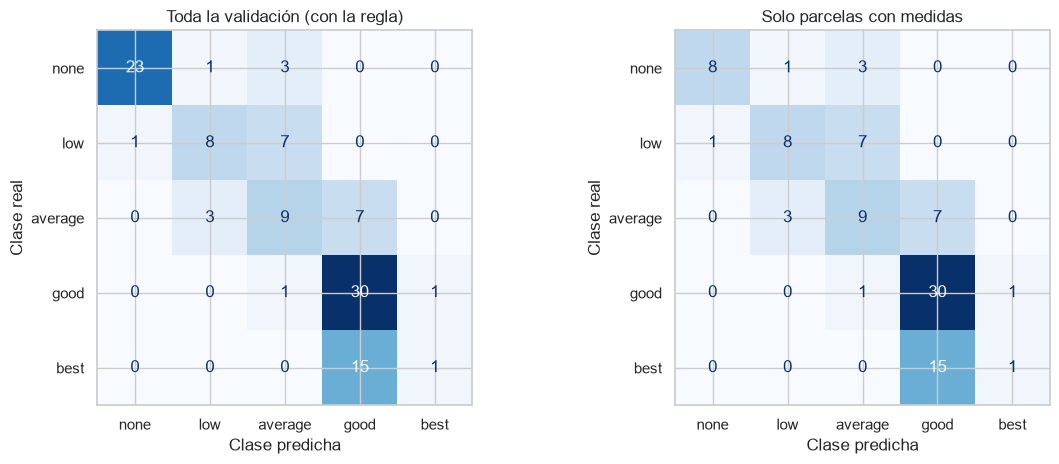

In [84]:
mostrar_evaluacion(ev)

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** saca la nota del examen (validación): aciertos totales (accuracy) y, por clase, cuántas veces acierta cuando dice "esta es X" (precision), cuántas X encuentra (recall) y su media (F1). Una tabla con las 110 parcelas y otra solo con las 95 medidas. Debajo dibuja las matrices de confusión: filas = lo que era de verdad, columnas = lo que dijo el modelo; la diagonal son los aciertos.

**Qué encuentra:** F1 macro 0,552 (completa) y 0,524 (solo medidas). `none` y `good` van bien; `best` casi nunca se encuentra (recall 0,06): de las 16 parcelas `best`, 15 se marcan como `good`, y `average` y `low` se mezclan con sus vecinas.

**En cristiano:** aprueba en lo corriente, pero cuando hay que reconocer a las parcelas "mejores" casi siempre se las pierde (como cuando dudas entre un notable y un sobresaliente).

## 5. Control de overfitting

El criterio del equipo es que la diferencia de **F1 macro** entre train y validación sea menor de **5 puntos**. Para que la regla fija del ADR-0001 no infle artificialmente la validación, el gap se mide **solo con las parcelas que tienen medidas**, que son las que realmente pasa por el modelo. Train ya no contiene parcelas sin medidas, así que es comparable.

In [85]:
medidas_val = ev["filas"]["solo con medidas"]
display(pd.DataFrame({
    "conjunto": [
        "train (modelo)",
        "validación completa (con regla)",
        "validación solo con medidas (modelo)",
    ],
    "F1 macro": [
        ev["f1_train"],
        ev["filas"]["toda la validación"]["F1 macro"],
        medidas_val["F1 macro"],
    ],
}).round(3))

print(f"Gap train - validación con medidas = {ev['gap']:.1f} puntos {nivel_gap(ev['gap'])}")
print(f"Cumple el criterio (< {GAP_MAXIMO} puntos):", "sí" if ev["cumple_gap"] else "no")

,conjunto,F1 macro
0,train (modelo),0.578
1,validación completa (con regla),0.552
2,validación solo con medidas (modelo),0.524


Gap train - validación con medidas = 5.4 puntos ❌ ligero sobreajuste
Cumple el criterio (< 5 puntos): no


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** compara la nota en las fichas de estudio (train) con la del examen (validación con medidas). El equipo exige que la diferencia sea menor de 5 puntos.

**Qué encuentra:** train 0,578 y validación 0,524: gap de 5,4 puntos, no cumple por 0,4. En CV era solo 2,1.

**En cristiano:** casi no ha hecho trampa, pero el margen se pasa por un pelo; el examen es pequeño (95 parcelas) y unas pocas respuestas lo mueven.

### Frente al baseline

Se pone el KNN al lado del Dummy con la misma vara: validación cruzada, validación completa (con la regla en ambos) y validación solo con parcelas medidas.

In [86]:
toda_val = ev["filas"]["toda la validación"]
comparacion = pd.DataFrame({
    "comparación": [
        "CV (train, StratifiedKFold)",
        "validación completa (con regla)",
        "validación solo con medidas",
    ],
    "F1 Dummy": [DUMMY["cv"], DUMMY["toda la validación"], DUMMY["solo con medidas"]],
    "F1 KNN": [cv["f1"], toda_val["F1 macro"], medidas_val["F1 macro"]],
})
comparacion["supera baseline (puntos)"] = (comparacion["F1 KNN"] - comparacion["F1 Dummy"]) * 100
comparacion["nivel baseline"] = comparacion["supera baseline (puntos)"].map(nivel_baseline)
display(comparacion.round(3))

,comparación,F1 Dummy,F1 KNN,supera baseline (puntos),nivel baseline
0,"CV (train, StratifiedKFold)",0.097,0.533,43.651,✅ supera claramente
1,validación completa (con regla),0.244,0.552,30.842,✅ supera claramente
2,validación solo con medidas,0.101,0.524,42.327,✅ supera claramente


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** pone al KNN y al tonto en la misma tabla y cuenta cuántos puntos de F1 le saca el KNN.

**Qué encuentra:** el KNN le gana por unos 44 puntos en validación cruzada, 31 en toda la validación y 42 solo con parcelas medidas; en los tres casos supera claramente al baseline (más de 25 puntos).

**En cristiano:** el KNN no es genial (le cuesta con las parcelas `best`), pero sí aprende cosas de verdad: saca de 4 a 5 veces más nota que el que contesta siempre lo mismo.

## 6. Interpretación: importancia de variables y errores

KNN no da una importancia nativa de variables, así que se usa `permutation_importance` sobre la validación **con medidas**: se mide cuánto cae el F1 macro al desordenar cada columna. Después se revisan los errores más frecuentes.

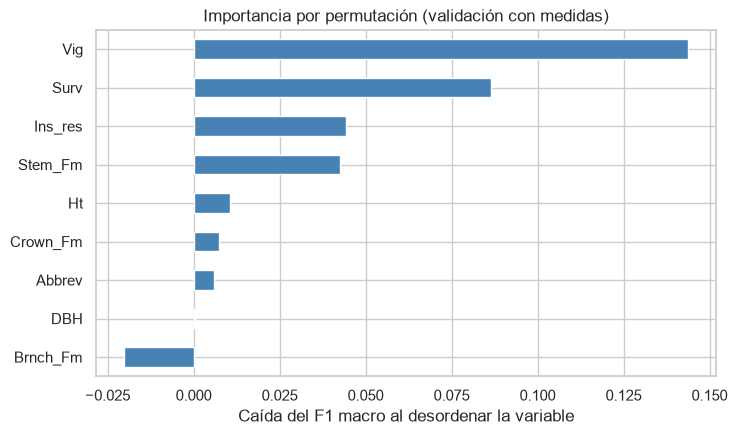

,importancia
Vig,0.144
Surv,0.087
Ins_res,0.044
Stem_Fm,0.043
Ht,0.010
Crown_Fm,0.007
Abbrev,0.006
DBH,0.000
Brnch_Fm,-0.020


In [87]:
importancia = importancia_permutacion(modelo, X_val, y_val)
display(importancia.sort_values(ascending=False).round(3).to_frame("importancia"))

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** estropea una columna cada vez (la baraja) y mira cuánto empeora el modelo. Cuanto más empeora, más importante era.

**Qué encuentra:** `Vig` (0,14) y `Surv` (0,09) son las que más importan; el resto casi no cuenta (`Brnch_Fm` sale negativa: ruido).

**En cristiano:** para saber si el vigor del árbol importa, se lo tapamos al modelo y vemos que se pierde mucho. Con otras columnas ni se nota.

In [88]:
pred_val = ev["pred"]
analisis = val.assign(predicha=pred_val)
analisis["error"] = analisis["Utility"] != analisis["predicha"]
errores = analisis[analisis["error"]]

display(errores_frecuentes(y_val, pred_val))

tasa_por_clase = analisis.groupby("Utility", observed=True).agg(
    n=("error", "size"), errores=("error", "sum")
)
tasa_por_clase["tasa de error"] = (tasa_por_clase["errores"] / tasa_por_clase["n"]).round(3)
display(tasa_por_clase.reindex(CLASES))

display(
    errores[["Abbrev", "Sp", "Vig", "Surv", "Ht", "DBH", "Utility", "predicha"]]
    .sort_values(["Utility", "predicha"])
    .head(20)
)

Errores: 39 de 110. Entre clases vecinas: 36; a 2 o más clases de distancia: 3.


,real,predicha,parcelas,distancia
0,best,good,15,1
1,low,average,7,1
2,average,good,7,1
3,average,low,3,1
4,none,average,3,2
5,none,low,1,1
6,low,none,1,1
7,good,average,1,1
8,good,best,1,1


,n,errores,tasa de error
Utility,,,
none,27,4,0.148
low,16,8,0.500
average,19,10,0.526
good,32,2,0.062
best,16,15,0.938


,Abbrev,Sp,Vig,Surv,Ht,DBH,Utility,predicha
23,Paw,nd,3.0,20.0,13.55,20.11,average,good
39,Puk,nd,3.0,100.0,7.84,16.30,average,good
50,WSh,re,3.8,25.0,8.84,22.34,average,good
65,WSp,ob,3.5,63.0,10.53,18.88,average,good
90,Lon,ov,3.0,100.0,5.57,14.53,average,good
108,WSp,fa,3.0,25.0,14.60,41.51,average,good
109,K83,fa,3.0,13.0,13.29,16.25,average,good
3,K81,si,3.0,25.0,4.27,3.56,average,low
30,K81a,ov,2.5,45.0,5.65,7.89,average,low
53,K81,br,3.0,88.0,4.11,4.62,average,low


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** lista los fallos: qué clase real se confundió con cuál, cuánto falla cada clase y ejemplos concretos.

**Qué encuentra:** 39 errores de 110 (35,5 %). El más repetido es `best` → `good` (15 veces); `best` falla el 94 % y `good` solo el 6 %.

**En cristiano:** el modelo se hace el "seguro" y dice `good` cuando duda, que es la respuesta más común; por eso acierta mucho `good` y pierde `best`.

### Observaciones de los errores

- La clase `best` casi no se acierta: 15 de 16 parcelas fallan (recall 0,06) y las 15 se predicen como `good`. Con k = 41 el voto de los vecinos lo ganan las clases mayoritarias del entorno (`good` es la más numerosa) y `best`, que es contigua y tiene pocas parcelas, queda siempre en minoría.
- Le siguen `average` (10 de 19) y `low` (8 de 16), que se confunden con sus clases vecinas (`good`/`low` y `average`). Todos los errores son saltos de una clase salvo unos pocos `none` ↔ `average`/`low`.
- `none` solo falla 4 veces porque la regla del ADR-0001 resuelve las 15 parcelas sin medidas; sobre las parcelas medidas su recall baja a 0,67.
- `Vig` y `Surv` son las únicas variables con importancia clara (0,14 y 0,09 de caída del F1). El resto está dentro del ruido (`Brnch_Fm` incluso sale negativa), lo que encaja con que KNN sufre cuando hay variables que no aportan: todas pesan igual en la distancia.

## 7. Guardar el pipeline y comprobar que se puede cargar

Se guarda el pipeline completo (preprocesado + KNN) con `joblib`, tal como pide el contrato de modelos. Después se carga desde disco y se predice sobre `data/val.csv` leído de nuevo, para comprobar que el artefacto es autónomo.

In [89]:
_ = guardar_modelo(modelo, "05_knn", X_val)

Guardado: models/05_knn.joblib (88.7 KB). ¿Al recargarlo predice igual? ✅


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** guarda el modelo entrenado (con su preprocesado) en el fichero `models/05_knn.joblib`.

**Qué encuentra:** un archivo de unos 89 KB.

**En cristiano:** metemos el cerebro ya aprendido en una cajita para usarlo otro día sin tener que volver a estudiar.

In [90]:
import joblib

_, val_fresco = cargar_datos()
modelo_cargado = joblib.load("models/05_knn.joblib")
pred_fresco = predecir_con_regla(modelo_cargado, val_fresco[VARIABLES])

print(f"Predicciones sobre data/val.csv: {len(pred_fresco)} filas")
display(pred_fresco.head().to_frame("predicha"))

Predicciones sobre data/val.csv: 110 filas


,predicha
0,none
1,good
2,good
3,low
4,good


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** abre la cajita en limpio, relee `data/val.csv` y comprueba que predice igual.

**Qué encuentra:** 110 predicciones y el mismo F1 macro de antes (0,552).

**En cristiano:** abrimos la caja y vemos que el cerebro sigue funcionando igual: está listo para la app.

### Requisitos y resumen común

`conclusion_modelo` comprueba los requisitos comunes del equipo, muestra el resumen y escribe `resultados/05_knn.json`, que lee `06_conclusiones`.

In [91]:
_ = conclusion_modelo("05_knn", cv, ev, DUMMY, PARAMETROS)

,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,5.4 puntos,❌
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+42 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.533 / 0.492,✅
R6,Pipeline guardado,Acuerdos,models/05_knn.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.533,0.552,0.524
gap (puntos),2.125,NaN,5.351
supera Dummy (puntos),43.651,30.842,42.327


Resultados guardados en resultados/05_knn.json


## 8. Conclusión

- **Modelo:** KNN con `k = 41`, voto uniforme y distancia Manhattan (`p = 1`), con imputación, estandarización y one-hot de `Abbrev`. Los hiperparámetros se eligen solo con train: entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro. No se toca el test.
- **Rendimiento:** F1 macro **0,552** en la validación completa y **0,524** solo con parcelas medidas (accuracy 0,645 y 0,589). Frente al baseline (`DummyClassifier`, que siempre responde `good`) supera claramente en los tres casos: +44 puntos en validación cruzada (0,533 frente a 0,097), +31 en toda la validación (0,552 frente a 0,244, ambos con la regla) y +42 con parcelas medidas (0,524 frente a 0,101). La comparación con los demás modelos se hace en `06_conclusiones`.
- **Overfitting:** el gap train − validación con medidas es **5,4 puntos**, así que **no cumple** el criterio de 5 puntos por 0,4. En validación cruzada el gap es de 2,1 puntos (train 0,555 frente a 0,533), por lo que el exceso se atribuye al ruido de una validación de solo 95 parcelas medidas (la desviación entre folds es de 4,6 puntos) y no a una memorización. No se ha retocado el modelo mirando la validación para forzar el cumplimiento: ajustarlo hasta bajar de 5 puntos sería ajustar a la validación, no mejorar el modelo. El resultado es coherente con cómo funciona KNN: guarda los datos de entrenamiento y no tiene regularización, así que en un dataset pequeño y ruidoso como este tiende a rendir algo mejor en train que en datos nuevos. Se acepta y se documenta como un hallazgo: KNN es el modelo menos fiable de los candidatos para este dataset, y el criterio de menos de 5 puntos se exige al modelo ganador de `06_conclusiones`, no a cada candidato. Con `weights="distance"` el gap sería de unos 43 puntos, y por eso se descarta.
- **Interpretación:** la señal viene de `Vig` y `Surv`; las demás variables no aportan de forma apreciable. Los errores se concentran en `best`, que se predice como `good` en 15 de 16 casos.
- **Comprobación por sitio:** el F1 macro con `StratifiedGroupKFold` (0,492 ± 0,114) es menor que con `StratifiedKFold` (0,533 ± 0,046), coherente con el ADR-0002: ver parcelas del mismo sitio ayuda y las métricas comunes están algo infladas; además la variabilidad entre folds es alta (de 0,33 a 0,66).
- **Límites:** un único reparto de validación, `best` con solo 16 parcelas y una rejilla corta de hiperparámetros. El test se evaluará una sola vez en `06_conclusiones`.

# Conclusiones: comparación de modelos, ganador y evaluación en test

**Proyecto:** clasificación multiclase de la *utilidad para la conservación del suelo* de parcelas de eucalipto (dataset Eucalyptus).
**Historia:** #42 (subtareas #64 y #65) · **Notebook:** `06_conclusiones.ipynb` · **Responsable:** todo el equipo

Hasta aquí cada integrante entrenó un algoritmo en su notebook (`02` a `05`). Todos usaron los mismos datos, las mismas validaciones y la misma evaluación de `comun.py`. Cada uno dejó dos ficheros:

- `models/<notebook>.joblib`: el pipeline completo (preprocesado + modelo);
- `resultados/<notebook>.json`: sus cifras en validación.

En este notebook:

1. **Comparamos** los cuatro modelos y el Dummy con esas cifras, sin reentrenar nada.
2. **Elegimos el ganador** con la regla del equipo (`docs/acuerdos.md`): el de **mayor F1 macro en toda la validación** entre los que tienen un **gap menor de 5 puntos**.
3. **Evaluamos el ganador en test**, una sola vez. Es la nota final: con ella no se cambia de modelo.
4. Analizamos sus errores, si rinde igual en todos los sitios y en qué variables se apoya.
5. Comprobamos los requisitos del Nivel Esencial y sacamos las conclusiones para negocio.

Cada paso tiene **Qué hacemos**, **Por qué** y **Cómo leer el resultado**, como en los notebooks de los modelos. Los números de los apartados «Qué vemos» corresponden a la última ejecución.

## Paso 1: cargar los resultados de los cuatro modelos

**Qué hacemos:** `cargar_resultados()` de `comun.py` lee todos los `resultados/*.json` y los devuelve en una tabla. También leemos los JSON completos: traen el detalle por clase y la accuracy.

**Por qué:** comparamos lo que cada notebook ya midió en validación. Reentrenar aquí podría dar cifras distintas y nadie sabría cuáles valen.

**Cómo leer el resultado:** una fila por modelo. `cargar_resultados()` ya las ordena con la regla del ganador: primero los que cumplen el gap y, entre ellos, de mayor a menor F1 en toda la validación.

In [92]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Librería común del equipo: mismas reglas para comparar y evaluar
from comun import (
    CLASES,
    DATOS,
    GAP_MAXIMO,
    MODELOS,
    RESULTADOS,
    baseline_dummy,
    cargar_datos,
    cargar_resultados,
    dibujar_matriz,
    errores_frecuentes,
    importancia_permutacion,
    nivel_gap,
    por_clase,
    predecir_con_regla,
    separar_xy,
    sin_medidas,
)

NOMBRES = {
    "02_regresion_logistica": "Regresión logística",
    "03_arbol_decision": "Árbol de decisión",
    "04_svm": "SVM",
    "05_knn": "KNN",
}


def metricas(y, pred):
    """F1 macro y accuracy de unas predicciones (test y comparaciones)."""
    return {
        "F1 macro": f1_score(y, pred, average="macro"),
        "accuracy": accuracy_score(y, pred),
        "accuracy balanceada": balanced_accuracy_score(y, pred),
    }


resultados = cargar_resultados()  # ya ordenados con la regla del ganador
detalle = {
    ruta.stem: json.loads(ruta.read_text(encoding="utf-8"))
    for ruta in sorted(RESULTADOS.glob("*.json"))
}
print(f"Modelos con resultados: {len(resultados)}")
resultados.round(3)

Modelos con resultados: 4


,f1_cv,desv_cv,f1_cv_sitio,f1_train,f1_val,f1_val_medidas,gap,cumple_gap
modelo,,,,,,,,
04_svm,0.582,0.085,0.507,0.631,0.636,0.601,3.024,True
03_arbol_decision,0.565,0.025,0.519,0.557,0.562,0.520,3.611,True
05_knn,0.533,0.046,0.492,0.578,0.552,0.524,5.351,False
02_regresion_logistica,0.434,0.021,0.397,0.494,0.468,0.429,6.523,False


## Paso 2: el Dummy, la referencia común

**Qué hacemos:** volvemos a calcular el Dummy con `baseline_dummy()`. Es un modelo que responde siempre la clase más frecuente (`good`) y `none` a las parcelas sin medidas. Usa `data/train.csv` y `data/val.csv`, que lee `cargar_datos()`.

**Por qué:** un modelo solo sirve si supera claramente a esta respuesta fija. El cálculo es el mismo en todos los notebooks, así que sale lo mismo que en ellos.

**Cómo leer el resultado:** el F1 macro del Dummy en CV, en toda la validación y solo en las parcelas con medidas.

In [93]:
train, val = (
    cargar_datos()
)  # train y validación (el test se lee más abajo, una sola vez)
X_train, y_train = separar_xy(train)
X_val, y_val = separar_xy(val)

f1_dummy = baseline_dummy(X_train, y_train, X_val, y_val)

El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


## Paso 3: tabla comparativa (subtarea #64)

**Qué hacemos:** juntamos en una tabla, para cada modelo, todo lo que pide la historia #42:

| Columna | Qué es |
|---|---|
| F1 val (toda) | F1 macro en las 110 parcelas de validación, con la regla `none`. **Es la métrica que elige al ganador.** |
| F1 val (con medidas) | F1 macro solo en las parcelas que pasan por el modelo. |
| accuracy val (toda / con medidas) | Proporción de aciertos. Se da porque la pide el enunciado, pero no decide: con clases desbalanceadas engaña (guía, error 2). |
| F1 train | F1 macro en train. |
| gap | (F1 train − F1 val con medidas) × 100, con signo. Tiene que ser **menor de 5 puntos**. |
| F1 CV ± desv. | Media y desviación de los 5 folds de `StratifiedKFold` en train. |
| F1 por sitio ± desv. | Igual, pero sin repetir sitio entre folds (`StratifiedGroupKFold`, ADR-0002). Mide cuánto aguanta el modelo en sitios que no vio. |
| supera Dummy | Puntos de F1 (toda la validación) por encima del Dummy. |

**Por qué:** una sola tabla con las mismas columnas permite comparar modelos que se hicieron en notebooks distintos.

**Cómo leer el resultado:** primero miramos el **gap**, porque un modelo que no cumple queda fuera. Entre los que cumplen, gana el de mayor **F1 val (toda)**.

In [94]:
filas = {}
for nombre, r in resultados.iterrows():
    m = detalle[nombre]["metricas"]
    filas[NOMBRES.get(nombre, nombre)] = {
        "F1 val (toda)": r["f1_val"],
        "F1 val (con medidas)": r["f1_val_medidas"],
        "accuracy val (toda)": m["toda la validación"]["accuracy"],
        "accuracy val (con medidas)": m["solo con medidas"]["accuracy"],
        "F1 train": r["f1_train"],
        "gap (puntos)": r["gap"],
        "nivel del gap": nivel_gap(r["gap"]),
        "F1 CV": r["f1_cv"],
        "desv. CV": r["desv_cv"],
        "F1 por sitio": r["f1_cv_sitio"],
        "desv. sitio": detalle[nombre]["desv_cv_sitio"],
        "supera Dummy (puntos)": 100 * (r["f1_val"] - f1_dummy["toda la validación"]),
    }
filas["Dummy (referencia)"] = {
    "F1 val (toda)": f1_dummy["toda la validación"],
    "F1 val (con medidas)": f1_dummy["solo con medidas"],
    "F1 CV": f1_dummy["cv"],
}
tabla_modelos = pd.DataFrame.from_dict(filas, orient="index")
decimales = {"gap (puntos)": 1, "supera Dummy (puntos)": 1}
tabla_modelos.round({c: decimales.get(c, 3) for c in tabla_modelos.columns}).astype(
    object
).fillna("—")

,F1 val (toda),F1 val (con medidas),accuracy val (toda),accuracy val (con medidas),F1 train,gap (puntos),nivel del gap,F1 CV,desv. CV,F1 por sitio,desv. sitio,supera Dummy (puntos)
SVM,0.636,0.601,0.709,0.663,0.631,3.0,✅ correcto,0.582,0.085,0.507,0.108,39.2
Árbol de decisión,0.562,0.52,0.636,0.579,0.557,3.6,✅ correcto,0.565,0.025,0.519,0.11,31.8
KNN,0.552,0.524,0.645,0.589,0.578,5.4,❌ ligero sobreajuste,0.533,0.046,0.492,0.114,30.8
Regresión logística,0.468,0.429,0.509,0.432,0.494,6.5,❌ ligero sobreajuste,0.434,0.021,0.397,0.03,22.4
Dummy (referencia),0.244,0.101,—,—,—,—,—,0.097,—,—,—,—


**Qué vemos:**

- **Todos superan al Dummy con claridad**, entre 22 y 39 puntos de F1. Los cuatro algoritmos aprenden algo útil.
- **Solo dos cumplen el gap**: el SVM (3.0) y el árbol (3.6). El KNN (5.4) se pasa por poco y la regresión logística (6.5) algo más.
- **El SVM tiene el mejor F1 en validación**: 0.636 en toda la validación y 0.601 con medidas. Le sigue el árbol, con 0.562 y 0.520.
- La **accuracy** ordena los modelos casi igual (solo se intercambian el KNN y el árbol), pero sale siempre más alta que el F1 macro. Premia acertar `good`, que es la clase más frecuente.
- **Por sitio** todos bajan: entre 0.40 y 0.52, con una desviación de hasta 0.11. Con un sitio que el modelo no ha visto, el resultado es peor y más variable. Es el principal límite del proyecto (lo retomamos en las conclusiones).

## Paso 4: la comparación en gráficos

**Qué hacemos:** dibujamos el F1 en validación de cada modelo junto a la línea del Dummy, y el gap junto a la línea de 5 puntos.

**Por qué:** en un gráfico se ve de un vistazo qué modelos superan la referencia y cuáles se pasan del límite de sobreajuste.

**Cómo leer el resultado:**
- izquierda: cuanto más alta la barra, mejor, y tiene que quedar muy por encima de la línea gris (Dummy);
- derecha: las barras verdes cumplen el gap y las rojas cruzan la línea de 5 puntos.

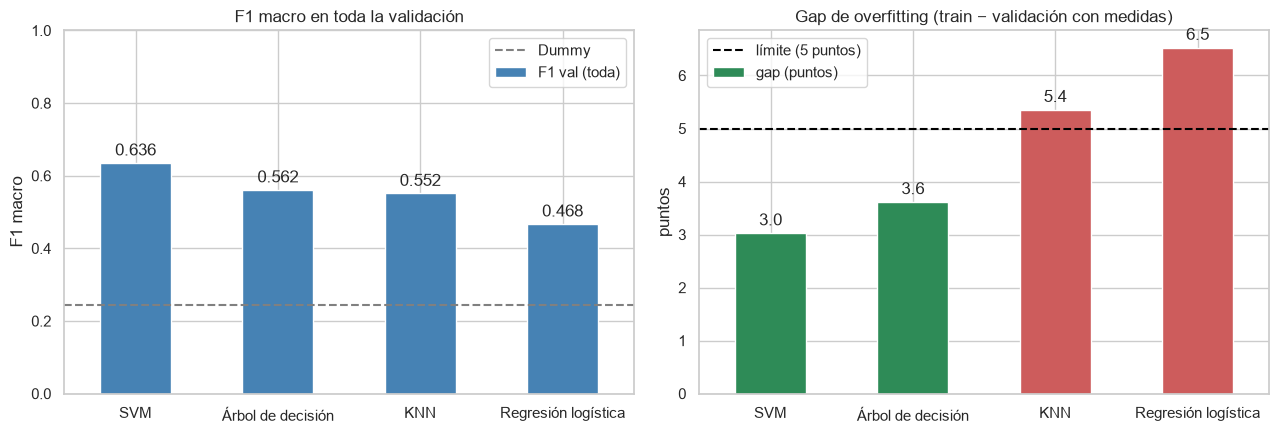

In [95]:
modelos = tabla_modelos.drop(index="Dummy (referencia)")
colores = [
    "seagreen" if g < GAP_MAXIMO else "indianred" for g in modelos["gap (puntos)"]
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
modelos["F1 val (toda)"].plot.bar(ax=ax1, color="steelblue", rot=0)
ax1.axhline(f1_dummy["toda la validación"], color="grey", ls="--", label="Dummy")
ax1.set(title="F1 macro en toda la validación", ylabel="F1 macro", ylim=(0, 1))
ax1.legend()
for i, v in enumerate(modelos["F1 val (toda)"]):
    ax1.text(i, v + 0.02, f"{v:.3f}", ha="center")

modelos["gap (puntos)"].plot.bar(ax=ax2, color=colores, rot=0)
ax2.axhline(GAP_MAXIMO, color="black", ls="--", label=f"límite ({GAP_MAXIMO} puntos)")
ax2.set(title="Gap de overfitting (train − validación con medidas)", ylabel="puntos")
ax2.legend()
for i, v in enumerate(modelos["gap (puntos)"]):
    ax2.text(i, v + 0.15, f"{v:.1f}", ha="center")
plt.tight_layout()
plt.show()

**Qué vemos:** el SVM es el más alto a la izquierda y tiene la barra verde más baja a la derecha. El árbol también cumple. El KNN y la regresión logística quedan en rojo, por encima de la línea de 5 puntos.

### 4.2 ¿Qué clases cuestan a todos?

**Qué hacemos:** un mapa de calor con el F1 de cada clase (columnas) para cada modelo (filas), en toda la validación.

**Por qué:** el F1 macro es una media de las cinco clases y esconde cuáles fallan. Si una clase sale mal en todos los modelos, el problema está en los datos y no en el algoritmo.

**Cómo leer el resultado:** azul oscuro es un F1 alto y claro es un F1 bajo. Hay que leer por columnas.

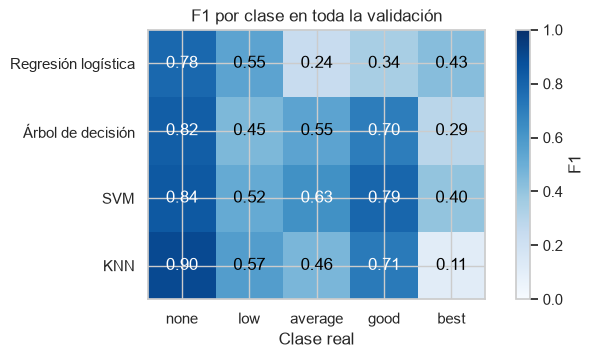

In [96]:
f1_clase = pd.DataFrame(
    {
        NOMBRES.get(n, n): {
            c: d["por_clase"]["toda la validación"][c]["f1"] for c in CLASES
        }
        for n, d in detalle.items()
    }
).T

fig, ax = plt.subplots(figsize=(8, 3.5))
imagen = ax.imshow(f1_clase, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASES)), CLASES)
ax.set_yticks(range(len(f1_clase)), f1_clase.index)
for i in range(f1_clase.shape[0]):
    for j in range(f1_clase.shape[1]):
        valor = f1_clase.iloc[i, j]
        ax.text(
            j,
            i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            color="white" if valor > 0.6 else "black",
        )
ax.set(title="F1 por clase en toda la validación", xlabel="Clase real")
fig.colorbar(imagen, ax=ax, label="F1")
plt.show()

**Qué vemos:**

- **`none` es la clase más fácil** para todos (F1 de 0.78 a 0.90). La regla de las parcelas sin medidas ayuda mucho: esas parcelas siempre son `none`.
- **`best` es la más difícil** para todos (de 0.11 a 0.43). Los modelos la confunden con `good`, su vecina. Con 16 parcelas en validación y medidas muy parecidas a las de `good`, es difícil separarlas.
- `low` se queda en torno a 0.5 en todos los modelos.
- **El SVM es el mejor en `average` (0.63) y `good` (0.79)**, y el segundo en `best` (0.40, tras el 0.43 de la regresión logística). Por eso tiene el F1 macro más alto.

## Paso 5: elegir el modelo ganador

**Qué hacemos:** aplicamos la regla del equipo (`docs/acuerdos.md`): **entre los modelos con gap < 5, el de mayor F1 macro en toda la validación**. Como `cargar_resultados()` ya los ordena así, el ganador es el primero que cumple el gap. La celda lo comprueba otra vez para que nadie tenga que fiarse del orden.

**Por qué:** el ganador sale de una regla escrita antes de ver los resultados y de la validación, **nunca del test**. Elegir mirando el test es el error 4 de la guía: el test dejaría de ser una nota imparcial.

**Cómo leer el resultado:** el nombre del ganador y qué modelos quedan fuera y por qué.

In [97]:
cumplen = resultados[resultados["cumple_gap"]]
if cumplen.empty:
    raise ValueError(
        "Ningún modelo cumple el gap: no hay ganador según la regla del equipo."
    )

ganador = cumplen.index[0]
assert ganador == cumplen["f1_val"].idxmax(), (
    "El orden de cargar_resultados() no cuadra"
)

print(f"🏆 Modelo ganador: {NOMBRES.get(ganador, ganador)} ({ganador})")
print(f"   F1 macro en toda la validación: {resultados.loc[ganador, 'f1_val']:.3f}")
gap_ganador = resultados.loc[ganador, "gap"]
print(f"   Gap: {gap_ganador:.1f} puntos → {nivel_gap(gap_ganador)}")
print(f"   Hiperparámetros: {detalle[ganador]['hiperparametros']}")
print()
for nombre, r in resultados.drop(index=ganador).iterrows():
    motivo = (
        f"cumple el gap, pero su F1 es {r['f1_val']:.3f}"
        if r["cumple_gap"]
        else f"no cumple el gap ({r['gap']:.1f} puntos ≥ {GAP_MAXIMO})"
    )
    print(f"   {NOMBRES.get(nombre, nombre)}: {motivo}")

🏆 Modelo ganador: SVM (04_svm)
   F1 macro en toda la validación: 0.636
   Gap: 3.0 puntos → ✅ correcto
   Hiperparámetros: {'svm__C': 0.045}

   Árbol de decisión: cumple el gap, pero su F1 es 0.562
   KNN: no cumple el gap (5.4 puntos ≥ 5)
   Regresión logística: no cumple el gap (6.5 puntos ≥ 5)


**Por qué gana el SVM:**

1. **Cumple el gap**: 3.0 puntos (F1 train 0.631 y F1 en validación con medidas 0.601). Generaliza a datos que no vio en el entrenamiento.
2. **Es el de mayor F1 en toda la validación** entre los que cumplen: 0.636, frente al 0.562 del árbol. Son 7.4 puntos más, y supera al Dummy en 39 puntos.
3. **Es un modelo sencillo**: un SVM lineal con un solo hiperparámetro (`C = 0.045`, mucha regularización). Ese `C` tan bajo es lo que lo protege del sobreajuste.

**Por qué quedan fuera los demás:**

- **Árbol de decisión:** cumple el gap, pero tiene 7.4 puntos menos de F1 en validación.
- **KNN:** su F1 (0.552) es bueno, pero su gap es de 5.4 puntos. En su notebook se aceptó como un sobreajuste pequeño, pero la regla del equipo es estricta (< 5), así que no puede ganar.
- **Regresión logística:** tiene el F1 más bajo (0.468) y un gap de 6.5 puntos.

**Precauciones con el ganador (las dejamos escritas antes de ver el test):**

- En la CV su F1 varía mucho entre folds (0.582 ± 0.085). El árbol es mucho más estable (0.565 ± 0.025). En CV la diferencia entre los dos (1.7 puntos) es menor que esa variación, así que **no es seguro que el SVM sea mejor en cualquier muestra**. La regla decide por la validación, y ahí la ventaja sí es clara.
- **Por sitio** los dos quedan igual (SVM 0.507 y árbol 0.519, ambos con ± 0.11). Ninguno resuelve mejor los sitios nuevos.

## Paso 6: evaluación final en test (subtarea #65)

**Qué hacemos:** en **una sola celda**:

1. leemos el CSV de test, que ningún notebook había abierto antes;
2. cargamos el pipeline del ganador desde `models/`;
3. predecimos con la misma regla que la app: `predecir_con_regla()` responde `none` a las parcelas sin medidas sin preguntar al modelo (ADR-0001) y pasa el resto al pipeline;
4. calculamos las métricas en **todo el test** y **solo en las parcelas con medidas**, las métricas por clase y las dos matrices de confusión.

Como referencia, calculamos también el Dummy en test. `baseline_dummy()` llama «validación» a lo que recibe como segundo conjunto: **en esta celda, ese conjunto es el test**.

**Por qué:** el test simula los datos del mundo real. Se usa **una sola vez** y **solo con el ganador**. Si evaluáramos los cuatro modelos y nos quedáramos con el mejor en test, el test estaría eligiendo modelo y su nota dejaría de ser imparcial. El resto del notebook reutiliza las predicciones de esta celda y no vuelve a leer el CSV.

**Cómo leer el resultado:**
1. la tabla de métricas globales (F1 macro, accuracy, accuracy balanceada) y cuántos puntos supera al Dummy;
2. precision, recall y F1 de cada clase;
3. las matrices de confusión: la diagonal son los aciertos y lo que queda fuera son las confusiones (fila = clase real, columna = clase predicha).

Test: 111 parcelas; 8 sin medidas → «none» por la regla

Referencia: Dummy (aquí «validación» = test)
El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.186,0.360
solo con medidas,0.095,0.311


1. MÉTRICAS EN TEST (modelo ganador)


,F1 macro,accuracy,accuracy balanceada,supera Dummy (puntos)
todo el test,0.655,0.685,0.647,46.9
solo con medidas,0.643,0.660,0.634,54.8


2. MÉTRICAS POR CLASE EN TEST


todo el test                      solo con medidas                     
           precision recall    f1 soporte        precision recall    f1 soporte
none            0.85   0.85  0.85    27.0             0.79   0.79  0.79    19.0
low             0.54   0.44  0.48    16.0             0.54   0.44  0.48    16.0
average         0.63   0.60  0.62    20.0             0.63   0.60  0.62    20.0
good            0.64   0.78  0.70    32.0             0.64   0.78  0.70    32.0
best            0.69   0.56  0.62    16.0             0.69   0.56  0.62    16.0

3. MATRICES DE CONFUSIÓN EN TEST


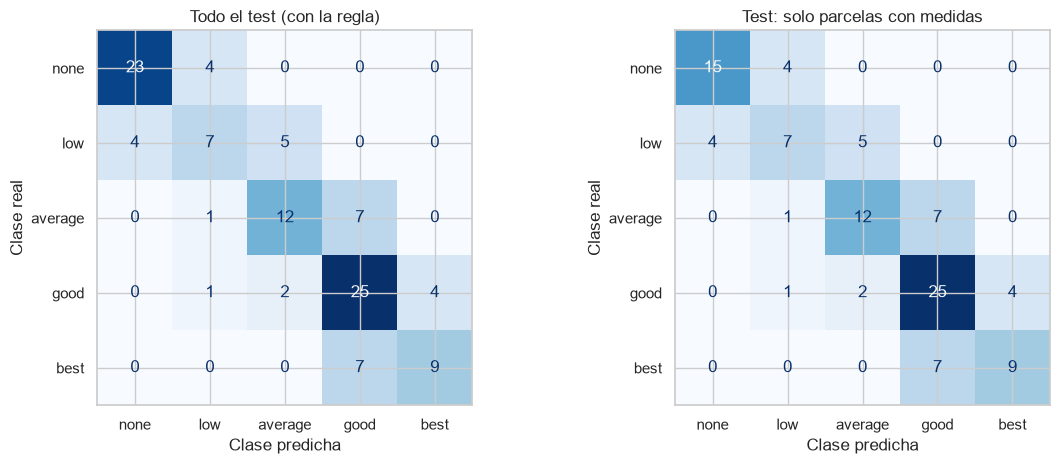

In [98]:
# ÚNICA lectura del test: una sola vez y solo con el modelo ganador
test = pd.read_csv(DATOS / "test.csv", encoding="utf-8")
X_test, y_test = separar_xy(test)
modelo = joblib.load(MODELOS / f"{ganador}.joblib")
variables = list(modelo.feature_names_in_)  # las columnas que usa el pipeline ganador

pred_test = predecir_con_regla(modelo, X_test[variables])
medidas_test = ~sin_medidas(X_test)
n_sin = (~medidas_test).sum()
print(f"Test: {len(y_test)} parcelas; {n_sin} sin medidas → «none» por la regla")

print("\nReferencia: Dummy (aquí «validación» = test)")
f1_dummy_test = baseline_dummy(X_train, y_train, X_test, y_test)

print("1. MÉTRICAS EN TEST (modelo ganador)")
metricas_test = pd.DataFrame(
    {
        "todo el test": metricas(y_test, pred_test),
        "solo con medidas": metricas(y_test[medidas_test], pred_test[medidas_test]),
    }
).T
metricas_test["supera Dummy (puntos)"] = 100 * (
    metricas_test["F1 macro"]
    - pd.Series(
        {
            "todo el test": f1_dummy_test["toda la validación"],
            "solo con medidas": f1_dummy_test["solo con medidas"],
        }
    )
)
display(metricas_test.round({"supera Dummy (puntos)": 1}).round(3))

print("2. MÉTRICAS POR CLASE EN TEST")
display(
    pd.concat(
        {
            "todo el test": por_clase(y_test, pred_test),
            "solo con medidas": por_clase(
                y_test[medidas_test], pred_test[medidas_test]
            ),
        },
        axis=1,
    ).round(2)
)

print("3. MATRICES DE CONFUSIÓN EN TEST")
_, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
dibujar_matriz(y_test, pred_test, "Todo el test (con la regla)", ejes[0])
dibujar_matriz(
    y_test[medidas_test],
    pred_test[medidas_test],
    "Test: solo parcelas con medidas",
    ejes[1],
)
plt.tight_layout()
plt.show()

**Qué vemos:**

- **F1 macro en test: 0.655** en todo el test y 0.643 solo con medidas, frente a un Dummy de 0.186 y 0.095. El modelo **supera al Dummy en 47 puntos** (55 solo con medidas). La accuracy es de 0.685 (0.660 con medidas).
- **Por clase:**
  - `none` es la mejor (F1 0.85). Las 8 parcelas sin medidas las acierta la regla.
  - `good` (0.70), `average` (0.62) y `best` (0.62) quedan en un nivel aceptable.
  - `low` es la más floja (0.48): recall de 0.44, se escapa más de la mitad de las parcelas `low`.
- **En las matrices**, casi todo lo que sale de la diagonal cae en la casilla de al lado: el modelo confunde clases vecinas (`best` con `good`, `average` con `good`, `low` con `average` o con `none`). Lo medimos en el paso 9.
- **Diferencia con validación:** en test `best` sube a un F1 de 0.62 (0.40 en validación). Con 16 parcelas, acertar 3 o 4 más cambia mucho la cifra: es variación de la muestra, no una mejora del modelo.

## Paso 7: ¿se parece el test a la validación?

**Qué hacemos:** ponemos juntas las métricas del ganador en **train**, **validación** y **test**, y calculamos el gap también con el test:

> gap en test = (F1 train − F1 test con medidas) × 100

**Por qué:** es la pregunta que hace la guía en el paso 8. Si el test cae mucho respecto a la validación, hubo **fuga de datos** o **sobreajuste a la validación** (por haber probado muchas cosas mirándola). Además, el gap en test comprueba el requisito de **overfitting < 5 %** con datos que no se usaron para nada.

**Cómo leer el resultado:** las filas de validación y test deberían tener cifras parecidas, y el gap en test debería ser menor de 5.

In [99]:
pred_val = predecir_con_regla(modelo, X_val[variables])
medidas_val = ~sin_medidas(X_val)
f1_train = f1_score(y_train, modelo.predict(X_train[variables]), average="macro")

comparacion = pd.DataFrame(
    {
        "train": metricas(y_train, modelo.predict(X_train[variables])),
        "validación (toda)": metricas(y_val, pred_val),
        "validación (con medidas)": metricas(y_val[medidas_val], pred_val[medidas_val]),
        "test (todo)": metricas(y_test, pred_test),
        "test (con medidas)": metricas(y_test[medidas_test], pred_test[medidas_test]),
    }
).T
display(comparacion.round(3))

assert abs(f1_train - detalle[ganador]["f1_train"]) < 1e-9, (
    "El modelo no es el del JSON"
)
gap_val = detalle[ganador]["gap"]
gap_test = 100 * (f1_train - comparacion.loc["test (con medidas)", "F1 macro"])
print(f"Gap en validación: {gap_val:.1f} puntos → {nivel_gap(gap_val)}")
print(f"Gap en test:       {gap_test:.1f} puntos → {nivel_gap(gap_test)}")

,F1 macro,accuracy,accuracy balanceada
train,0.631,0.657,0.617
validación (toda),0.636,0.709,0.631
validación (con medidas),0.601,0.663,0.603
test (todo),0.655,0.685,0.647
test (con medidas),0.643,0.660,0.634


Gap en validación: 3.0 puntos → ✅ correcto
Gap en test:       -1.1 puntos → ✅ correcto


**Qué vemos:**

- El F1 en **test (0.655) es incluso algo más alto que en validación (0.636)**, y lo mismo pasa solo con medidas (0.643 frente a 0.601). **No hay caída**, así que no hay señales de fuga ni de sobreajuste a la validación.
- **Gap en test: −1.1 puntos** (✅). Test y train quedan casi iguales: el modelo cumple el **overfitting < 5 %** también con datos nunca vistos.
- La pequeña subida respecto a validación es ruido de muestra: con ~110 parcelas, unas pocas parcelas mueven el F1 varios puntos. Lo esperable en producción es un F1 macro de **entre 0.60 y 0.65**.

### Preguntas de la guía (paso 8)

| Pregunta | Respuesta |
|---|---|
| ¿La métrica coincide con lo definido en el paso 0? | Sí: F1 macro, definida en `00_general`. Trata igual las cinco clases, aunque `good` sea la más frecuente. |
| ¿El resultado en test es parecido al de validación? | Sí: 0.655 frente a 0.636. No hay fuga ni sobreajuste. |
| ¿Rinde igual en todos los subgrupos? | Lo miramos por sitio en el paso siguiente. |
| ¿ROC-AUC, PR-AUC y calibración? | No se pueden calcular: el ganador es un SVM lineal (`SVC`) entrenado sin `probability=True`, así que solo da la clase y no probabilidades. Para la app basta con la clase. Si negocio necesitara un nivel de confianza, habría que reentrenar con probabilidades calibradas, y eso ya sería un modelo nuevo. |
| ¿Cambiamos de modelo por lo que sale en test? | **No.** El test solo informa. Elegir mirándolo sería el error 4 de la guía. |

## Paso 8: ¿rinde igual en todos los sitios?

**Qué hacemos:** separamos el test por sitio (`Abbrev`) y calculamos, para cada uno, cuántas parcelas hay, la accuracy y el F1 macro.

**Por qué:** la guía pide comprobar si el modelo rinde igual en todos los **subgrupos**. Aquí el subgrupo natural es el sitio: el EDA mostró que la clase depende mucho de dónde se plantó (ADR-0002), y la validación por sitio ya daba cifras más bajas.

**Cómo leer el resultado:** **cuidado con el tamaño**. Hay sitios con 2 a 9 parcelas, y ahí un solo acierto mueve la accuracy más de 10 puntos. El F1 macro por sitio es todavía menos fiable, porque en cada sitio solo aparecen algunas de las clases. Hay que buscar sitios con muchas parcelas y muchos errores, no fijarse en los extremos.

In [100]:
por_sitio = (
    pd.DataFrame({"sitio": X_test["Abbrev"], "real": y_test, "predicha": pred_test})
    .groupby("sitio")
    .apply(
        lambda g: pd.Series(
            {
                "parcelas": len(g),
                "clases distintas": g["real"].nunique(),
                "errores": int((g["real"] != g["predicha"]).sum()),
                "accuracy": accuracy_score(g["real"], g["predicha"]),
                "F1 macro": f1_score(g["real"], g["predicha"], average="macro"),
            }
        ),
        include_groups=False,
    )
    .sort_values("parcelas", ascending=False)
)
por_sitio.astype({"parcelas": int, "clases distintas": int, "errores": int}).round(2)

,parcelas,clases distintas,errores,accuracy,F1 macro
sitio,,,,,
Puk,19,4,6,0.68,0.52
Paw,14,4,5,0.64,0.28
K82,9,4,4,0.56,0.42
Wai,9,4,2,0.78,0.66
Wak,9,4,4,0.56,0.37
Lon,8,3,3,0.62,0.37
Mor,8,1,0,1.00,1.00
WSp,8,3,3,0.62,0.58
K83,7,3,2,0.71,0.50


**Qué vemos:**

- **Mor y Cra: 100 % de aciertos.** Las 8 parcelas de Mor en test son parcelas sin medidas: las resuelve la regla `none`, no el modelo.
- **Los sitios grandes**, Puk (19 parcelas) y Paw (14), tienen una accuracy de 0.68 y 0.64, cerca de la media (0.68). Paw tiene un F1 macro bajo (0.28) porque mezcla varias clases vecinas que el modelo confunde.
- **K82, Wak y Lon** quedan por debajo (accuracy de 0.56 a 0.63). Nga (2 parcelas, 0 aciertos) no permite sacar conclusiones.
- **Conclusión:** el modelo **no rinde igual en todos los sitios**, como ya anunciaba la validación por sitio (0.507 ± 0.108). Para un sitio nuevo hay que esperar más error que la media. Lo recogemos en los límites.

## Paso 9: análisis de errores e interpretación del ganador

### 9.1 ¿Qué errores comete?

**Qué hacemos:** `errores_frecuentes()` cuenta las confusiones (real → predicha) en todo el test y calcula a cuántas clases de distancia está cada error en la escala `none` < `low` < `average` < `good` < `best`.

**Por qué:** el enunciado pide un **análisis de errores**. Las clases tienen orden, así que no es lo mismo confundir `best` con `good` (clases vecinas) que con `low` (dos clases de distancia, un error grave).

**Cómo leer el resultado:** la frase de arriba resume cuántos errores son entre vecinas y cuántos graves. La tabla muestra las confusiones más frecuentes.

In [101]:
errores_frecuentes(y_test, pred_test)

Errores: 35 de 111. Entre clases vecinas: 34; a 2 o más clases de distancia: 1.


,real,predicha,parcelas,distancia
0,average,good,7,1
1,best,good,7,1
2,low,average,5,1
3,low,none,4,1
4,good,best,4,1
5,none,low,4,1
6,good,average,2,1
7,good,low,1,2
8,average,low,1,1


**Qué vemos:**

- **35 errores en 111 parcelas, y 34 son entre clases vecinas.** Solo hay **1 error grave**: una parcela `good` que el modelo predijo `low`. Cuando se equivoca, casi siempre se queda a un paso de la clase real.
- Las dos confusiones más frecuentes acaban en `good`: **`average` → `good` (7)** y **`best` → `good` (7)**. `good` es la clase más frecuente y el modelo tiende a ir hacia ella cuando duda.
- `low` → `none` (4) y `none` → `low` (4): en la parte baja de la escala, las parcelas `low` y las `none` con medidas se parecen.

**¿Qué datos ayudarían a corregirlos?** Más parcelas de `best` y `low`, y medidas que distingan un buen lote de uno excelente (por ejemplo, crecimiento en varios años). Las seis medidas actuales son puntuaciones de 1 a 5 o porcentajes, que separan poco las clases altas.

### 9.2 ¿En qué variables se apoya?

**Qué hacemos:** `importancia_permutacion()` desordena cada variable en las parcelas con medidas del test y mide cuánto cae el F1 macro. Es el mismo método que usó el SVM en su notebook (8.1), allí con validación.

**Por qué:** el enunciado pide **feature importance**, y la guía pregunta si el modelo se apoya en variables con sentido. Si en test sale el mismo orden que en validación, la interpretación es estable.

**Cómo leer el resultado:** cuanto más larga es la barra, más se apoya el modelo en esa variable.

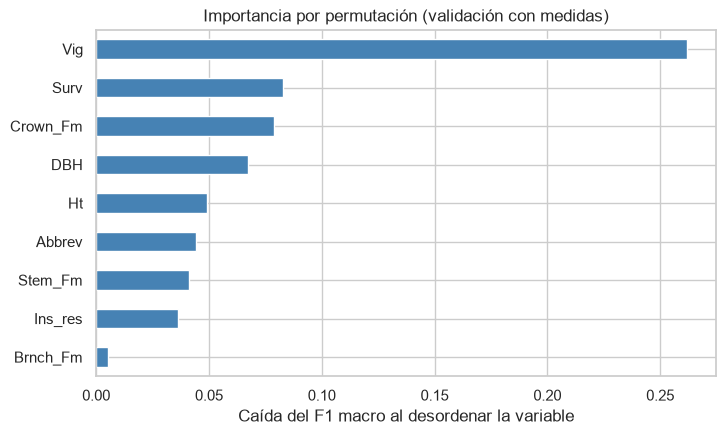

,importancia
Vig,0.262
Surv,0.083
Crown_Fm,0.079
DBH,0.068
Ht,0.049
Abbrev,0.044
Stem_Fm,0.041
Ins_res,0.036
Brnch_Fm,0.005


In [102]:
importancia = importancia_permutacion(modelo, X_test[variables], y_test)
display(importancia.sort_values(ascending=False).to_frame("importancia").round(3))

**Qué vemos:**

- **El vigor (`Vig`) es, con mucha diferencia, la variable más importante** (0.26), igual que en validación (0.265). Lo siguen la supervivencia (`Surv`), la forma de la copa (`Crown_Fm`), el diámetro (`DBH`) y la altura (`Ht`), todas entre 0.05 y 0.08.
- El **sitio** (`Abbrev`) pesa poco (0.04). El modelo decide sobre todo por cómo crecen los árboles, no por el lugar.
- El orden coincide en lo esencial con el de validación (`Vig` primero y `Surv` segundo). Respecto a validación, `Crown_Fm` sube y `Ht` baja. **Tiene sentido**: un lote vigoroso que sobrevive bien es el que más sirve para conservar el suelo, y eso cuadra con el EDA. El modelo no ha aprendido nada absurdo.

## Paso 10: requisitos del Nivel Esencial

**Qué hacemos:** repasamos los requisitos del enunciado (`docs/business/EXERCISE_SPECS.md`, Nivel Esencial) y decimos dónde se cumple cada uno.

**Por qué:** esta tabla sirve de base para el informe técnico (#46) y para las presentaciones (#47, #48).

| Requisito | Estado | Dónde |
|---|---|---|
| Modelo de clasificación multiclase funcional (mínimo 3 clases) | ✅ | 5 clases. Cuatro modelos entrenados (`02`–`05`); ganador: SVM (`models/04_svm.joblib`) |
| EDA con visualizaciones para clasificación (histogramas por clase, correlación…) | ✅ | `01_eda.ipynb` y `docs/informe-eda.md` |
| Overfitting < 5 % entre training y validation | ✅ | Gap del ganador: 3.0 puntos en validación y −1.1 en test (pasos 5 y 7) |
| Aplicación básica (Streamlit) | ⏳ | Pendiente (#43, #44, #45). Cargará `models/04_svm.joblib` |
| Informe: accuracy global | ✅ | Pasos 3 y 6 (0.685 en test) |
| Informe: precision, recall y F1 por clase | ✅ | Paso 6 (test) y notebooks `02`–`05` (validación) |
| Informe: matriz de confusión | ✅ | Paso 6, con y sin las parcelas sin medidas |
| Informe: feature importance | ✅ | Paso 9.2 y cada notebook de modelo |
| Informe: análisis de errores | ✅ | Paso 9.1 (errores entre vecinas y graves) y paso 8 (por sitio) |

## Conclusiones

### Para negocio

- El modelo elegido, un **SVM lineal**, **acierta la utilidad de 2 de cada 3 lotes** (accuracy de 0.685 en test). Su F1 macro (0.655) **multiplica por tres el del Dummy** (0.186). El Dummy representa responder siempre lo más habitual.
- **Cuando falla, casi siempre se queda a un paso**: 34 de 35 errores son entre clases vecinas. En la práctica, el modelo sirve para separar **lotes que no valen** (`none`/`low`) de **lotes que valen** (`good`/`best`) con bastante seguridad.
- **Su punto débil es distinguir `best` de `good`**, que es la confusión más frecuente junto con `average` → `good`. Para un programa de conservación, confundir `best` con `good` cuesta poco, porque los dos lotes son útiles. Lo que más preocuparía, recomendar un lote `none` o `low` como `good`/`best`, **no ha pasado ni una vez en test**.
- Las parcelas **sin medidas** se clasifican `none` con una regla fija. En validación y en test todas eran `none`, así que la regla no ha fallado nunca.

### Límites

- **Pocos datos:** 469 parcelas para entrenar y ~110 en validación y en test. Unas pocas parcelas mueven el F1 varios puntos. Por eso el F1 del SVM varía tanto entre folds de la CV (± 0.085).
- **Efecto del sitio:** con sitios que no ha visto, el modelo rinde peor (0.507 en la validación por sitio) y de forma desigual (paso 8). Para un sitio nuevo hay que esperar más errores que la media.
- **SVM frente al árbol:** el SVM gana con claridad en validación (+7.4 puntos), pero en la CV la diferencia (1.7 puntos) queda dentro de la variación. El árbol es más estable y más fácil de explicar (reglas). Si negocio prefiriera un modelo explicable, sería una alternativa razonable, aunque la regla del equipo elige el SVM.
- **Sin probabilidades:** el modelo da la clase pero no un nivel de confianza (paso 7).

### Despliegue y monitoreo (guía, paso 10)

| Pregunta | Respuesta |
|---|---|
| ¿Cómo sabremos que el modelo empieza a fallar? | Comparando sus predicciones con la utilidad real cuando se conozca (tras evaluar los ensayos). Si el F1 macro de un lote nuevo de parcelas baja claramente de 0.50 (la media de la CV menos su desviación: 0.582 − 0.085), hay que revisar. También hay que vigilar las medidas de entrada (por ejemplo, el vigor medio) por si cambian respecto a las de entrenamiento (*data drift*). |
| ¿Cada cuánto hay que reentrenar? | Cuando haya ensayos de **sitios nuevos** o se acumulen bastantes parcelas nuevas (del orden de cien), porque el sitio es lo que más mueve el resultado. |
| ¿Qué pasa si se equivoca? ¿Hay revisión humana? | Recomendamos que una persona experta revise los lotes que el modelo clasifica como `best` antes de dar una recomendación definitiva, porque es la clase que más confunde con `good`. Las parcelas sin medidas las resuelve la regla, y la app lo indica. |

### Siguientes pasos

1. **App (#43–#45):** carga `models/04_svm.joblib` y predice con la misma regla (`predecir_con_regla`), con TDD en `tests/`.
2. **Informe técnico (#46)** y **presentaciones (#47, #48)**: parten de este notebook (pasos 3, 6, 9 y 10).
3. **Notebook final (#66):** en la entrega, `python unir_notebooks.py` junta `00`–`06` en `final.ipynb`.